<a href="https://colab.research.google.com/github/sasitha12/CRMCM_CW01_w2052134/blob/main/CRM_CW01_w2052134.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TASK 01**

In [ ]:
%pip install -q yfinance lxml html5lib

In [ ]:
# SETUP - Imports, study parameters and switches
import os, io, sys, json, time, glob, shutil, hashlib, subprocess, warnings, datetime as dt
import numpy as np, pandas as pd, requests, yfinance as yf
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Tight layout")

START, END, BENCH = "2021-01-01", "2025-01-01", "^GSPC"    # study period fixed by the brief; END is exclusive in yfinance
USE_GOOGLE_DRIVE = True   # True: keep data/ in your Google Drive so the snapshot survives Colab resets
REPO_URL = "https://github.com/sasitha12/CRMCM_CW01_w2052134.git"
ALLOW_LIVE_DOWNLOAD = False   # setting to False after the first successful run: the notebook can then never download again by accident

DATA_DIR = "data"
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/CWK1_snapshot/data"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, condition, hard=True):
    """Print a validation result. hard=True stops the notebook on failure; hard=False only flags it for review."""
    ok = bool(condition)
    print(("PASSED: " if ok else ("FAILED: " if hard else "REVIEW: ")) + name)
    if hard:
        assert ok, name
    return ok

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150)
    plt.show()

print("python  ", sys.version.split()[0])
for name, mod in [("pandas", pd), ("numpy", np), ("yfinance", yf), ("requests", requests)]:
    print(f"{name:8s}", mod.__version__)

Mounted at /content/drive
python   3.13.18
pandas   2.2.3
numpy    2.4.6
yfinance 0.2.66
requests 2.32.4


In [ ]:
# TASK 1.1 | Part A: ticker list + daily prices - use the saved snapshot, or download once and save it
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
FIELDS = {"open": "Open", "high": "High", "low": "Low", "close": "Close", "adj_close": "Adj Close",
          "volume": "Volume", "dividends": "Dividends", "splits": "Stock Splits"}
list_path, info_path = f"{DATA_DIR}/sp500_constituents.csv", f"{DATA_DIR}/snapshot_info.json"
raw_paths = {k: f"{DATA_DIR}/raw_{k}.csv" for k in FIELDS}

def md5(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()[:8]

def snapshot_complete():
    return all(os.path.exists(p) for p in [list_path, info_path, *raw_paths.values()])

def fetch_live():
    """Scrape the ticker list with pandas and download prices with yfinance, then save everything as the snapshot."""
    retrieved = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    page = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (university coursework 6BUIS017W)"}, timeout=30)
    page.raise_for_status()
    cons = pd.read_html(io.StringIO(page.text), match="Symbol")[0]
    cons = cons.rename(columns={"Symbol": "wiki_symbol", "Security": "company", "GICS Sector": "sector", "GICS Sub-Industry": "sub_industry"})
    cons["ticker"] = cons["wiki_symbol"].astype(str).str.strip().str.replace(".", "-", regex=False)   # Yahoo style: BRK.B -> BRK-B
    assert cons["ticker"].is_unique, "duplicate tickers in the list"
    cons["retrieved_utc"] = retrieved
    cons.to_csv(list_path, index=False)

    all_tickers = [BENCH] + cons["ticker"].tolist()
    chunks, dup_dates = [], 0
    for i in range(0, len(all_tickers), 50):                                   # smaller batches, no threads, short pause: gentler on Yahoo's rate limits
        batch = all_tickers[i:i + 50]
        print(f"Downloading {i + 1}-{i + len(batch)} of {len(all_tickers)} ...")
        df = None
        for attempt in range(3):
            try:
                df = yf.download(batch, start=START, end=END, auto_adjust=False, actions=True,
                                 group_by="column", progress=False, threads=False)
                if df is not None and not df.empty:
                    break
            except Exception as e:
                print("   retrying after error:", e)
            time.sleep(5 * (attempt + 1))
        if df is None or df.empty:
            print("   this batch failed after retries")
            continue
        if not isinstance(df.columns, pd.MultiIndex):
            df.columns = pd.MultiIndex.from_product([df.columns, [batch[0]]])
        dup_dates += int(df.index.duplicated().sum())
        chunks.append(df[~df.index.duplicated(keep="last")])
        time.sleep(1)
    assert chunks, "No price data could be downloaded and there is no saved snapshot"

    for key, col in FIELDS.items():
        p = pd.concat([c[col] for c in chunks if col in c.columns.get_level_values(0)], axis=1)
        p.index = pd.to_datetime(p.index).tz_localize(None).normalize()
        p.index.name = "Date"
        p = p.loc[:, ~p.columns.duplicated()].reindex(columns=all_tickers)       # tickers that failed stay as all-NaN columns
        p.to_csv(raw_paths[key])
    info = {"retrieved_utc": retrieved, "ticker_source": WIKI_URL,
            "price_source": f"yfinance {yf.__version__} (auto_adjust=False, actions=True, daily)",
            "study_start": START, "study_end_exclusive": END, "benchmark": BENCH, "duplicate_dates_dropped": dup_dates,
            "package_versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "yfinance": yf.__version__},
            "md5": {k: md5(p) for k, p in raw_paths.items()}}
    json.dump(info, open(info_path, "w"), indent=2)

if not snapshot_complete() and REPO_URL:
    try:
        shutil.rmtree("repo_copy", ignore_errors=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "repo_copy"], check=True)
        shutil.copytree("repo_copy/data", DATA_DIR, dirs_exist_ok=True)
        print("Copied the snapshot from the GitHub repository.")
    except Exception as e:
        print("Could not use the repository snapshot:", e)

if snapshot_complete():
    print("Using the saved snapshot in", DATA_DIR)
elif ALLOW_LIVE_DOWNLOAD:
    print("No saved snapshot found - downloading live (first run only, a few minutes)...")
    fetch_live()
else:
    raise RuntimeError("No saved snapshot found and ALLOW_LIVE_DOWNLOAD is False. Restore data/ from Google Drive, the backup zip or GitHub instead of downloading again.")

# From here on the notebook always reads the saved files, so a first run and a later run follow exactly the same path
info = json.load(open(info_path))
for k, p in raw_paths.items():
    check(f"{k} file matches the checksum recorded in the snapshot manifest ({md5(p)})", md5(p) == info["md5"][k])
constituents = pd.read_csv(list_path)
panels = {k: pd.read_csv(p, index_col=0, parse_dates=True) for k, p in raw_paths.items()}
TICKERS = constituents["ticker"].tolist()
ALL = [BENCH] + TICKERS
panels = {k: p.reindex(columns=ALL) for k, p in panels.items()}

Using the saved snapshot in /content/drive/MyDrive/CWK1_snapshot/data
PASSED: open file matches the checksum recorded in the snapshot manifest (c4cea66a)
PASSED: high file matches the checksum recorded in the snapshot manifest (d961d1db)
PASSED: low file matches the checksum recorded in the snapshot manifest (5d6efe75)
PASSED: close file matches the checksum recorded in the snapshot manifest (240665b9)
PASSED: adj_close file matches the checksum recorded in the snapshot manifest (22bea169)
PASSED: volume file matches the checksum recorded in the snapshot manifest (904dc1b9)
PASSED: dividends file matches the checksum recorded in the snapshot manifest (2389b774)
PASSED: splits file matches the checksum recorded in the snapshot manifest (fac6c376)


Snapshot retrieved (UTC): 2026-11-19 10:27 UTC
Price source: yfinance 0.2.66 (auto_adjust=False, actions=True, daily)
Tickers in the Wikipedia list: 503 | price panel (dates x tickers): (1005, 504)
Date range: 2021-01-04 to 2024-12-31
Tickers changed by the dot->hyphen rule: [['BRK.B', 'BRK-B'], ['BF.B', 'BF-B']]
Sector counts: {'Industrials': 83, 'Information Technology': 76, 'Financials': 76, 'Health Care': 60, 'Consumer Discretionary': 47, 'Consumer Staples': 33, 'Utilities': 31, 'Real Estate': 30, 'Materials': 24, 'Communication Services': 22, 'Energy': 21}
Tickers with no price data at all in the study period: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Raw file checksums: {'open': 'c4cea66a', 'high': 'd961d1db', 'low': '5d6efe75', 'close': '240665b9', 'adj_close': '22bea169', 'volume': '904dc1b9', 'dividends': '2389b774', 'splits': 'fac6c376'}


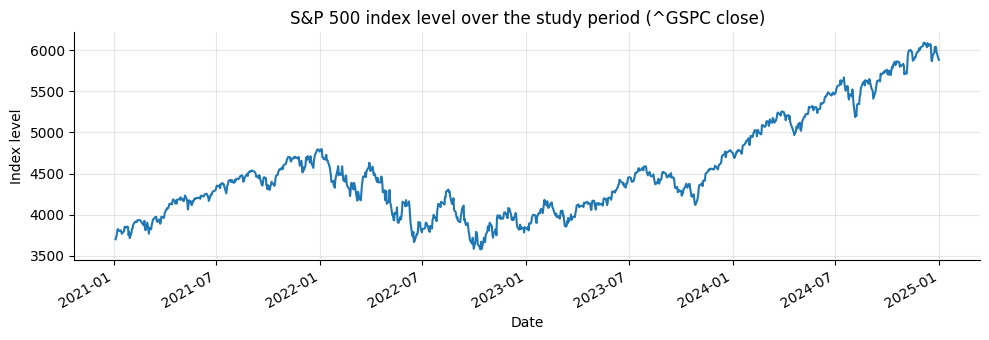

In [ ]:
# TASK 1.1 | Part B: snapshot summary and benchmark context
print("Snapshot retrieved (UTC):", info["retrieved_utc"])
print("Price source:", info["price_source"])
print("Tickers in the Wikipedia list:", len(TICKERS), "| price panel (dates x tickers):", panels["close"].shape)
print("Date range:", panels["close"].index.min().date(), "to", panels["close"].index.max().date())
print("Tickers changed by the dot->hyphen rule:", constituents.loc[constituents["wiki_symbol"] != constituents["ticker"], ["wiki_symbol", "ticker"]].values.tolist())
print("Sector counts:", constituents["sector"].value_counts().to_dict())
print("Tickers with no price data at all in the study period:", [t for t in ALL if panels["close"][t].notna().sum() == 0])
print("Raw file checksums:", info["md5"])

panels["close"][BENCH].dropna().plot(figsize=(10, 3.5), title="S&P 500 index level over the study period (^GSPC close)")
plt.ylabel("Index level")
save_fig("fig01_benchmark_level")

In [ ]:
# TASK 1.2 | Part A: benchmark calendar, per-share quality checks, exclusion rules and the inclusion/exclusion log
trading_days = panels["close"][BENCH].dropna().index          # the benchmark's own dates are the reference trading calendar
n_days = len(trading_days)
check("benchmark calendar has no duplicate dates and is sorted", trading_days.is_unique and trading_days.is_monotonic_increasing)
check("benchmark prices are positive", (panels["close"][BENCH].dropna() > 0).all() and (panels["adj_close"][BENCH].dropna() > 0).all())
check("benchmark dates lie inside the study period", trading_days.min() >= pd.Timestamp(START) and trading_days.max() < pd.Timestamp(END))
check("no duplicate dates in the saved price data", panels["close"].index.is_unique)
print(f"Benchmark calendar: {n_days} trading days, {trading_days[0].date()} to {trading_days[-1].date()}")
print("Trading days per year:", trading_days.year.value_counts().sort_index().to_dict())
print("Duplicate dates dropped at download time:", info.get("duplicate_dates_dropped", "n/a"))

# Align every share to the benchmark calendar. Missing values stay missing (nothing is filled).
close = panels["close"].reindex(trading_days)[TICKERS]
adj = panels["adj_close"].reindex(trading_days)[TICKERS]
vol = panels["volume"].reindex(trading_days)[TICKERS]
divs = panels["dividends"].reindex(trading_days)[TICKERS].fillna(0)      # action tables: no event recorded = 0 (not a price fill)
splits = panels["splits"].reindex(trading_days)[TICKERS].fillna(0)
check("every share date is a benchmark trading date",
      len(panels["close"][TICKERS].dropna(how="all").index.difference(trading_days)) == 0, hard=False)

def internal_gaps(df):      # missing values BETWEEN a share's first and last valid date
    return df.apply(lambda s: int(s.loc[s.first_valid_index():s.last_valid_index()].isna().sum()) if s.notna().any() else 0)

chk = pd.DataFrame(index=TICKERS)
chk["first_valid"] = pd.to_datetime(close.apply(lambda s: s.first_valid_index()))
chk["last_valid"] = pd.to_datetime(close.apply(lambda s: s.last_valid_index()))
chk["n_valid"] = close.notna().sum()
chk["gaps"] = internal_gaps(close) + internal_gaps(adj) + internal_gaps(vol)
chk["nonpositive_price_days"] = ((close <= 0) | (adj <= 0)).sum()
chk["negative_volume_days"] = (vol < 0).sum()
chk["zero_volume_days"] = (vol == 0).sum()
check("Close, Adj Close and Volume have the same number of valid values for every share",
      ((close.notna().sum() == adj.notna().sum()) & (close.notna().sum() == vol.notna().sum())).all(), hard=False)

def reasons(r):
    if r["n_valid"] == 0:
        return "No price data in study period"
    out = []
    if r["first_valid"] > trading_days[0] or r["last_valid"] < trading_days[-1]:
        out.append("Incomplete history (does not cover full study period)")
    if r["gaps"] > 0:
        out.append("Missing values inside history")
    if r["nonpositive_price_days"] > 0:
        out.append("Non-positive price")
    if r["negative_volume_days"] > 0 or r["zero_volume_days"] > 0:
        out.append("Volume error (zero or negative volume)")
    return "; ".join(out)

chk["exclusion_reason"] = chk.apply(reasons, axis=1)
chk["included"] = chk["exclusion_reason"].eq("")
inclusion_log = constituents.set_index("ticker")[["company", "sector", "Date added"]].join(chk)
inclusion_log.to_csv(f"{DATA_DIR}/inclusion_exclusion_log.csv")
included = inclusion_log.index[inclusion_log["included"]].tolist()

print(f"\nIncluded: {len(included)}   Excluded: {int((~inclusion_log['included']).sum())}")
print(inclusion_log.loc[~inclusion_log["included"], "exclusion_reason"].value_counts().to_string())
print(inclusion_log.loc[~inclusion_log["included"], ["company", "Date added", "first_valid", "n_valid", "zero_volume_days", "exclusion_reason"]].to_string())

# Retained shares: complete, positive, identical calendar
c_inc, a_inc, v_inc = close[included], adj[included], vol[included]
check("retained shares have complete histories on the benchmark calendar", (c_inc.notna().all() & a_inc.notna().all() & v_inc.notna().all()).all())
check("retained shares have positive prices and volumes", ((c_inc > 0) & (a_inc > 0) & (v_inc > 0)).all().all())

# Observation date for RFM: final trading date on which the benchmark and every retained share have data
OBS_DATE = pd.concat([c_inc, a_inc, v_inc], axis=1).dropna(how="any").index.max()
print("Observation date (final common completed trading date):", OBS_DATE.date())

PASSED: benchmark calendar has no duplicate dates and is sorted
PASSED: benchmark prices are positive
PASSED: benchmark dates lie inside the study period
PASSED: no duplicate dates in the saved price data
Benchmark calendar: 1005 trading days, 2021-01-04 to 2024-12-31
Trading days per year: {2021: 252, 2022: 251, 2023: 250, 2024: 252}
Duplicate dates dropped at download time: 0
PASSED: every share date is a benchmark trading date
PASSED: Close, Adj Close and Volume have the same number of valid values for every share

Included: 486   Excluded: 17
exclusion_reason
Incomplete history (does not cover full study period)    10
No price data in study period                             5
Volume error (zero or negative volume)                    2
                     company  Date added first_valid  n_valid  zero_volume_days                                       exclusion_reason
ticker                                                                                                             

In [ ]:
# TASK 1.2 | Part A2: OHLC consistency check on the retained shares (High >= Low; Open and Close inside the day's range)
o_inc = panels["open"].reindex(trading_days)[included]
h_inc = panels["high"].reindex(trading_days)[included]
l_inc = panels["low"].reindex(trading_days)[included]
eps = 1e-6                                              # tolerance for floating-point rounding
bad = ((h_inc < l_inc * (1 - eps)) | (o_inc > h_inc * (1 + eps)) | (o_inc < l_inc * (1 - eps))
       | (c_inc > h_inc * (1 + eps)) | (c_inc < l_inc * (1 - eps)))
rows = [(t, d.date().isoformat(), float(o_inc.at[d, t]), float(h_inc.at[d, t]), float(l_inc.at[d, t]), float(c_inc.at[d, t]),
         bool(o_inc.at[d, t] > h_inc.at[d, t] * (1 + eps) or o_inc.at[d, t] < l_inc.at[d, t] * (1 - eps)),
         bool(c_inc.at[d, t] > h_inc.at[d, t] * (1 + eps) or c_inc.at[d, t] < l_inc.at[d, t] * (1 - eps)))
        for t in bad.columns for d in bad.index[bad[t]]]
ohlc_anomalies = pd.DataFrame(rows, columns=["ticker", "date", "open", "high", "low", "close", "open_outside_range", "close_outside_range"])
ohlc_anomalies.to_csv(f"{DATA_DIR}/ohlc_anomalies.csv", index=False)

print(f"OHLC anomalies among retained shares: {len(ohlc_anomalies)} of {bad.size} share-days ({100 * len(ohlc_anomalies) / bad.size:.5f}%)")
print(ohlc_anomalies.to_string(index=False) if len(ohlc_anomalies) else "none")
check("OHLC anomalies are rare (fewer than 0.01% of share-days)", len(ohlc_anomalies) < 0.0001 * bad.size, hard=False)
print("Close-outside-range anomalies (these would matter, because Close drives returns and Monetary):", int(ohlc_anomalies["close_outside_range"].sum()) if len(ohlc_anomalies) else 0)
print("Open-only anomalies are harmless here: Open is not used in any feature.")

OHLC anomalies among retained shares: 1 of 488430 share-days (0.00020%)
ticker       date       open       high        low      close  open_outside_range  close_outside_range
  HUBB 2021-05-05 195.979996 198.639999 196.210007 198.130005                True                False
PASSED: OHLC anomalies are rare (fewer than 0.01% of share-days)
Close-outside-range anomalies (these would matter, because Close drives returns and Monetary): 0
Open-only anomalies are harmless here: Open is not used in any feature.


FERG: 27 zero-volume days of 1005 | first 2021-01-07, last 2021-03-05 | median volume on other days 803,550 | adjusted price unchanged on 100% of zero-volume days
SW: 424 zero-volume days of 1005 | first 2021-01-05, last 2024-07-05 | median volume on other days 600 | adjusted price unchanged on 99% of zero-volume days


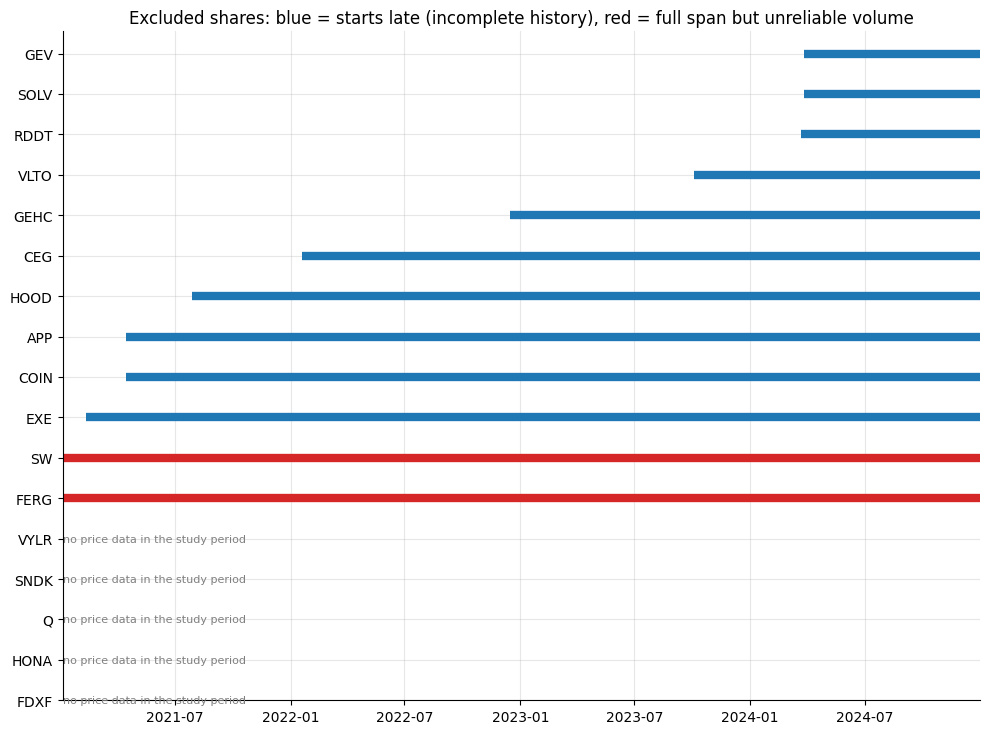

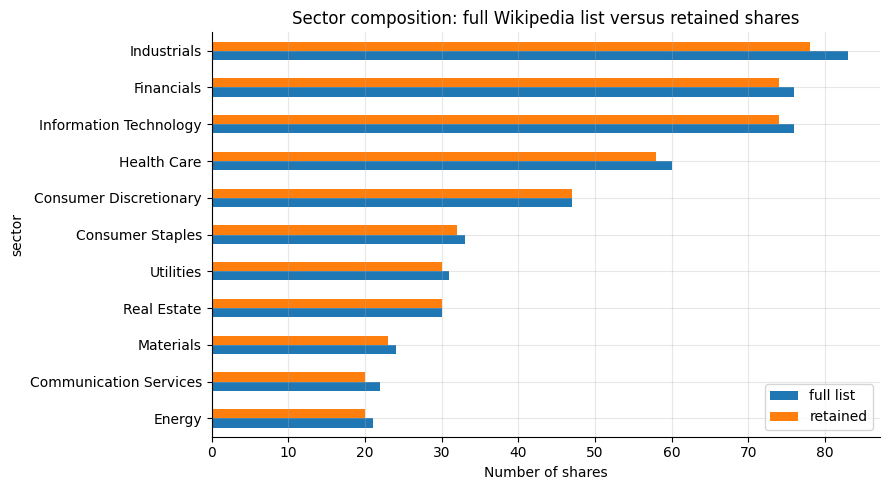

                        full list  retained  pct_excluded
sector                                                   
Industrials                    83        78           6.0
Information Technology         76        74           2.6
Financials                     76        74           2.6
Health Care                    60        58           3.3
Consumer Discretionary         47        47           0.0
Consumer Staples               33        32           3.0
Utilities                      31        30           3.2
Real Estate                    30        30           0.0
Materials                      24        23           4.2
Communication Services         22        20           9.1
Energy                         21        20           4.8


In [ ]:
# TASK 1.2 | Part B: evidence behind the exclusions (zero-volume shares) and two diagrams
# Shares excluded for volume errors: what do their zero-volume days look like?
for t in chk.index[chk["zero_volume_days"] > 0]:
    z = vol[t] == 0
    unchanged = 100 * (adj[t].pct_change(fill_method=None)[z] == 0).mean()
    print(f"{t}: {int(z.sum())} zero-volume days of {int(vol[t].notna().sum())} | first {z[z].index[0].date()}, last {z[z].index[-1].date()} | "
          f"median volume on other days {vol[t][~z].median():,.0f} | adjusted price unchanged on {unchanged:.0f}% of zero-volume days")

# Diagram: history coverage of the excluded shares
ex = inclusion_log.loc[~inclusion_log["included"]].sort_values("first_valid", na_position="first")
fig, ax = plt.subplots(figsize=(10, 0.35 * len(ex) + 1.5))
for y, (t, r) in enumerate(ex.iterrows()):
    if r["n_valid"] == 0:
        ax.text(trading_days[0], y, "no price data in the study period", va="center", fontsize=8, color="grey")
    else:
        colour = "tab:red" if "Volume error" in r["exclusion_reason"] else "tab:blue"
        ax.hlines(y, r["first_valid"], r["last_valid"], color=colour, linewidth=6)
ax.set_yticks(range(len(ex)))
ax.set_yticklabels(ex.index)
ax.set_xlim(trading_days[0], trading_days[-1])
ax.set_title("Excluded shares: blue = starts late (incomplete history), red = full span but unreliable volume")
save_fig("fig02_excluded_shares_coverage")

# Diagram: sector composition before and after the exclusions
sector_view = pd.DataFrame({"full list": constituents["sector"].value_counts(),
                            "retained": inclusion_log.loc[included, "sector"].value_counts()}).fillna(0).astype(int)
sector_view.sort_values("full list").plot.barh(figsize=(9, 5), title="Sector composition: full Wikipedia list versus retained shares")
plt.xlabel("Number of shares")
save_fig("fig03_sector_composition")
sector_view["pct_excluded"] = (100 * (1 - sector_view["retained"] / sector_view["full list"])).round(1)
print(sector_view.to_string())

                                retained shares  percent
joined before the study window              414     85.2
joined during the study window               47      9.7
joined after the study window                25      5.1
missing date                                  0      0.0

Most recently added retained shares (not index members at any time in the study window):
                   company  Date added
ticker                                
OKTA            Okta, Inc.  2026-11-04
TWLO                Twilio  2026-10-06
BE            Bloom Energy  2026-09-21
ILMN        Illumina, Inc.  2026-09-21
P                 Everpure  2026-09-21
FLEX             Flex Ltd.  2026-06-22
MRVL    Marvell Technology  2026-06-22
VEEV         Veeva Systems  2026-05-07
CASY               Casey's  2026-04-09
VRT                 Vertiv  2026-03-23

Note: companies removed from the S&P 500 during the study window are not in today's list, so they are missing from this dataset (not counted).


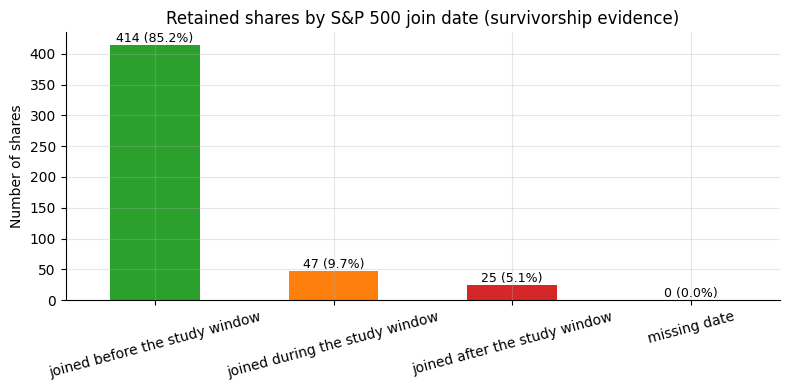

In [ ]:
# TASK 1.1 | Part C: survivorship-bias evidence
# Wikipedia 'Date added' is the date a share joined the S&P 500 (not its listing date). It shows how many retained shares were
# NOT index members for part or all of the study window. Companies removed from the index during 2021-2024 are missing from the data altogether.
added = pd.to_datetime(inclusion_log["Date added"], errors="coerce")
period = pd.Series("missing date", index=inclusion_log.index)
period[added < pd.Timestamp(START)] = "joined before the study window"
period[(added >= pd.Timestamp(START)) & (added < pd.Timestamp(END))] = "joined during the study window"
period[added >= pd.Timestamp(END)] = "joined after the study window"
order = ["joined before the study window", "joined during the study window", "joined after the study window", "missing date"]
counts = period[inclusion_log["included"]].value_counts().reindex(order).fillna(0).astype(int)
print(pd.DataFrame({"retained shares": counts, "percent": (100 * counts / len(included)).round(1)}).to_string())

late = inclusion_log.loc[inclusion_log["included"] & (added >= pd.Timestamp(END)), ["company", "Date added"]].assign(_d=added).sort_values("_d", ascending=False)
print("\nMost recently added retained shares (not index members at any time in the study window):")
print(late.drop(columns="_d").head(10).to_string())
print("\nNote: companies removed from the S&P 500 during the study window are not in today's list, so they are missing from this dataset (not counted).")

ax = counts.plot.bar(figsize=(8, 4), color=["tab:green", "tab:orange", "tab:red", "grey"], title="Retained shares by S&P 500 join date (survivorship evidence)")
for i, v in enumerate(counts):
    ax.text(i, v, f"{v} ({100 * v / len(included):.1f}%)", ha="center", va="bottom", fontsize=9)
plt.ylabel("Number of shares"); plt.xticks(rotation=15)
save_fig("fig04_survivorship_join_dates")

Retained shares with a split-type event: 53 | events: 61
Retained shares paying a dividend: 392 | dividend events: 6024

Events tested by type: {'ordinary split': 44, 'fractional ratio (spin-off style)': 17}
PASSED: no ordinary split has an unadjusted Close
PASSED: no ordinary split has an unadjusted Volume


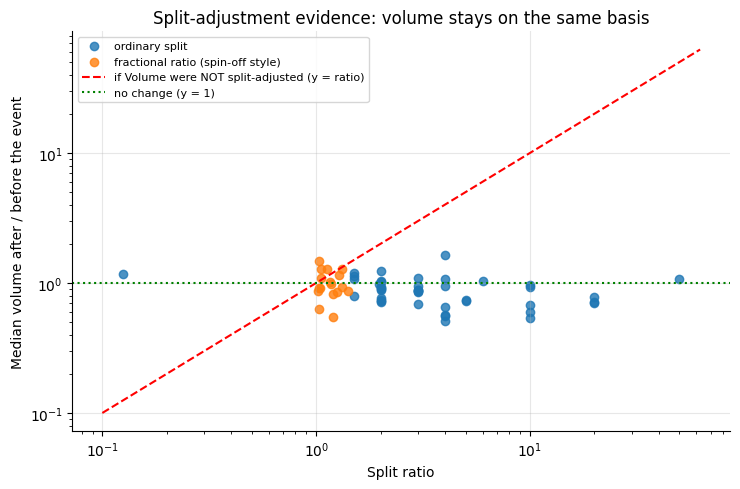

PASSED: Adj Close and Close returns differ only on dividend or split days
PASSED: Adj Close never exceeds Close
Adj Close / Close on the last date (below 1 = later dividends are adjusted into the whole history):
count    486.0000
mean       0.9671
std        0.0286
min        0.8740
25%        0.9490
50%        0.9729
75%        0.9902
max        1.0000

Daily moves beyond +/-40% (ticker, date, return, corporate action that day?): 8
[('BE', '2024-11-15', 0.592, False), ('CVNA', '2022-08-05', 0.401, False), ('CVNA', '2022-12-07', -0.429, False), ('CVNA', '2023-01-12', 0.46, False), ('CVNA', '2023-06-08', 0.56, False), ('CVNA', '2023-07-19', 0.402, False), ('DXCM', '2024-07-26', -0.407, False), ('GL', '2024-04-11', -0.531, False)]
Longest run of unchanged adjusted prices: 2 days | shares with 5 or more: 0
PASSED: no retained share has a frozen price feed (5+ unchanged days in a row)


True

In [ ]:
# TASK 1.2 | Part C: corporate actions (splits, spin-off style adjustments, dividends) and price-integrity checks on retained shares
dv, spl = divs[included], splits[included]
print("Retained shares with a split-type event:", int((spl > 0).any().sum()), "| events:", int((spl > 0).sum().sum()))
print("Retained shares paying a dividend:", int((dv > 0).any().sum()), "| dividend events:", int((dv > 0).sum().sum()))

# (1) Are Close and Volume on the same split-adjusted basis? Compare the 20 sessions before and after each event
rows = []
for t in spl.columns[(spl > 0).any()]:
    for d in spl.index[spl[t] > 0]:
        i = trading_days.get_loc(d)
        if i < 5 or n_days - (i + 1) < 5:
            continue                                                   # too close to the edge of the data to test
        before, after = slice(max(i - 20, 0), i), slice(i + 1, min(i + 21, n_days))
        value = c_inc[t] * v_inc[t]
        rows.append({"ticker": t, "date": d, "ratio": float(spl.at[d, t]),
                     "close_ret": float(c_inc[t].iloc[i] / c_inc[t].iloc[i - 1] - 1),
                     "vol_after_before": float(v_inc[t].iloc[after].median() / v_inc[t].iloc[before].median()),
                     "value_after_before": float(value.iloc[after].median() / value.iloc[before].median())})
sp = pd.DataFrame(rows)
if len(sp):
    # ordinary splits (ratio >= 1.5 or <= 0.67) can be tested; fractional ratios (about 1.02-1.4) look like spin-offs and have little test power
    sp["type"] = np.where((sp["ratio"] >= 1.5) | (sp["ratio"] <= 0.67), "ordinary split", "fractional ratio (spin-off style)")
    ordinary = sp["type"] == "ordinary split"
    # If Close were unadjusted, the split-day return would match the raw drop (1/ratio - 1); if Volume were unadjusted, volume after/before would be near the ratio
    sp["close_unadjusted"] = ordinary & ((sp["close_ret"] - (1 / sp["ratio"] - 1)).abs() < 0.10)
    sp["volume_unadjusted"] = ordinary & ((np.log(sp["vol_after_before"]) - np.log(sp["ratio"])).abs() < np.log(sp["vol_after_before"]).abs())
    sp.to_csv(f"{DATA_DIR}/corporate_action_split_check.csv", index=False)
    print("\nEvents tested by type:", sp["type"].value_counts().to_dict())
    check("no ordinary split has an unadjusted Close", sp["close_unadjusted"].sum() == 0, hard=False)
    check("no ordinary split has an unadjusted Volume", sp["volume_unadjusted"].sum() == 0, hard=False)

    fig, ax = plt.subplots(figsize=(7.5, 5))
    for typ, colour in [("ordinary split", "tab:blue"), ("fractional ratio (spin-off style)", "tab:orange")]:
        s = sp[sp["type"] == typ]
        ax.scatter(s["ratio"], s["vol_after_before"], label=typ, color=colour, alpha=0.8)
    xs = np.logspace(np.log10(sp["ratio"].min() * 0.8), np.log10(sp["ratio"].max() * 1.25), 50)
    ax.plot(xs, xs, "r--", label="if Volume were NOT split-adjusted (y = ratio)")
    ax.axhline(1, color="green", ls=":", label="no change (y = 1)")
    ax.set(xscale="log", yscale="log", xlabel="Split ratio", ylabel="Median volume after / before the event",
           title="Split-adjustment evidence: volume stays on the same basis")
    ax.legend(fontsize=8)
    save_fig("fig05_split_adjustment_evidence")

# (2) Do Adj Close and Close differ only on dividend / split days?
r_c, r_a = c_inc.pct_change(fill_method=None), a_inc.pct_change(fill_method=None)
action_day = (dv > 0) | (spl > 0)
unexplained = ((r_a - r_c).abs() > 1e-4) & ~action_day
check("Adj Close and Close returns differ only on dividend or split days", unexplained.sum().sum() == 0, hard=False)
check("Adj Close never exceeds Close", ((a_inc / c_inc) > 1.0001).sum().sum() == 0, hard=False)
print("Adj Close / Close on the last date (below 1 = later dividends are adjusted into the whole history):")
print((a_inc / c_inc).iloc[-1].describe().round(4).to_string())

# (3) Extreme daily moves and frozen prices
ext = r_a.abs() > 0.40
ext_rows = [(t, d.date().isoformat(), round(float(r_a.at[d, t]), 3), bool(action_day.at[d, t])) for t in r_a.columns for d in r_a.index[ext[t]]]
print(f"\nDaily moves beyond +/-40% (ticker, date, return, corporate action that day?): {len(ext_rows)}")
print(ext_rows[:20])

def longest_run(s):
    g = (s != s.shift()).cumsum()
    return int(s.groupby(g).sum().max())

stale = (r_a == 0).apply(longest_run)
print("Longest run of unchanged adjusted prices:", int(stale.max()), "days | shares with 5 or more:", int((stale >= 5).sum()))
check("no retained share has a frozen price feed (5+ unchanged days in a row)", (stale >= 5).sum() == 0, hard=False)

In [ ]:
# TASK 1.2 | Part D: Friday-ending weekly prices, incomplete-week exclusion and return-date alignment
# Last available trading-day adjusted close in each Friday-ending week (retained shares and benchmark together)
adj_all = pd.concat([a_inc, panels["adj_close"][BENCH].reindex(trading_days)], axis=1)
check("no missing adjusted prices before resampling", adj_all.notna().all().all())
weekly_px = adj_all.resample("W-FRI").last()

# Independent check: each weekly price equals the adjusted close on that week's final trading day
last_day = trading_days.to_series().groupby(pd.Grouper(freq="W-FRI")).max().dropna()
check_px = adj_all.loc[last_day.values].set_axis(last_day.index)
pd.testing.assert_frame_equal(check_px.loc[weekly_px.index], weekly_px, check_names=False, check_freq=False)
print("PASSED: weekly prices equal the final trading-day adjusted close of each week")

# Exclude incomplete first/last calendar weeks: the week's Monday must be on or after the start, its Friday label not after the last data date
labels = weekly_px.index
is_complete = ((labels - pd.Timedelta(days=4)) >= pd.Timestamp(START)) & (labels <= trading_days[-1])
print("Weekly labels dropped as incomplete calendar weeks:", [d.date().isoformat() for d in labels[~is_complete]])
weekly_px = weekly_px.loc[is_complete]

# Holiday-shortened weeks are retained
sessions_per_week = trading_days.to_series().resample("W-FRI").count().reindex(weekly_px.index)
print(f"Holiday-shortened weeks retained (fewer than 5 sessions): {int((sessions_per_week < 5).sum())} | sessions per week: {sessions_per_week.value_counts().sort_index().to_dict()}")
check("Good Friday 2021 week uses Thursday's close",
      np.isclose(weekly_px.loc[pd.Timestamp("2021-04-02"), BENCH], adj_all.loc[pd.Timestamp("2021-04-01"), BENCH]), hard=False)

# Weekly return = this week's adjusted close / previous week's adjusted close - 1 (no filling, no multi-week returns)
check("weekly prices: no gaps, Fridays only, unique labels", weekly_px.notna().all().all() and (weekly_px.index.dayofweek == 4).all() and weekly_px.index.is_unique)
check("consecutive weeks: no week skipped", (weekly_px.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all())
weekly_ret = weekly_px.pct_change(fill_method=None).iloc[1:]
check("weekly returns complete (no missing values)", weekly_ret.notna().all().all())
check("shares and benchmark share identical week labels", weekly_ret.index.equals(weekly_px.index[1:]))
t0 = included[0]
check("weekly return formula matches a manual calculation", np.allclose(weekly_px[t0].iloc[1:].values / weekly_px[t0].iloc[:-1].values - 1, weekly_ret[t0].values))

N_WEEKS = len(weekly_ret)
print(f"\nWeekly price labels: {len(weekly_px)} | aligned weekly return observations: {N_WEEKS}")
print(f"First return week: {weekly_ret.index[0].date()} | last return week: {weekly_ret.index[-1].date()} | shares x weeks: {weekly_ret[included].shape}")
weekly_px.to_csv(f"{DATA_DIR}/weekly_adj_close.csv")
weekly_ret.to_csv(f"{DATA_DIR}/weekly_returns.csv")

PASSED: no missing adjusted prices before resampling
PASSED: weekly prices equal the final trading-day adjusted close of each week
Weekly labels dropped as incomplete calendar weeks: ['2025-01-03']
Holiday-shortened weeks retained (fewer than 5 sessions): 37 | sessions per week: {4: 37, 5: 171}
PASSED: Good Friday 2021 week uses Thursday's close
PASSED: weekly prices: no gaps, Fridays only, unique labels
PASSED: consecutive weeks: no week skipped
PASSED: weekly returns complete (no missing values)
PASSED: shares and benchmark share identical week labels
PASSED: weekly return formula matches a manual calculation

Weekly price labels: 208 | aligned weekly return observations: 207
First return week: 2021-01-15 | last return week: 2024-12-27 | shares x weeks: (207, 486)


In [ ]:
# TASK 1.3.1 | Mean weekly return per share (arithmetic mean of the Friday-ending weekly returns)
share_ret, bench_ret = weekly_ret[included], weekly_ret[BENCH]
mean_ret = share_ret.mean().rename("mean_weekly_return")
px = weekly_px[included].to_numpy()
check("mean weekly return equals an independent numpy recalculation", np.allclose(mean_ret.to_numpy(), (px[1:] / px[:-1] - 1).mean(axis=0)))
check("every share has the same number of weekly observations", share_ret.count().nunique() == 1 and share_ret.count().iloc[0] == N_WEEKS)

# Worked example for one share
ex = "AAPL" if "AAPL" in included else included[0]
w = weekly_px[ex]
print(f"Worked example: {ex}")
print(pd.DataFrame({"week_end": w.index[:4].date, "adj_close": w.iloc[:4].round(4).values,
                    "weekly_return": w.pct_change(fill_method=None).iloc[:4].round(5).values}).to_string(index=False))
print(f"Mean of the {N_WEEKS} weekly returns = {mean_ret[ex]:.5f} ({100 * mean_ret[ex]:.3f}% per week); the first week has no previous week, so it has no return\n")

print((100 * mean_ret).describe().round(3).rename("mean weekly return, % per week").to_string())
print("Skewness:", round(float(mean_ret.skew()), 3), "| excess kurtosis:", round(float(mean_ret.kurt()), 3))
print("Benchmark (^GSPC) mean weekly return:", round(100 * float(bench_ret.mean()), 3), "% per week")
names = inclusion_log["company"]
print("\nHighest:", [(t, names[t], round(float(100 * mean_ret[t]), 3)) for t in mean_ret.nlargest(5).index])
print("Lowest: ", [(t, names[t], round(float(100 * mean_ret[t]), 3)) for t in mean_ret.nsmallest(5).index])

# Limit of the arithmetic mean: it can never be below the compound (geometric) weekly growth rate, and the gap grows with volatility
geo = (weekly_px[included].iloc[-1] / weekly_px[included].iloc[0]) ** (1 / N_WEEKS) - 1
gap = mean_ret - geo
check("arithmetic mean is never below the geometric mean", (gap > -1e-10).all())
print("Arithmetic minus geometric weekly mean (percentage points): median", round(100 * float(gap.median()), 3), "| max", round(100 * float(gap.max()), 3),
      "| correlation with half the weekly variance:", round(float(np.corrcoef(gap, share_ret.var() / 2)[0, 1]), 3))

PASSED: mean weekly return equals an independent numpy recalculation
PASSED: every share has the same number of weekly observations
Worked example: AAPL
  week_end  adj_close  weekly_return
2021-01-08   128.0981            NaN
2021-01-15   123.3351       -0.03718
2021-01-22   134.9080        0.09383
2021-01-29   128.0108       -0.05113
Mean of the 207 weekly returns = 0.00393 (0.393% per week); the first week has no previous week, so it has no return

count    486.000
mean       0.286
std        0.265
min       -0.447
25%        0.118
50%        0.262
75%        0.421
max        1.777
Skewness: 0.868 | excess kurtosis: 3.019
Benchmark (^GSPC) mean weekly return: 0.24 % per week

Highest: [('SMCI', 'Supermicro', 1.777), ('NVDA', 'Nvidia', 1.362), ('VRT', 'Vertiv', 1.258), ('VST', 'Vistra Corp.', 1.139), ('FIX', 'Comfort Systems USA', 1.13)]
Lowest:  [('EL', 'Estée Lauder Companies (The)', -0.447), ('BAX', 'Baxter International', -0.38), ('DG', 'Dollar General', -0.352), ('PYPL', 'PayPal

In [ ]:
# TASK 1.3.2 | Weekly beta per share = covariance(share, benchmark) / variance(benchmark), full period
check("aligned weekly observations: identical labels, no gaps",
      share_ret.index.equals(bench_ret.index) and share_ret.notna().all().all() and bench_ret.notna().all())
n = len(bench_ret)
print(f"Aligned weekly observations used for every beta: {n} ({bench_ret.index[0].date()} to {bench_ret.index[-1].date()})")

beta = (share_ret.apply(lambda s: s.cov(bench_ret)) / bench_ret.var()).rename("weekly_beta")      # sample covariance / sample variance
x, Y = bench_ret.to_numpy(), share_ret.to_numpy()
check("beta equals the numpy covariance formula",
      np.allclose(beta.to_numpy(), np.array([np.cov(Y[:, j], x)[0, 1] for j in range(Y.shape[1])]) / np.var(x, ddof=1)))
check("beta equals a fitted regression slope", np.allclose(beta.to_numpy(), [np.polyfit(x, Y[:, j], 1)[0] for j in range(Y.shape[1])]))
check("the benchmark's own beta equals 1", np.isclose(bench_ret.cov(bench_ret) / bench_ret.var(), 1.0))
check("benchmark Adj Close equals Close (a price index has no dividends)",
      np.allclose(panels["adj_close"][BENCH].dropna(), panels["close"][BENCH].dropna()), hard=False)

ex = "AAPL" if "AAPL" in included else included[0]
print(f"\nWorked example: {ex} | cov(share, benchmark) = {share_ret[ex].cov(bench_ret):.6f} | var(benchmark) = {bench_ret.var():.6f} | beta = {beta[ex]:.3f}")
print("\nWeekly beta summary:")
print(beta.describe().round(3).to_string())
print("Skewness:", round(float(beta.skew()), 3), "| excess kurtosis:", round(float(beta.kurt()), 3))
print("Share with beta > 1:", round(float((beta > 1).mean()), 3), "| beta < 0.5:", int((beta < 0.5).sum()), "| beta < 0:", int((beta < 0).sum()))
print("Highest:", [(t, names[t], round(float(beta[t]), 3)) for t in beta.nlargest(5).index])
print("Lowest: ", [(t, names[t], round(float(beta[t]), 3)) for t in beta.nsmallest(5).index])

# Estimation limits: explanatory power, precision (standard error) and stability between the two halves of the period
r = share_ret.corrwith(bench_ret)
se = beta.abs() * np.sqrt((1 - r ** 2) / (r ** 2 * (n - 2)))
print(f"\nCorrelation with the benchmark: median {r.median():.3f} | R-squared: median {(r ** 2).median():.3f}")
print(f"Standard error of beta: median {se.median():.3f} | max {se.max():.3f} | share of betas whose 95% interval contains 1: {((beta - 1).abs() < 1.96 * se).mean():.3f}")
h = n // 2
b1 = share_ret.iloc[:h].apply(lambda s: s.cov(bench_ret.iloc[:h])) / bench_ret.iloc[:h].var()
b2 = share_ret.iloc[h:].apply(lambda s: s.cov(bench_ret.iloc[h:])) / bench_ret.iloc[h:].var()
print(f"Beta in the first {h} weeks versus the last {n - h} weeks: correlation {b1.corr(b2):.3f} | median absolute change {(b2 - b1).abs().median():.3f}")

feat = pd.DataFrame({"n_weekly_obs": share_ret.count(), "mean_weekly_return": mean_ret, "weekly_beta": beta})
feat.to_csv(f"{DATA_DIR}/features_return_beta.csv")

PASSED: aligned weekly observations: identical labels, no gaps
Aligned weekly observations used for every beta: 207 (2021-01-15 to 2024-12-27)
PASSED: beta equals the numpy covariance formula
PASSED: beta equals a fitted regression slope
PASSED: the benchmark's own beta equals 1
PASSED: benchmark Adj Close equals Close (a price index has no dividends)

Worked example: AAPL | cov(share, benchmark) = 0.000578 | var(benchmark) = 0.000492 | beta = 1.175

Weekly beta summary:
count    486.000
mean       0.974
std        0.407
min        0.055
25%        0.667
50%        0.951
75%        1.180
max        3.779
Skewness: 1.104 | excess kurtosis: 4.471
Share with beta > 1: 0.444 | beta < 0.5: 59 | beta < 0: 0
Highest: [('CVNA', 'Carvana', 3.779), ('XYZ', 'Block, Inc.', 2.505), ('COHR', 'Coherent Corp.', 2.139), ('NVDA', 'Nvidia', 2.126), ('TWLO', 'Twilio', 2.073)]
Lowest:  [('GIS', 'General Mills', 0.055), ('SJM', 'J.M. Smucker Company (The)', 0.176), ('MRK', 'Merck & Co.', 0.198), ('BMY', 'Br

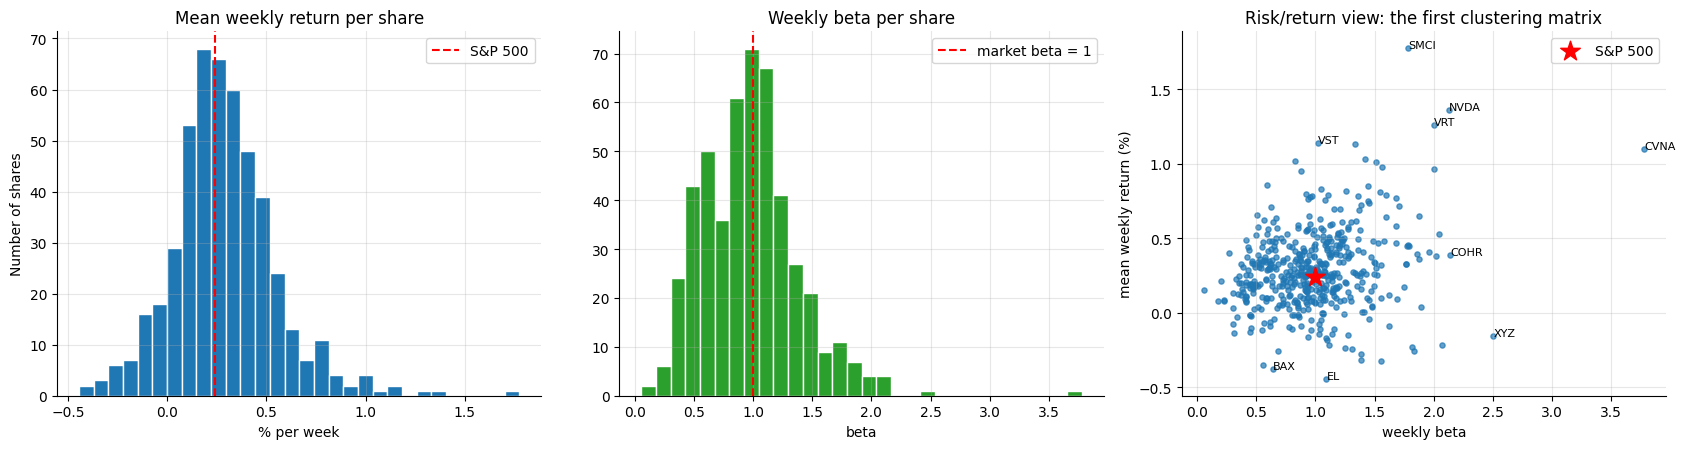

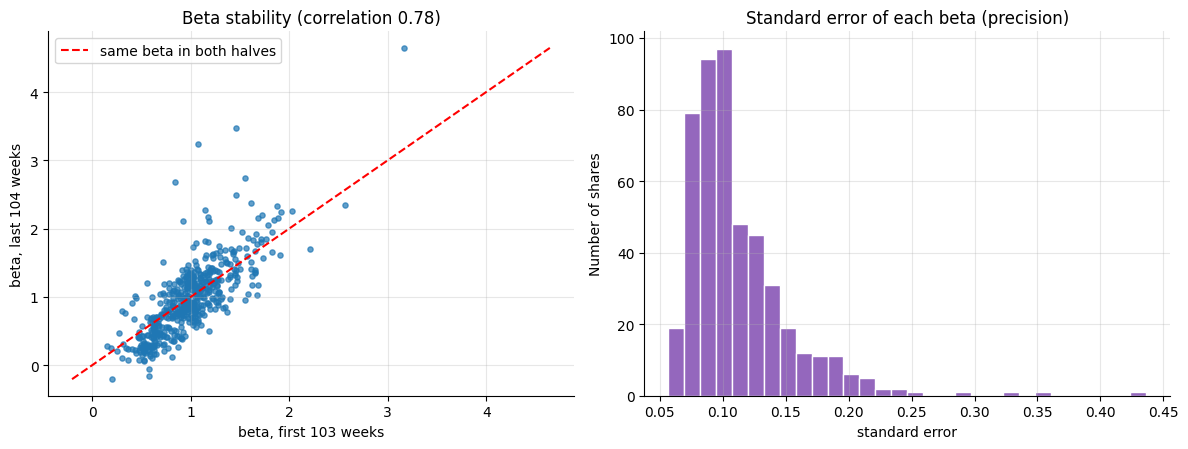

In [ ]:
# TASK 1.3 | Part C: diagrams - the risk/return view and the limits of beta
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].hist(100 * mean_ret, bins=30, color="tab:blue", edgecolor="white")
ax[0].axvline(100 * bench_ret.mean(), color="red", ls="--", label="S&P 500")
ax[0].set(title="Mean weekly return per share", xlabel="% per week", ylabel="Number of shares"); ax[0].legend()
ax[1].hist(beta, bins=30, color="tab:green", edgecolor="white")
ax[1].axvline(1, color="red", ls="--", label="market beta = 1")
ax[1].set(title="Weekly beta per share", xlabel="beta"); ax[1].legend()
ax[2].scatter(beta, 100 * mean_ret, s=14, alpha=0.7)
ax[2].scatter([1], [100 * bench_ret.mean()], color="red", marker="*", s=220, label="S&P 500", zorder=3)
for t in set(mean_ret.nlargest(4).index) | set(beta.nlargest(4).index) | set(mean_ret.nsmallest(2).index):
    ax[2].annotate(t, (beta[t], 100 * mean_ret[t]), fontsize=8)
ax[2].set(title="Risk/return view: the first clustering matrix", xlabel="weekly beta", ylabel="mean weekly return (%)"); ax[2].legend()
save_fig("fig06_return_and_beta")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(b1, b2, s=14, alpha=0.7)
lim = [min(b1.min(), b2.min()), max(b1.max(), b2.max())]
ax[0].plot(lim, lim, "r--", label="same beta in both halves")
ax[0].set(title=f"Beta stability (correlation {b1.corr(b2):.2f})", xlabel=f"beta, first {h} weeks", ylabel=f"beta, last {n - h} weeks"); ax[0].legend()
ax[1].hist(se, bins=30, color="tab:purple", edgecolor="white")
ax[1].set(title="Standard error of each beta (precision)", xlabel="standard error", ylabel="Number of shares")
save_fig("fig07_beta_stability_and_precision")

PASSED: no missing Close values for the experiment
PASSED: Close-based weekly returns use exactly the same weeks
Mean weekly return, Adj Close basis minus Close basis (percentage points per week):
   dividend payers: median 0.0407, max 0.1516 (n=392)
   non-payers     : max absolute difference 0.000000 (n=94)
Correlation of mean return across the two bases: 0.994
Weekly beta: correlation 0.9999 | Spearman 0.9999 | absolute difference median 0.0013 max 0.0171 | shares moving by more than 0.05: 0


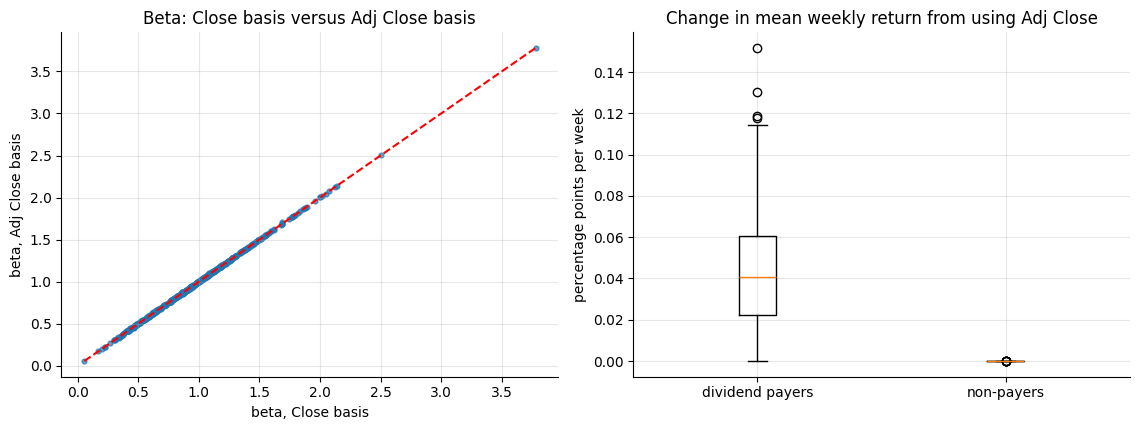

In [ ]:
# EXPERIMENT A (supports TASK 1.3) | Price-basis sensitivity: Close (price return) versus Adj Close (dividend-adjusted)
# The benchmark is a price index; the shares' Adj Close includes dividends. How much does that choice change the two features?
c_all = panels["close"].reindex(trading_days)[included + [BENCH]]
check("no missing Close values for the experiment", c_all.notna().all().all())
ret_close = c_all.resample("W-FRI").last().loc[weekly_px.index].pct_change(fill_method=None).iloc[1:]
check("Close-based weekly returns use exactly the same weeks", ret_close.index.equals(weekly_ret.index))

mean_close = ret_close[included].mean()
beta_close = ret_close[included].apply(lambda s: s.cov(ret_close[BENCH])) / ret_close[BENCH].var()
pays = (dv > 0).any().reindex(included)                  # paid a dividend inside the study window
d_mean = 100 * (mean_ret - mean_close)                   # percentage points per week
d_beta = (beta - beta_close).abs()
print("Mean weekly return, Adj Close basis minus Close basis (percentage points per week):")
print("   dividend payers:", f"median {d_mean[pays].median():.4f}, max {d_mean[pays].max():.4f} (n={int(pays.sum())})")
print("   non-payers     :", f"max absolute difference {d_mean[~pays].abs().max():.6f} (n={int((~pays).sum())})")
print("Correlation of mean return across the two bases:", round(float(mean_ret.corr(mean_close)), 4))
print("Weekly beta: correlation", round(float(beta.corr(beta_close)), 4), "| Spearman", round(float(beta.rank().corr(beta_close.rank())), 4),
      "| absolute difference median", round(float(d_beta.median()), 4), "max", round(float(d_beta.max()), 4),
      "| shares moving by more than 0.05:", int((d_beta > 0.05).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax[0].scatter(beta_close, beta, s=12, alpha=0.7)
lim = [beta.min(), beta.max()]
ax[0].plot(lim, lim, "r--")
ax[0].set(title="Beta: Close basis versus Adj Close basis", xlabel="beta, Close basis", ylabel="beta, Adj Close basis")
ax[1].boxplot([d_mean[pays], d_mean[~pays]])
ax[1].set_xticklabels(["dividend payers", "non-payers"])
ax[1].set(title="Change in mean weekly return from using Adj Close", ylabel="percentage points per week")
save_fig("fig08_experiment_a_price_basis")

In [ ]:
# TASK 1.4 | Part A: the event rule and the R / F / M helper functions, each tested on toy data
def high_volume_flags(volume, window=20, mult=2.0):
    baseline = volume.rolling(window).mean().shift(1)       # mean of the PRECEDING 20 sessions: shift(1) excludes the day being tested
    threshold = mult * baseline                              # calculated separately for every share and every day
    flags = (volume > threshold) & threshold.notna()         # strictly greater than twice the baseline; no baseline = not an event
    return baseline, threshold, flags

def latest_event_days(flag_frame, obs_date):
    """Recency: calendar days from the latest qualifying day on or before obs_date to obs_date (NaN if none, never 0)."""
    f = flag_frame.loc[:obs_date]
    last = pd.to_datetime(f.where(f).apply(lambda s: s.last_valid_index()))
    return (obs_date - last).dt.days

def rfm_at(obs_date):
    """R, F and M for any observation date; F and M use the 60 sessions ending on that date (needs flags, c_inc, v_inc)."""
    pos = trading_days.get_loc(obs_date)
    assert pos >= 59, "fewer than 60 sessions available"
    win = trading_days[pos - 59: pos + 1]
    return pd.DataFrame({"recency_days": latest_event_days(flags, obs_date),
                         "frequency_60d": flags.loc[win].sum(),
                         "monetary_usd": (c_inc * v_inc).loc[win].sum()})

# Event rule: the brief's own example (baseline 1 million -> threshold 2 million)
def toy_flag(last_day):
    return bool(high_volume_flags(pd.Series([1_000_000.0] * 20 + [last_day]))[2].iloc[-1])

check("event rule: 2.5 million against a 1 million baseline qualifies", toy_flag(2_500_000.0) is True)
check("event rule: 1.8 million does not qualify", toy_flag(1_800_000.0) is False)
check("event rule: exactly twice the baseline does not qualify (strictly greater)", toy_flag(2_000_000.0) is False)
check("event rule: just above twice the baseline qualifies", toy_flag(2_000_001.0) is True)
check("event rule: no event without 20 prior sessions", not high_volume_flags(pd.Series([1e6] * 4 + [9e6] + [1e6] * 20))[2].iloc[:20].any())
check("event rule: a day's own volume does not lift its own threshold", high_volume_flags(pd.Series([1e6] * 20 + [2_100_000.0]))[1].iloc[-1] == 2_000_000.0)

# Recency: same day = 0, weekends counted, no event = missing
toy_days = pd.date_range("2024-09-02", "2024-09-20", freq="B")
toy = pd.DataFrame(False, index=toy_days, columns=["same_day", "two_days_ago", "friday_event", "no_event"])
toy.loc[pd.Timestamp("2024-09-20"), "same_day"] = True
toy.loc[pd.Timestamp("2024-09-18"), "two_days_ago"] = True
toy.loc[pd.Timestamp("2024-09-13"), "friday_event"] = True
toy_r = latest_event_days(toy, pd.Timestamp("2024-09-20"))
check("Recency: event on the observation date gives 0; two days earlier gives 2", toy_r["same_day"] == 0 and toy_r["two_days_ago"] == 2)
check("Recency: Friday 13 Sept to Friday 20 Sept is 7 calendar days", toy_r["friday_event"] == 7)
check("Recency: Friday to the next Monday is 3 calendar days (weekend counted)", latest_event_days(toy, pd.Timestamp("2024-09-16"))["friday_event"] == 3)
check("Recency: no event gives a missing value, not zero", np.isnan(toy_r["no_event"]))

# Frequency: seven events = 7; first window day counts; the day before the window does not
tf = pd.DataFrame(False, index=pd.date_range("2024-01-01", periods=80, freq="B"), columns=["seven", "edge_in", "edge_out"])
tw = tf.index[-60:]
tf.loc[tw[[0, 5, 12, 20, 31, 44, 59]], "seven"] = True
tf.loc[tw[0], "edge_in"] = True
tf.loc[tf.index[-61], "edge_out"] = True
tfs = tf.loc[tw].sum()
check("Frequency: seven qualifying days give 7; first window day counts; the day before the window does not",
      tfs["seven"] == 7 and tfs["edge_in"] == 1 and tfs["edge_out"] == 0)

# Monetary: $100 x 2 million shares = $200 million a day; 60 such days = $12 billion
check("Monetary: the brief's example ($100 x 2 million = $200 million a day; 60 days = $12 billion)",
      100.0 * 2_000_000.0 == 200_000_000.0 and sum([100.0 * 2_000_000.0] * 60) == 12_000_000_000.0)

PASSED: event rule: 2.5 million against a 1 million baseline qualifies
PASSED: event rule: 1.8 million does not qualify
PASSED: event rule: exactly twice the baseline does not qualify (strictly greater)
PASSED: event rule: just above twice the baseline qualifies
PASSED: event rule: no event without 20 prior sessions
PASSED: event rule: a day's own volume does not lift its own threshold
PASSED: Recency: event on the observation date gives 0; two days earlier gives 2
PASSED: Recency: Friday 13 Sept to Friday 20 Sept is 7 calendar days
PASSED: Recency: Friday to the next Monday is 3 calendar days (weekend counted)
PASSED: Recency: no event gives a missing value, not zero
PASSED: Frequency: seven qualifying days give 7; first window day counts; the day before the window does not
PASSED: Monetary: the brief's example ($100 x 2 million = $200 million a day; 60 days = $12 billion)


True

In [ ]:
# TASK 1.4 | Part B: event flags, then Recency, Frequency and Monetary for every retained share
baseline, threshold, flags = high_volume_flags(v_inc)
altered = v_inc.copy()
altered.iloc[600:] = altered.iloc[600:] * 10
check("no look-ahead: changing later volumes changes no earlier flag", flags.iloc[:600].equals(high_volume_flags(altered)[2].iloc[:600]))
WIN = trading_days[-60:]
check("the 60-session window ends on the observation date", WIN[-1] == OBS_DATE and len(WIN) == 60)
check("every share has a valid 20-session baseline on all 60 window days", threshold.loc[WIN].notna().all().all())
print(f"Observation date: {OBS_DATE.date()} | 60-session window: {WIN[0].date()} to {WIN[-1].date()} | first testable day for the baseline: {trading_days[20].date()}")
flags.astype(int).to_csv(f"{DATA_DIR}/high_volume_flags.csv")

testable, n_events = int(threshold.notna().sum().sum()), flags.sum()
print(f"\nHigh-volume days flagged: {int(n_events.sum())} of {testable} testable share-days ({100 * n_events.sum() / testable:.2f}%)")
print("Events per share over the full history: median", int(n_events.median()), "| min", int(n_events.min()), "| max", int(n_events.max()))

rfm = rfm_at(OBS_DATE)
recency, frequency, monetary = rfm["recency_days"], rfm["frequency_60d"], rfm["monetary_usd"]

# Independent recalculations
for t in included:                                                       # Recency by a plain loop
    d = flags.index[flags[t].values]
    expected = (OBS_DATE - d.max()).days if len(d) else np.nan
    assert (np.isnan(expected) and np.isnan(recency[t])) or expected == recency[t]
print("PASSED: Recency matches an independent loop recalculation for every share")
V = v_inc.to_numpy()
manual_f = np.zeros(V.shape[1], dtype=int)
for d in WIN:                                                            # Frequency straight from raw volumes, explicit 20-session baseline
    i = trading_days.get_loc(d)
    manual_f += (V[i] > 2 * V[i - 20:i].mean(axis=0))
check("Frequency matches an independent recalculation from raw volumes", (manual_f == frequency.to_numpy()).all())
check("Monetary matches an independent positional recalculation",
      np.allclose(monetary.to_numpy(), (c_inc.to_numpy()[-60:] * v_inc.to_numpy()[-60:]).sum(axis=0)))
span = (OBS_DATE - WIN[0]).days
has_r = recency.notna()
check(f"Frequency > 0 exactly when the latest event lies inside the window (span {span} days)",
      ((frequency[has_r] > 0) == (recency[has_r] <= span)).all())
F61 = flags.loc[trading_days[-61:]].sum()
print("Shares whose Frequency would change with a 61-session window (boundary matters):", int((F61 != frequency).sum()))

# No-event handling: a share with no event gets a missing Recency and is excluded from RFM clustering (never given 0)
no_event = recency.index[recency.isna()].tolist()
print(f"Shares with no event in the valid history (Recency missing, excluded from RFM clustering): {len(no_event)} {no_event}")
print("Shares with an event ON the observation date (R = 0):", int((recency == 0).sum()))

# Summaries
print("\nRecency (calendar days):")
print(recency.describe().round(1).to_string())
mode_r = recency.mode().iloc[0]
print(f"Skewness {recency.skew():.3f} | most common value {mode_r:.0f} days, shared by {int((recency == mode_r).sum())} shares ({100 * (recency == mode_r).mean():.1f}%)")
print("\nFrequency (high-volume days in the window):")
print(frequency.describe().round(2).to_string())
print("Skewness", round(float(frequency.skew()), 3), "| distribution (F: shares):", frequency.value_counts().sort_index().to_dict())
print("\nMonetary (USD billions):")
print((monetary / 1e9).describe().round(2).to_string())
print("Skewness raw:", round(float(monetary.skew()), 3), "| after log1p:", round(float(np.log1p(monetary).skew()), 3))
print("Highest:", [(t, names[t], round(float(monetary[t] / 1e9), 1)) for t in monetary.nlargest(5).index])
print("Lowest: ", [(t, names[t], round(float(monetary[t] / 1e9), 2)) for t in monetary.nsmallest(5).index])

# Why Close and not Adj Close for Monetary
ratio = (a_inc * v_inc).loc[WIN].sum() / monetary
print(f"\nIf Adj Close were used for Monetary, traded value would be understated by a median of {100 * (1 - ratio.median()):.1f}% (up to {100 * (1 - ratio.min()):.1f}%)")

PASSED: no look-ahead: changing later volumes changes no earlier flag
PASSED: the 60-session window ends on the observation date
PASSED: every share has a valid 20-session baseline on all 60 window days
Observation date: 2024-12-31 | 60-session window: 2024-10-07 to 2024-12-31 | first testable day for the baseline: 2021-02-02

High-volume days flagged: 18280 of 478710 testable share-days (3.82%)
Events per share over the full history: median 37 | min 15 | max 75
PASSED: Recency matches an independent loop recalculation for every share
PASSED: Frequency matches an independent recalculation from raw volumes
PASSED: Monetary matches an independent positional recalculation
PASSED: Frequency > 0 exactly when the latest event lies inside the window (span 85 days)
Shares whose Frequency would change with a 61-session window (boundary matters): 2
Shares with no event in the valid history (Recency missing, excluded from RFM clustering): 0 []
Shares with an event ON the observation date (R = 0):

Days with the highest share of shares flagged:
              weekday  % of shares flagged
Date                                      
2024-12-20     Friday                 72.8
2023-12-15     Friday                 65.6
2024-09-20     Friday                 63.8
2022-12-16     Friday                 58.2
2021-09-17     Friday                 57.0
2021-11-30    Tuesday                 52.7
2022-09-16     Friday                 50.2
2023-09-15     Friday                 49.2
2023-03-17     Friday                 46.9
2023-05-31  Wednesday                 44.2

Median daily breadth: 2.1% | days with more than 30% of shares flagged: 18 of 1005
Share of ALL flagged share-days that fall on those market-wide days: 23.4%
Share of the window's events that fall on 2024-12-20: 24.4%


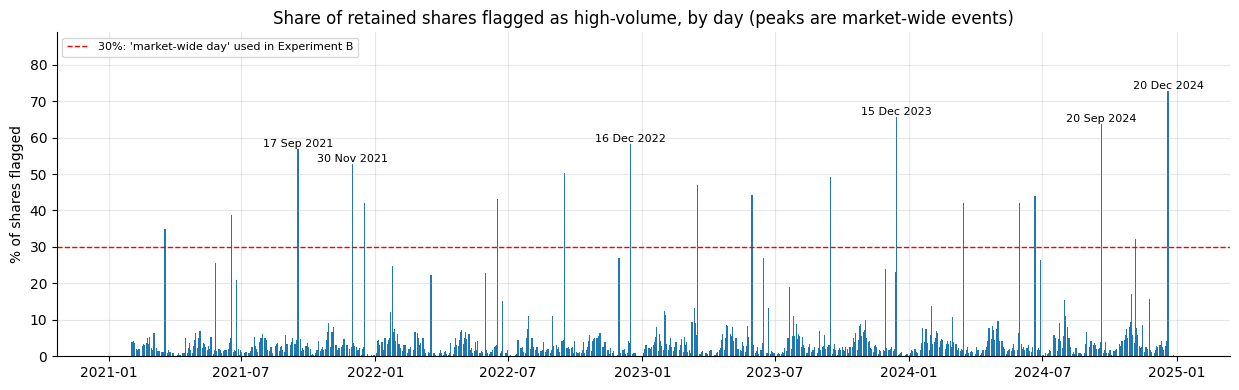

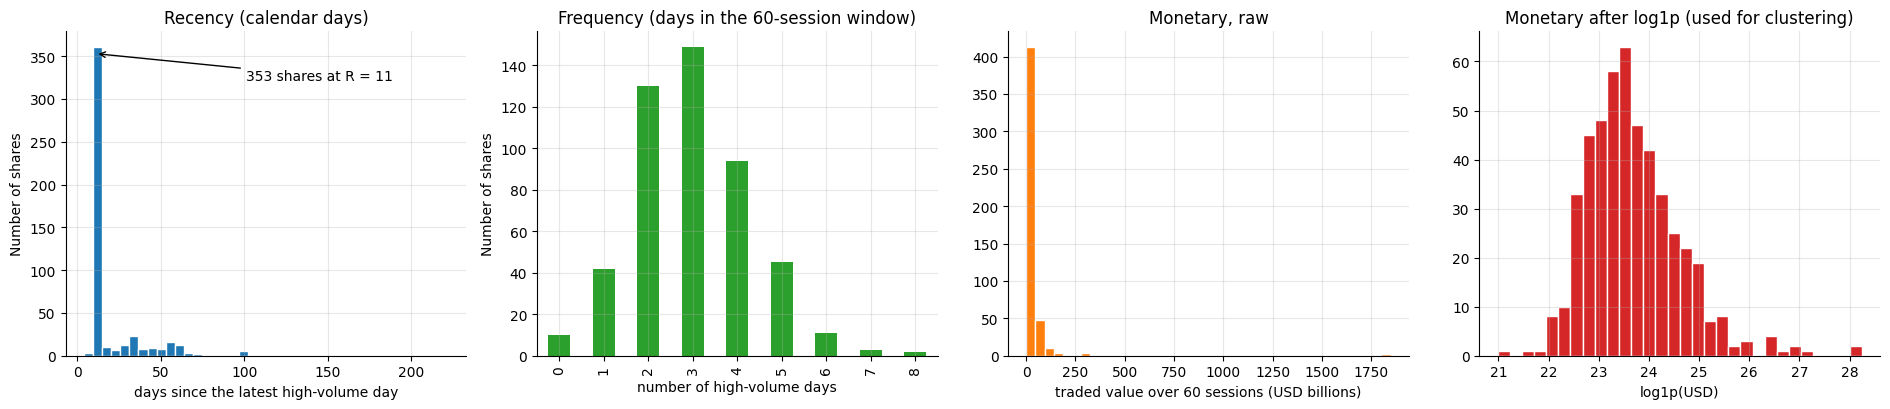

In [ ]:
# TASK 1.4 | Part C: diagrams - how market-wide are the high-volume days, and what do R, F and M look like?
breadth = flags.mean(axis=1)                    # share of retained shares flagged on each day
top = breadth.nlargest(10)
print("Days with the highest share of shares flagged:")
print(pd.DataFrame({"weekday": top.index.day_name(), "% of shares flagged": (100 * top).round(1)}).to_string())
wide = breadth > 0.30
print(f"\nMedian daily breadth: {100 * breadth.median():.1f}% | days with more than 30% of shares flagged: {int(wide.sum())} of {n_days}")
print(f"Share of ALL flagged share-days that fall on those market-wide days: {100 * flags.loc[wide].sum().sum() / flags.sum().sum():.1f}%")
print(f"Share of the window's events that fall on {breadth.loc[WIN].idxmax().date()}: {100 * flags.loc[breadth.loc[WIN].idxmax()].sum() / frequency.sum():.1f}%")

fig, ax = plt.subplots(figsize=(12.5, 4))
ax.bar(breadth.index, 100 * breadth, width=1.6, color="tab:blue")
ax.axhline(30, color="red", ls="--", lw=1, label="30%: 'market-wide day' used in Experiment B")
for d, v in breadth.nlargest(6).items():
    ax.annotate(d.strftime("%d %b %Y"), (d, 100 * v), fontsize=8, ha="center", va="bottom")
ax.set(title="Share of retained shares flagged as high-volume, by day (peaks are market-wide events)", ylabel="% of shares flagged")
ax.set_ylim(0, 100 * breadth.max() * 1.22)
ax.legend(loc="upper left", fontsize=8)
save_fig("fig09_event_breadth")

fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
ax[0].hist(recency, bins=40, color="tab:blue", edgecolor="white")
ax[0].set(title="Recency (calendar days)", xlabel="days since the latest high-volume day", ylabel="Number of shares")
ax[0].annotate(f"{int((recency == mode_r).sum())} shares at R = {mode_r:.0f}", (mode_r, (recency == mode_r).sum() / 1.0), xytext=(0.45, 0.85),
               textcoords="axes fraction", arrowprops=dict(arrowstyle="->"))
frequency.value_counts().sort_index().plot.bar(ax=ax[1], color="tab:green")
ax[1].set(title="Frequency (days in the 60-session window)", xlabel="number of high-volume days", ylabel="Number of shares")
ax[2].hist(monetary / 1e9, bins=40, color="tab:orange", edgecolor="white")
ax[2].set(title="Monetary, raw", xlabel="traded value over 60 sessions (USD billions)")
ax[3].hist(np.log1p(monetary), bins=30, color="tab:red", edgecolor="white")
ax[3].set(title="Monetary after log1p (used for clustering)", xlabel="log1p(USD)")
save_fig("fig10_rfm_distributions")

Experiment B: market-wide days ignored: 18 of 1005
   shares whose Recency changes: 369 of 486 | shares with no share-specific event at all: 0
   Recency baseline: median 11.0 std 21.3 | market-adjusted: median 50.0 std 44.4
   Frequency baseline mean 2.99 | market-adjusted mean 1.94 | correlation of Frequency across the two versions 0.88


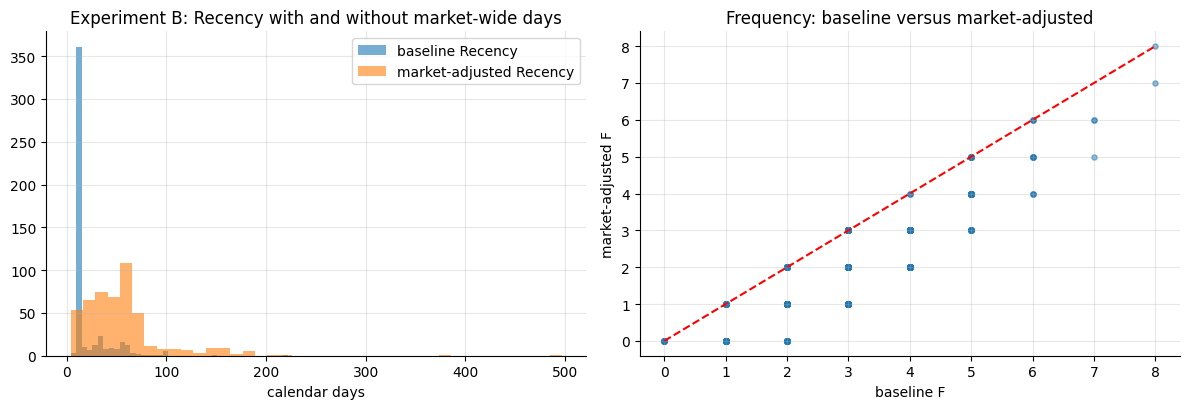


Experiment C: RFM at other observation dates
observation_date  most_common_R  pct_shares_at_that_R  median_R  mean_F  shares_with_F_zero  median_M_usd_bn
      2024-09-30             10                  59.3      10.0    2.46                  17             15.5
      2024-10-31             41                  23.0      15.0    2.22                  23             14.8
      2024-11-29             23                  20.2      23.0    2.94                  12             16.3
      2024-12-31             11                  72.6      11.0    2.99                  10             16.7


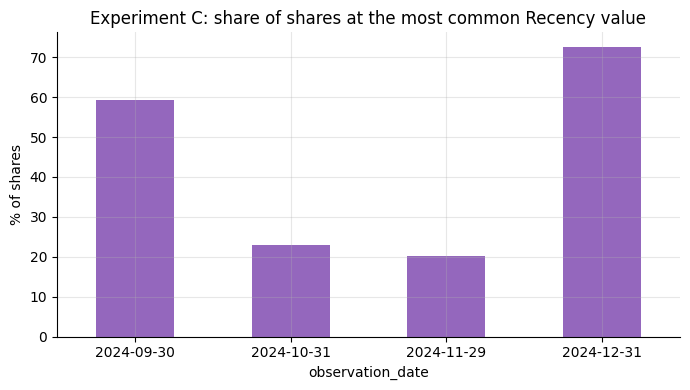

In [ ]:
# EXPERIMENT B and C (extensions, clearly separate from the baseline RFM)
# Experiment B: market-adjusted activity
wide_days = breadth.index[breadth > 0.30]
flags_idio = flags.copy()
flags_idio.loc[wide_days] = False
recency_idio = latest_event_days(flags_idio, OBS_DATE)
frequency_idio = flags_idio.loc[WIN].sum()
print(f"Experiment B: market-wide days ignored: {len(wide_days)} of {n_days}")
print("   shares whose Recency changes:", int((recency_idio != recency).sum()), "of", len(included),
      "| shares with no share-specific event at all:", int(recency_idio.isna().sum()))
print("   Recency baseline: median", recency.median(), "std", round(float(recency.std()), 1),
      "| market-adjusted: median", recency_idio.median(), "std", round(float(recency_idio.std()), 1))
print("   Frequency baseline mean", round(float(frequency.mean()), 2), "| market-adjusted mean", round(float(frequency_idio.mean()), 2),
      "| correlation of Frequency across the two versions", round(float(frequency.corr(frequency_idio)), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(recency, bins=40, alpha=0.6, label="baseline Recency", color="tab:blue")
ax[0].hist(recency_idio.dropna(), bins=40, alpha=0.6, label="market-adjusted Recency", color="tab:orange")
ax[0].set(title="Experiment B: Recency with and without market-wide days", xlabel="calendar days"); ax[0].legend()
ax[1].scatter(frequency, frequency_idio, s=14, alpha=0.5)
ax[1].plot([0, frequency.max()], [0, frequency.max()], "r--")
ax[1].set(title="Frequency: baseline versus market-adjusted", xlabel="baseline F", ylabel="market-adjusted F")
save_fig("fig11_experiment_b_market_adjusted")

# Experiment C: observation-date sensitivity (how much does the picture depend on where the observation date falls?)
rows = []
for m in ["2024-09-30", "2024-10-31", "2024-11-29", "2024-12-31"]:
    d = trading_days[trading_days <= pd.Timestamp(m)][-1]
    r_d = rfm_at(d)
    modal = r_d["recency_days"].mode().iloc[0]
    rows.append({"observation_date": d.date().isoformat(), "most_common_R": modal,
                 "pct_shares_at_that_R": round(100 * (r_d["recency_days"] == modal).mean(), 1),
                 "median_R": r_d["recency_days"].median(), "mean_F": round(float(r_d["frequency_60d"].mean()), 2),
                 "shares_with_F_zero": int((r_d["frequency_60d"] == 0).sum()), "median_M_usd_bn": round(float(r_d["monetary_usd"].median() / 1e9), 1)})
obs_sens = pd.DataFrame(rows)
obs_sens.to_csv(f"{DATA_DIR}/experiment_c_observation_date_sensitivity.csv", index=False)
print("\nExperiment C: RFM at other observation dates")
print(obs_sens.to_string(index=False))
ax = obs_sens.set_index("observation_date")["pct_shares_at_that_R"].plot.bar(figsize=(7, 4), color="tab:purple", title="Experiment C: share of shares at the most common Recency value")
ax.set_ylabel("% of shares"); plt.xticks(rotation=0)
save_fig("fig12_experiment_c_observation_dates")

PASSED: no share is excluded for a missing feature value
PASSED: feature table index equals the retained share set
Feature table: 486 shares x 5 core features

Worked RFM example: AAPL
Qualifying days in the 60-session window (volume above twice the mean of the preceding 20 sessions):
               volume  baseline_20d_mean  threshold_2x  event  volume_over_threshold
Date                                                                                
2024-11-25   90152800         43820740.0    87641480.0   True                   1.03
2024-12-20  147495300         45004605.0    90009210.0   True                   1.64
Closest day that did NOT qualify:
              volume  baseline_20d_mean  threshold_2x  event  volume_over_threshold
Date                                                                               
2024-10-31  64370100         38510015.0    77020030.0  False                   0.84
R = 11 calendar days (latest event 2024-12-20 to the observation date 2024-12-31) | F = 

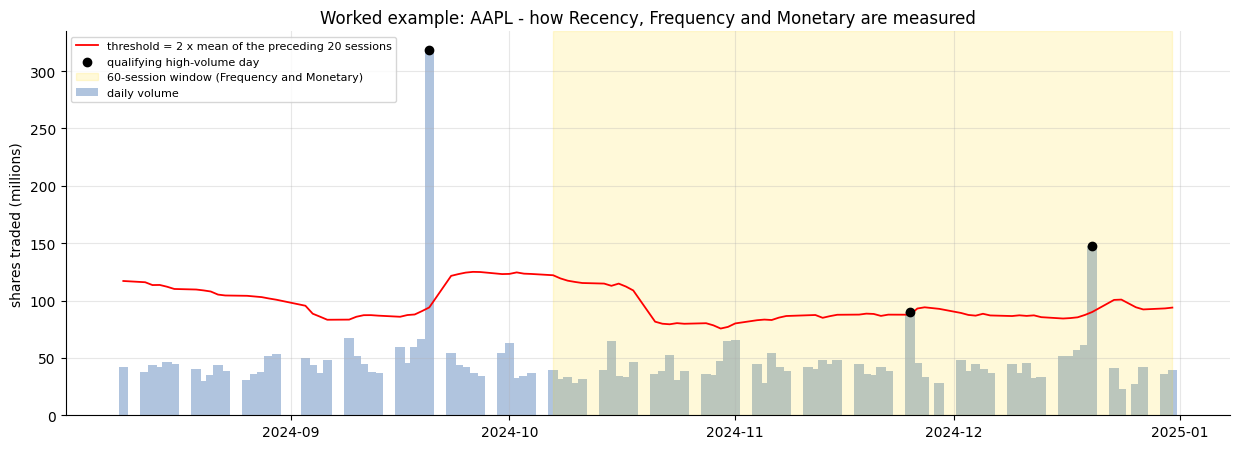

In [ ]:
# TASK 1.5 | Part A: final feature table (one row per retained share) and worked RFM example
feature_table = (inclusion_log.loc[included, ["company", "sector"]]
                 .join(feat[["mean_weekly_return", "weekly_beta"]])
                 .join(rfm))
feature_table["last_event_date"] = OBS_DATE - pd.to_timedelta(feature_table["recency_days"], unit="D")
feature_table["log1p_monetary"] = np.log1p(feature_table["monetary_usd"])
# Optional extension columns for Task 2 experiments (market-wide days ignored). They are NOT part of the baseline features.
feature_table["recency_idio_days"] = recency_idio
feature_table["frequency_idio_60d"] = frequency_idio

core = ["mean_weekly_return", "weekly_beta", "recency_days", "frequency_60d", "monetary_usd"]
missing_rfm = feature_table[core].isna().any(axis=1)
check("no share is excluded for a missing feature value", not missing_rfm.any(), hard=False)
feature_table = feature_table.loc[~missing_rfm]          # a share with a missing value would leave the clustering set (none expected)
check("feature table index equals the retained share set", feature_table.index.tolist() == [t for t in included if t in feature_table.index])
print(f"Feature table: {feature_table.shape[0]} shares x {len(core)} core features")
feature_table.to_csv(f"{DATA_DIR}/feature_table.csv")

# Worked RFM example: the event rule applied day by day inside the window
ex = "AAPL" if "AAPL" in included else included[0]
wk = pd.DataFrame({"volume": v_inc[ex], "baseline_20d_mean": baseline[ex], "threshold_2x": threshold[ex], "event": flags[ex]}).loc[WIN]
wk["volume_over_threshold"] = wk["volume"] / wk["threshold_2x"]
print(f"\nWorked RFM example: {ex}")
print("Qualifying days in the 60-session window (volume above twice the mean of the preceding 20 sessions):")
print(wk[wk["event"]].round({"volume_over_threshold": 2, "baseline_20d_mean": 0, "threshold_2x": 0}).to_string())
near = wk[~wk["event"]].nlargest(1, "volume_over_threshold")
print("Closest day that did NOT qualify:")
print(near.round({"volume_over_threshold": 2, "baseline_20d_mean": 0, "threshold_2x": 0}).to_string())
row = feature_table.loc[ex]
print(f"R = {int(row['recency_days'])} calendar days (latest event {pd.Timestamp(row['last_event_date']).date()} to the observation date {OBS_DATE.date()}) | "
      f"F = {int(row['frequency_60d'])} days | M = ${row['monetary_usd'] / 1e9:,.1f} billion")

# Diagram of the worked example
vv, th, ff = v_inc[ex].iloc[-100:], threshold[ex].iloc[-100:], flags[ex].iloc[-100:]
fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.bar(vv.index, vv / 1e6, width=1.3, color="lightsteelblue", label="daily volume")
ax.plot(th.index, th / 1e6, color="red", lw=1.3, label="threshold = 2 x mean of the preceding 20 sessions")
ax.scatter(vv.index[ff.values], vv[ff.values] / 1e6, color="black", zorder=3, label="qualifying high-volume day")
ax.axvspan(WIN[0], WIN[-1], color="gold", alpha=0.15, label="60-session window (Frequency and Monetary)")
ax.set(title=f"Worked example: {ex} - how Recency, Frequency and Monetary are measured", ylabel="shares traded (millions)")
ax.legend(fontsize=8, loc="upper left")
save_fig("fig13_worked_example")

Feature summaries (monetary_usd in USD):
                      count                mean              median                  std                min                    max    skew
mean_weekly_return 486.0000              0.0029              0.0026               0.0027            -0.0045                 0.0178  0.8675
weekly_beta        486.0000              0.9737              0.9506               0.4073             0.0555                 3.7786  1.1036
recency_days       486.0000             20.4074             11.0000              21.3424             4.0000               222.0000  3.6458
frequency_60d      486.0000              2.9897              3.0000               1.3308             0.0000                 8.0000  0.4247
monetary_usd       486.0000 39,404,191,889.2078 16,683,821,504.6230 129,138,833,232.9717 1,297,482,617.0479 1,847,697,379,221.8428 11.6838


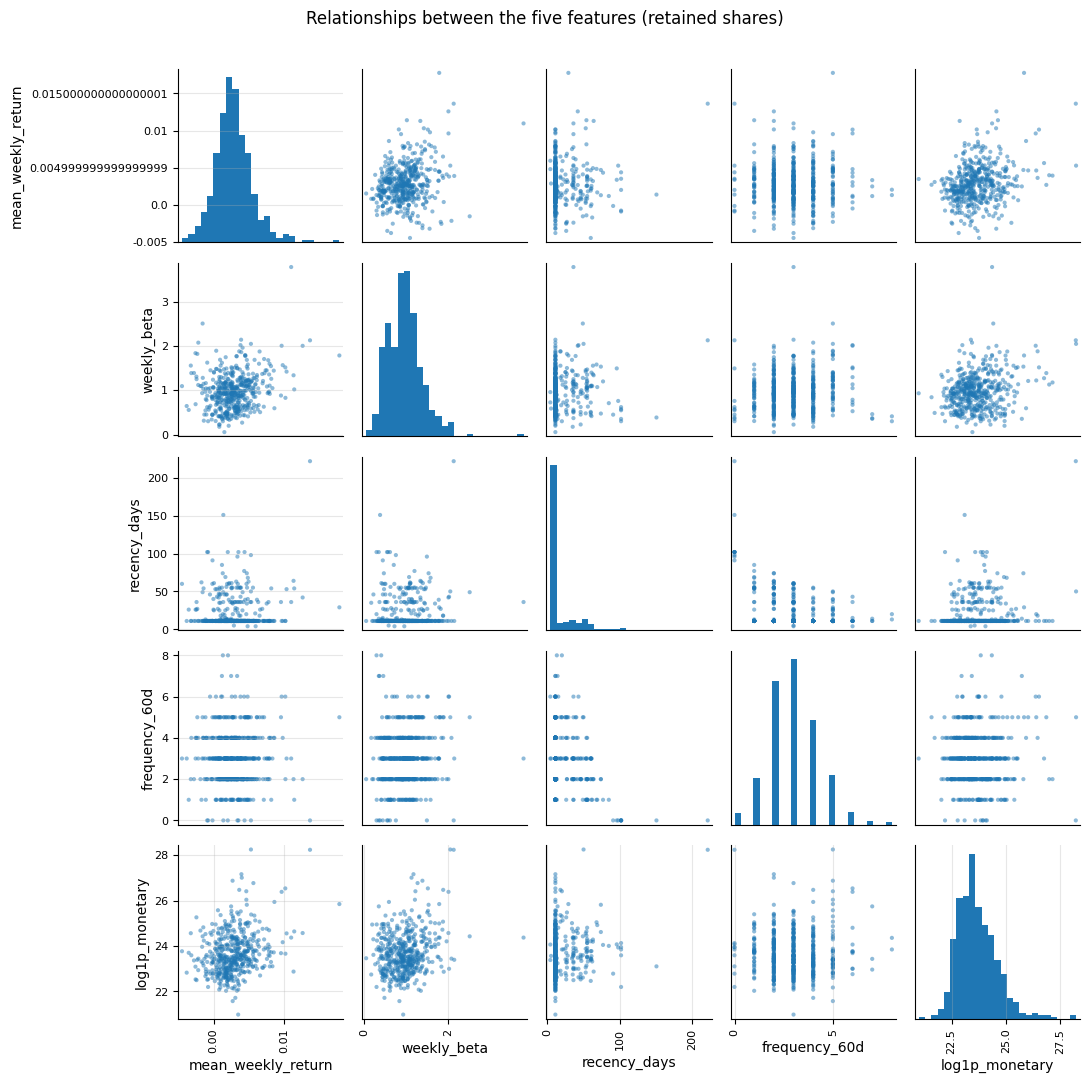


Validation and inclusion summary:
                                                          check                   result
                                       Snapshot retrieved (UTC)     2026-11-19 10:27 UTC
                                  Tickers in the Wikipedia list                      503
                        Excluded: no price data in study period                        5
                                   Excluded: incomplete history                       10
                      Excluded: volume error (zero or negative)                        2
                        Excluded: missing values inside history                        0
                    Shares retained (common set for all models)                      486
                      Duplicate dates on the benchmark calendar                        0
             Retained shares with missing values inside history                        0
                       Retained shares with non-positive prices            

In [ ]:
# TASK 1.5 | Part B: feature summaries, relationships between the features, and the validation / inclusion summary
summ = feature_table[core].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T
print("Feature summaries (monetary_usd in USD):")
print(summ.to_string(float_format=lambda v: f"{v:,.4f}"))

plot_cols = ["mean_weekly_return", "weekly_beta", "recency_days", "frequency_60d", "log1p_monetary"]
pd.plotting.scatter_matrix(feature_table[plot_cols], figsize=(11, 11), diagonal="hist", alpha=0.5, hist_kwds={"bins": 25})
plt.suptitle("Relationships between the five features (retained shares)", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("figures/fig14_feature_scatter_matrix.png", dpi=150)
plt.show()

retained = chk.loc[included]
reason = inclusion_log["exclusion_reason"]
validation_summary = pd.DataFrame([
    ("Snapshot retrieved (UTC)", info["retrieved_utc"]),
    ("Tickers in the Wikipedia list", len(TICKERS)),
    ("Excluded: no price data in study period", int(reason.str.contains("No price data").sum())),
    ("Excluded: incomplete history", int(reason.str.contains("Incomplete history").sum())),
    ("Excluded: volume error (zero or negative)", int(reason.str.contains("Volume error").sum())),
    ("Excluded: missing values inside history", int(reason.str.contains("Missing values").sum())),
    ("Shares retained (common set for all models)", len(included)),
    ("Duplicate dates on the benchmark calendar", int(trading_days.duplicated().sum())),
    ("Retained shares with missing values inside history", int((retained["gaps"] > 0).sum())),
    ("Retained shares with non-positive prices", int((retained["nonpositive_price_days"] > 0).sum())),
    ("Retained shares with zero or negative volume days", int(((retained["zero_volume_days"] > 0) | (retained["negative_volume_days"] > 0)).sum())),
    ("Split-type corporate-action events among retained shares", int((spl > 0).sum().sum())),
    ("Days where Adj Close and Close differ without a recorded action", int(unexplained.sum().sum())),
    ("Aligned weekly return observations per share", int(N_WEEKS)),
    ("Observation date", OBS_DATE.date().isoformat()),
    ("60-session window", f"{WIN[0].date()} to {WIN[-1].date()}"),
    ("Testable share-days for the 20-session baseline", int(threshold.notna().sum().sum())),
    ("High-volume days flagged", int(flags.sum().sum())),
    ("Shares with no event in history (Recency missing)", int(recency.isna().sum())),
    ("Shares with Frequency = 0", int((frequency == 0).sum())),
], columns=["check", "result"])
print("\nValidation and inclusion summary:")
print(validation_summary.to_string(index=False))
validation_summary.to_csv(f"{DATA_DIR}/validation_summary.csv", index=False)

run_metadata = {"snapshot": info, "observation_date": OBS_DATE.date().isoformat(), "window": [WIN[0].date().isoformat(), WIN[-1].date().isoformat()],
                "shares_retained": len(included), "weekly_observations": int(N_WEEKS),
                "notebook_package_versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "yfinance": yf.__version__}}
json.dump(run_metadata, open(f"{DATA_DIR}/run_metadata.json", "w"), indent=2)
print("\nSaved: feature_table.csv, validation_summary.csv, inclusion_exclusion_log.csv, weekly_*.csv, high_volume_flags.csv, run_metadata.json in", DATA_DIR, "and diagrams in figures/")

In [ ]:
# BACKUP | Zip data/ and figures/ (the snapshot plus every output). Set DOWNLOAD_BACKUP = True to download it from Colab
import zipfile
DOWNLOAD_BACKUP = False
zip_name = f"CWK1_snapshot_{info['retrieved_utc'][:10]}.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for folder, arc in [(DATA_DIR, "data"), ("figures", "figures")]:
        for p in sorted(glob.glob(f"{folder}/*")):
            z.write(p, f"{arc}/{os.path.basename(p)}")
print("Created", zip_name, f"({os.path.getsize(zip_name) / 1e6:.1f} MB)")
if DOWNLOAD_BACKUP:
    try:
        from google.colab import files
        files.download(zip_name)
    except ImportError:
        print("Not running in Colab: the zip is in the working folder.")

Created CWK1_snapshot_2026-11-19.zip (16.4 MB)


# **TASK 02**

PASSED: both matrices use exactly the same shares in the same order
PASSED: matrices cover the 486 retained shares
PASSED: no missing values in either matrix
PASSED: log1p_monetary equals log1p of monetary_usd
                     skew  IQR-rule outliers  |z|>3 outliers     min  median      max
feature                                                                              
mean_weekly_return  0.868                 15               6  -0.004   0.003    0.018
weekly_beta         1.104                 10               2   0.055   0.951    3.779
recency_days        3.646                115              11   4.000  11.000  222.000
frequency_60d       0.425                  2               5   0.000   3.000    8.000
log1p_monetary      1.079                 13               7  20.984  23.538   28.245

Recency: shares at the modal value 353 of 486 (the 2024-12-20 market-wide day) - so the IQR rule flags many shares only because the middle 50% is very narrow.
Strongest |z| per feature: {

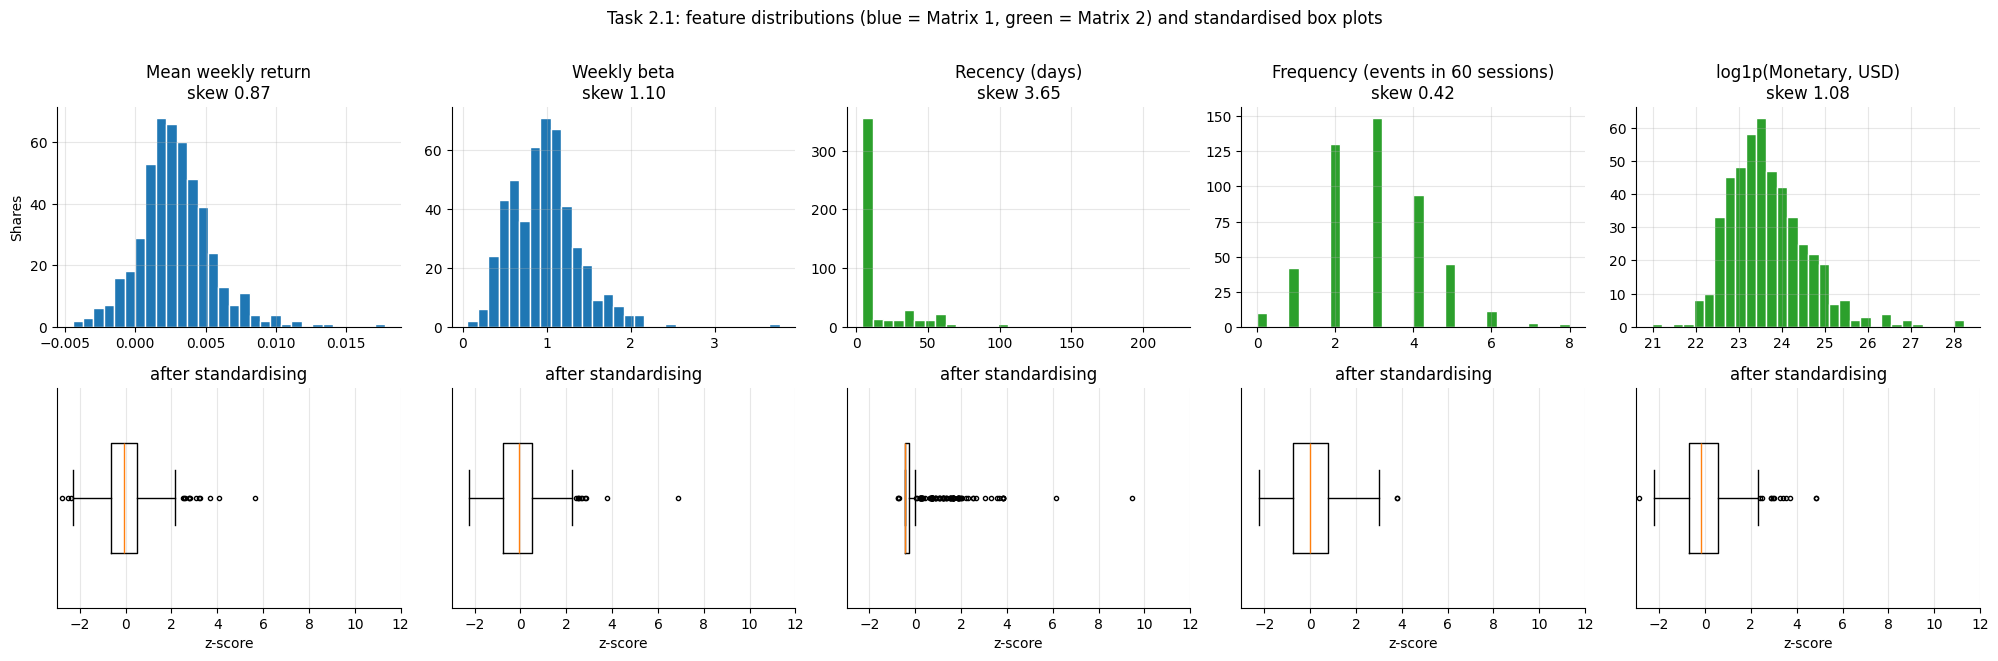

In [ ]:
# TASK 2.1 | Part A: two feature matrices, skewness/outlier check, standardisation (same 486 shares)
from sklearn.preprocessing import StandardScaler

M1_COLS = ["mean_weekly_return", "weekly_beta"]                      # Matrix 1: risk/return view
M2_COLS = ["recency_days", "frequency_60d", "log1p_monetary"]        # Matrix 2: RFM view (Monetary on the log1p scale)
LABELS = {"mean_weekly_return": "Mean weekly return", "weekly_beta": "Weekly beta", "recency_days": "Recency (days)",
          "frequency_60d": "Frequency (events in 60 sessions)", "log1p_monetary": "log1p(Monetary, USD)"}

X1, X2 = feature_table[M1_COLS].copy(), feature_table[M2_COLS].copy()
check("both matrices use exactly the same shares in the same order", X1.index.equals(X2.index) and X1.index.equals(feature_table.index))
check("matrices cover the 486 retained shares", len(X1) == len(included) == 486)
check("no missing values in either matrix", not X1.isna().any().any() and not X2.isna().any().any())
check("log1p_monetary equals log1p of monetary_usd", np.allclose(feature_table["log1p_monetary"], np.log1p(feature_table["monetary_usd"])))

# Skewness and outliers BEFORE standardising (standardising changes scale, not shape)
rows = []
for c in M1_COLS + M2_COLS:
    s = feature_table[c]
    q1, q3 = s.quantile([0.25, 0.75])
    z = (s - s.mean()) / s.std(ddof=0)
    rows.append({"feature": c, "skew": s.skew(), "IQR-rule outliers": int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum()),
                 "|z|>3 outliers": int((z.abs() > 3).sum()), "min": s.min(), "median": s.median(), "max": s.max()})
diag = pd.DataFrame(rows).set_index("feature")
print(diag.round(3).to_string())
print("\nRecency: shares at the modal value", int(feature_table["recency_days"].eq(feature_table["recency_days"].mode()[0]).sum()),
      "of", len(feature_table), "(the 2024-12-20 market-wide day) - so the IQR rule flags many shares only because the middle 50% is very narrow.")
print("Strongest |z| per feature:", {c: round(float(((feature_table[c] - feature_table[c].mean()) / feature_table[c].std(ddof=0)).abs().max()), 2) for c in M1_COLS + M2_COLS})
print("Most extreme shares:", {c: [(t, round(float(feature_table.at[t, c]), 4)) for t in feature_table[c].nlargest(2).index] for c in M1_COLS + M2_COLS})

# Standardise EACH matrix separately: z = (x - mean) / standard deviation (population SD, as StandardScaler does)
scaler1, scaler2 = StandardScaler(), StandardScaler()
Z1 = pd.DataFrame(scaler1.fit_transform(X1), index=X1.index, columns=M1_COLS)
Z2 = pd.DataFrame(scaler2.fit_transform(X2), index=X2.index, columns=M2_COLS)
check("standardised features have mean 0", np.allclose(Z1.mean(), 0, atol=1e-9) and np.allclose(Z2.mean(), 0, atol=1e-9))
check("standardised features have SD 1", np.allclose(Z1.std(ddof=0), 1) and np.allclose(Z2.std(ddof=0), 1))
check("standardising matches a hand calculation", np.allclose(Z2["recency_days"], (X2["recency_days"] - X2["recency_days"].mean()) / X2["recency_days"].std(ddof=0)))
check("standardising kept the same shares and order", Z1.index.equals(X1.index) and Z2.index.equals(X2.index))
Z1.to_csv(f"{DATA_DIR}/Z1_return_beta_standardised.csv"); Z2.to_csv(f"{DATA_DIR}/Z2_rfm_standardised.csv")
print(f"\nMatrix 1: {Z1.shape} | Matrix 2: {Z2.shape} | saved to {DATA_DIR}")

# Diagram: raw distributions (top) and standardised box plots (bottom); outliers are KEPT (see Part A note)
cols = M1_COLS + M2_COLS
fig, ax = plt.subplots(2, 5, figsize=(20, 6.5))
for j, c in enumerate(cols):
    ax[0, j].hist(feature_table[c], bins=30, color="tab:blue" if c in M1_COLS else "tab:green", edgecolor="white")
    ax[0, j].set(title=f"{LABELS[c]}\nskew {feature_table[c].skew():.2f}", ylabel="Shares" if j == 0 else "")
    zc = Z1[c] if c in M1_COLS else Z2[c]
    ax[1, j].boxplot(zc, vert=False, widths=0.5, flierprops={"markersize": 3})
    ax[1, j].set(title="after standardising", xlabel="z-score", yticks=[], xlim=(-3, 12))
fig.suptitle("Task 2.1: feature distributions (blue = Matrix 1, green = Matrix 2) and standardised box plots", y=1.01)
save_fig("fig15_task2_feature_distributions")

PASSED: the baseline version reproduces the standardised Matrix 2 from Part A
PASSED: every standardised feature has the same total variance (so each feature has the same total weight)
How each feature is spread after standardising (IQR in z units = room the typical share has; top-5 share = how much of the squared distance comes from 5 shares):
                         version feature  skew  IQR_in_z_units  top5_share_of_squared_distance_%  max_abs_z
        baseline: R, F, log1p(M)       R  3.65            0.18                             35.16       9.46
        baseline: R, F, log1p(M)       F  0.42            1.50                             11.46       3.77
        baseline: R, F, log1p(M)       M  1.08            1.22                             17.38       4.85
raw Monetary instead of log1p(M)       R  3.65            0.18                             35.16       9.46
raw Monetary instead of log1p(M)       F  0.42            1.50                             11.46       3.77
raw M

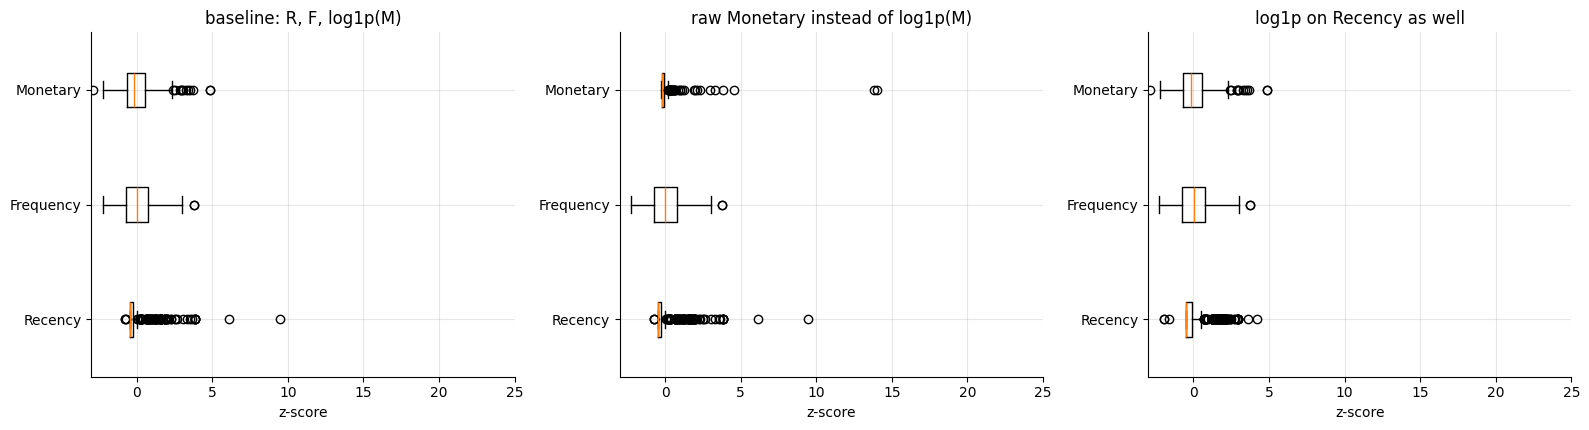

In [ ]:
# TASK 2.1 | Part B: how the transformations change the distances (log1p on Monetary, and what happens without it)
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score, silhouette_score

rec, frq, mon = feature_table["recency_days"], feature_table["frequency_60d"], feature_table["monetary_usd"]
variants = {"baseline: R, F, log1p(M)": pd.DataFrame({"R": rec, "F": frq, "M": np.log1p(mon)}),
            "raw Monetary instead of log1p(M)": pd.DataFrame({"R": rec, "F": frq, "M": mon}),
            "log1p on Recency as well": pd.DataFrame({"R": np.log1p(rec), "F": frq, "M": np.log1p(mon)})}
var_Z, var_lab, rows = {}, {}, []
for name, V in variants.items():
    Zv = pd.DataFrame(StandardScaler().fit_transform(V), index=V.index, columns=V.columns)
    var_Z[name] = Zv
    Lv = linkage(Zv.to_numpy(), method="ward", metric="euclidean")
    var_lab[name] = {k: fcluster(Lv, k, "maxclust") for k in (2, 3)}
    for c in Zv.columns:
        sq = np.sort((Zv[c] ** 2).to_numpy())[::-1]
        rows.append({"version": name, "feature": c, "skew": V[c].skew(), "IQR_in_z_units": float(Zv[c].quantile(0.75) - Zv[c].quantile(0.25)),
                     "top5_share_of_squared_distance_%": 100 * sq[:5].sum() / sq.sum(), "max_abs_z": float(Zv[c].abs().max())})
check("the baseline version reproduces the standardised Matrix 2 from Part A", np.allclose(var_Z["baseline: R, F, log1p(M)"].to_numpy(), Z2.to_numpy()))
check("every standardised feature has the same total variance (so each feature has the same total weight)", all(np.allclose(Zv.var(ddof=0), 1) for Zv in var_Z.values()))
diag_t = pd.DataFrame(rows)
print("How each feature is spread after standardising (IQR in z units = room the typical share has; top-5 share = how much of the squared distance comes from 5 shares):")
print(diag_t.round(2).to_string(index=False))
cmp_rows = []
for name in variants:
    for k in (2, 3):
        lab = var_lab[name][k]
        cmp_rows.append({"version": name, "k": k, "silhouette": silhouette_score(var_Z[name], lab), "ARI_vs_baseline": adjusted_rand_score(lab, var_lab["baseline: R, F, log1p(M)"][k]),
                         "sizes": sorted(np.bincount(lab)[1:].tolist(), reverse=True)})
cmp_t = pd.DataFrame(cmp_rows)
print("\nWard clusters under each version (silhouettes are measured in each version's own space, so compare ARI and sizes rather than silhouettes):")
print(cmp_t.round(3).to_string(index=False))
diag_t.to_csv(f"{DATA_DIR}/transformation_diagnostics.csv", index=False); cmp_t.to_csv(f"{DATA_DIR}/transformation_ward_comparison.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, (name, Zv) in zip(ax, var_Z.items()):
    a.boxplot([Zv[c] for c in Zv.columns], vert=False)
    a.set_yticks([1, 2, 3]); a.set_yticklabels(["Recency", "Frequency", "Monetary"])
    a.set(title=name, xlabel="z-score"); a.set_xlim(-3, 25)
save_fig("fig15b_task21_transformation_effect")

PASSED: Matrix 1 (return, beta): 485 merges for 486 shares
PASSED: Matrix 1 (return, beta): merge heights never decrease
PASSED: Matrix 1 (return, beta): last merge joins all 486 shares
PASSED: Matrix 1 (return, beta): scipy and scikit-learn Ward give the same 4 clusters
Matrix 1 (return, beta): cophenetic correlation 0.479 (how faithfully the tree keeps the original distances)
   last merge heights (the first value is the final join): [23.07, 18.8, 14.21, 12.67, 11.6, 8.34, 8.31, 5.93]
   height jump when going from k to k-1 clusters, k=2..8: {2: 4.27, 3: 4.59, 4: 1.54, 5: 1.07, 6: 3.26, 7: 0.03, 8: 2.38}
PASSED: Matrix 2 (R, F, log1p M): 485 merges for 486 shares
PASSED: Matrix 2 (R, F, log1p M): merge heights never decrease
PASSED: Matrix 2 (R, F, log1p M): last merge joins all 486 shares
PASSED: Matrix 2 (R, F, log1p M): scipy and scikit-learn Ward give the same 4 clusters
Matrix 2 (R, F, log1p M): cophenetic correlation 0.508 (how faithfully the tree keeps the original distances)


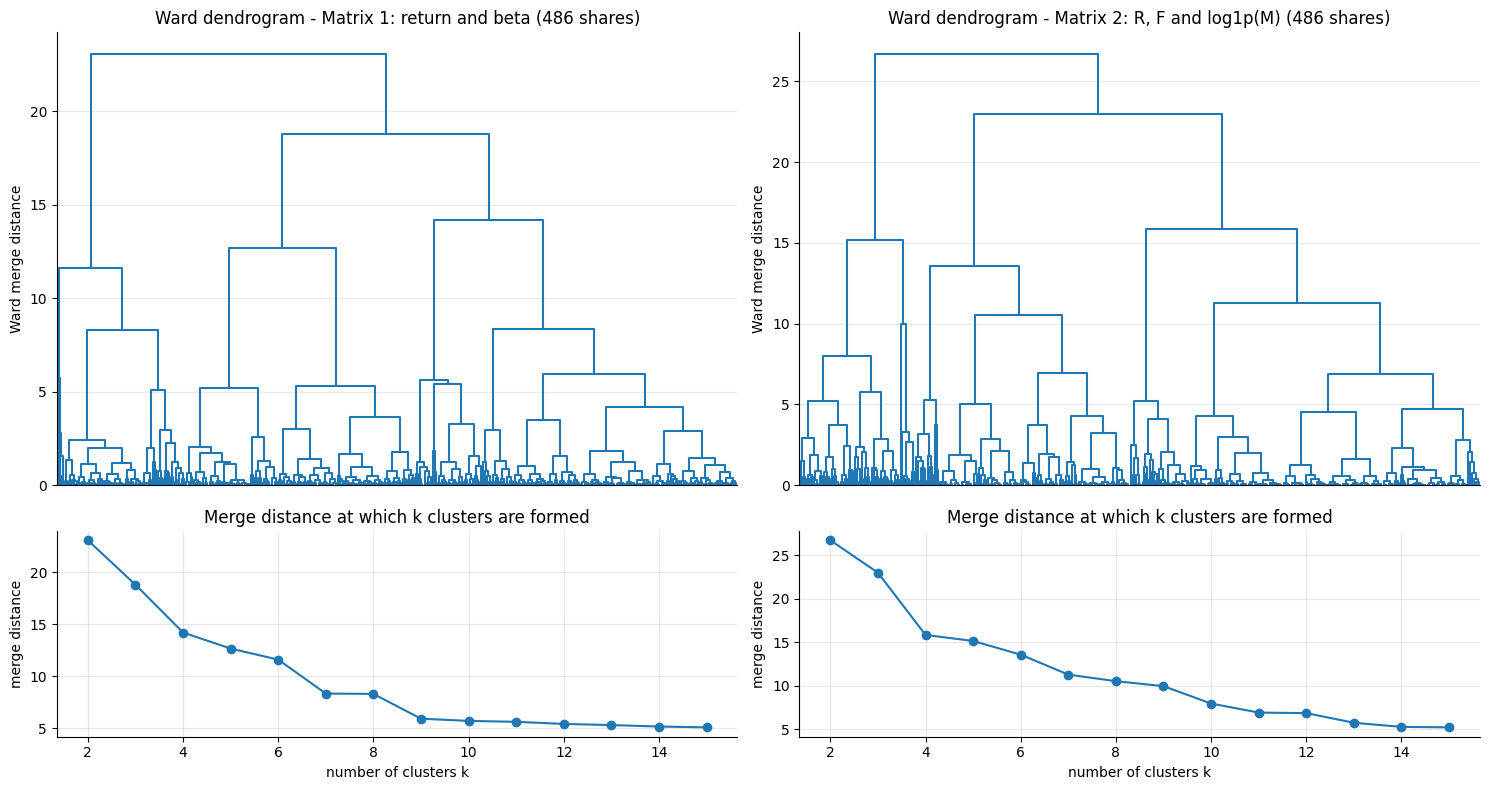

In [ ]:
# TASK 2.2 | Part A: Ward linkage (Euclidean distance) and a dendrogram for each standardised matrix
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

link1 = linkage(Z1.to_numpy(), method="ward", metric="euclidean")     # Matrix 1: return + beta
link2 = linkage(Z2.to_numpy(), method="ward", metric="euclidean")     # Matrix 2: R, F, log1p(M)
for name, L, Z in [("Matrix 1 (return, beta)", link1, Z1), ("Matrix 2 (R, F, log1p M)", link2, Z2)]:
    check(f"{name}: {len(Z) - 1} merges for {len(Z)} shares", L.shape == (len(Z) - 1, 4))
    check(f"{name}: merge heights never decrease", (np.diff(L[:, 2]) >= -1e-12).all())
    check(f"{name}: last merge joins all {len(Z)} shares", int(L[-1, 3]) == len(Z))
    sk = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(Z.to_numpy())
    check(f"{name}: scipy and scikit-learn Ward give the same 4 clusters", adjusted_rand_score(fcluster(L, 4, "maxclust"), sk) == 1.0)
    coph = cophenet(L, pdist(Z.to_numpy()))[0]
    print(f"{name}: cophenetic correlation {coph:.3f} (how faithfully the tree keeps the original distances)")
    h = L[-8:, 2][::-1]
    print("   last merge heights (the first value is the final join):", np.round(h, 2).tolist())
    print("   height jump when going from k to k-1 clusters, k=2..8:", {k: round(float(L[-(k - 1), 2] - L[-k, 2]), 2) for k in range(2, 9)})

fig, ax = plt.subplots(2, 2, figsize=(15, 8), gridspec_kw={"height_ratios": [2.2, 1]})
for j, (title, L) in enumerate([("Matrix 1: return and beta", link1), ("Matrix 2: R, F and log1p(M)", link2)]):
    dendrogram(L, ax=ax[0, j], no_labels=True, color_threshold=0, above_threshold_color="tab:blue")
    ax[0, j].set(title=f"Ward dendrogram - {title} (486 shares)", ylabel="Ward merge distance")
    ks = np.arange(2, 16)
    ax[1, j].plot(ks, [L[-(k - 1), 2] for k in ks], "o-")
    ax[1, j].set(title="Merge distance at which k clusters are formed", xlabel="number of clusters k", ylabel="merge distance")
save_fig("fig16_task22_ward_dendrograms")

PASSED: M1 k=2: exactly 2 clusters covering all 486 shares
PASSED: M1 k=3: exactly 3 clusters covering all 486 shares
PASSED: M1 k=4: exactly 4 clusters covering all 486 shares
PASSED: M1 k=5: exactly 5 clusters covering all 486 shares
PASSED: M1 k=6: exactly 6 clusters covering all 486 shares
PASSED: M1 k=7: exactly 7 clusters covering all 486 shares
PASSED: M1 k=8: exactly 8 clusters covering all 486 shares

Ward, Matrix 1 (return, beta)
   silhouette  calinski_harabasz  smallest  largest                             sizes
k                                                                                    
2       0.339            182.536        92      394                         [394, 92]
3       0.274            202.207        92      230                    [230, 164, 92]
4       0.282            204.153        48      182                [182, 164, 92, 48]
5       0.304            215.797        48      182             [182, 98, 92, 66, 48]
6       0.320            236.638        

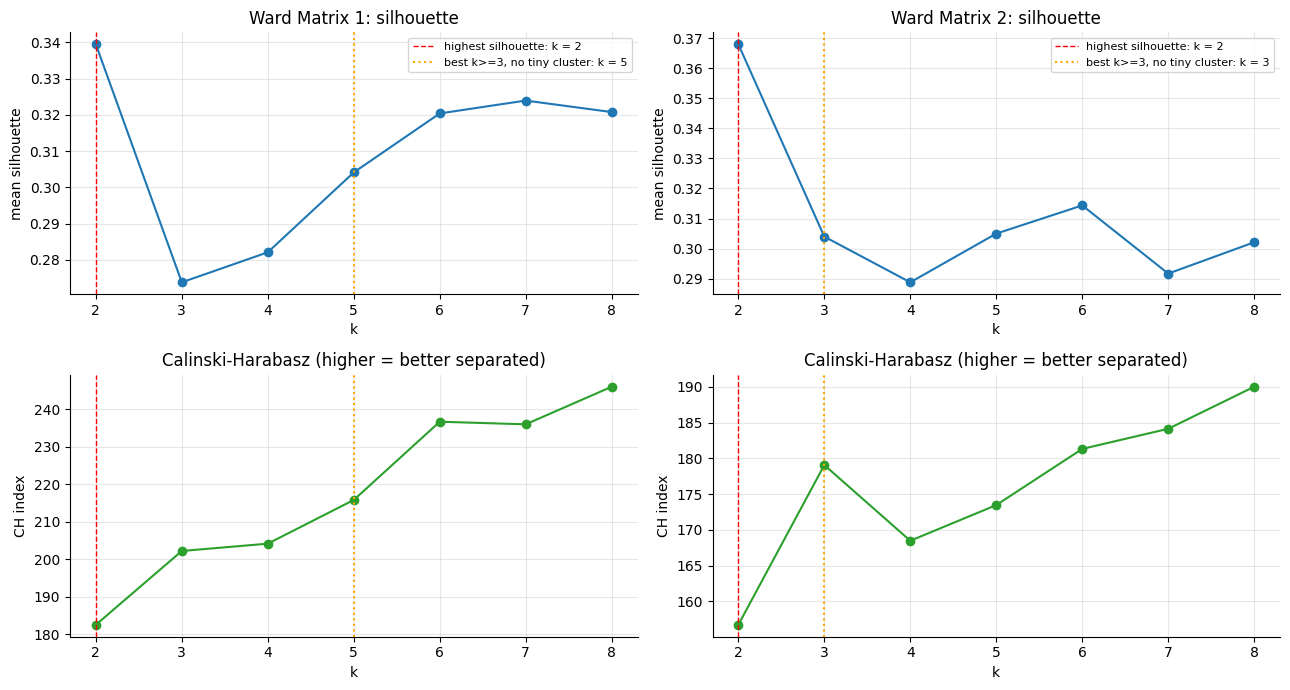

In [ ]:
# TASK 2.2 | Part B: Ward with k = 2 to 8 - silhouette, Calinski-Harabasz, cluster sizes and the chosen k for each matrix
from sklearn.metrics import silhouette_score, calinski_harabasz_score

K_RANGE = range(2, 9)
ward_scores, ward_labels = {}, {}
for name, L, Z in [("M1", link1, Z1), ("M2", link2, Z2)]:
    rows = []
    for k in K_RANGE:
        lab = fcluster(L, k, "maxclust")
        check(f"{name} k={k}: exactly {k} clusters covering all {len(Z)} shares", len(np.unique(lab)) == k and len(lab) == len(Z))
        ward_labels[(name, k)] = lab
        sizes = np.bincount(lab)[1:]
        rows.append({"k": k, "silhouette": silhouette_score(Z, lab), "calinski_harabasz": calinski_harabasz_score(Z, lab),
                     "smallest": int(sizes.min()), "largest": int(sizes.max()), "sizes": sorted(sizes.tolist(), reverse=True)})
    ward_scores[name] = pd.DataFrame(rows).set_index("k")
    print(f"\nWard, {'Matrix 1 (return, beta)' if name == 'M1' else 'Matrix 2 (R, F, log1p M)'}")
    print(ward_scores[name].round(3).to_string())

# Independent recalculation of one silhouette value: mean of (b - a) / max(a, b) over all shares
Zn, lab = Z2.to_numpy(), ward_labels[("M2", 3)]
D = np.sqrt(((Zn[:, None, :] - Zn[None, :, :]) ** 2).sum(-1))
s = []
for i in range(len(Zn)):
    same = (lab == lab[i]); same[i] = False
    a = D[i, same].mean() if same.any() else 0.0
    b = min(D[i, lab == c].mean() for c in np.unique(lab) if c != lab[i])
    s.append((b - a) / max(a, b) if same.any() else 0.0)
check("silhouette matches a manual calculation (M2, k=3)", np.isclose(np.mean(s), ward_scores["M2"].at[3, "silhouette"]))

# Chosen k. Main choice = highest silhouette. Because k=2 is a thin segmentation, a second "profile" k is also kept:
# the best silhouette among k >= 3 where every cluster holds at least 5% of the shares (no tiny clusters)
MIN_SHARE = 0.05
ward_k = {n: int(ward_scores[n]["silhouette"].idxmax()) for n in ward_scores}
ward_k3 = {}
for n in ward_scores:
    ok = ward_scores[n][(ward_scores[n].index >= 3) & (ward_scores[n]["smallest"] >= MIN_SHARE * len(Z1))]
    ward_k3[n] = int(ok["silhouette"].idxmax())
print("\nHighest silhouette:", ward_k, "| Calinski-Harabasz would pick:", {n: int(ward_scores[n]["calinski_harabasz"].idxmax()) for n in ward_scores})
print(f"Best k >= 3 with every cluster at least {MIN_SHARE:.0%} of shares ({int(np.ceil(MIN_SHARE * len(Z1)))} shares):", ward_k3)
for n in ward_scores:
    idx = (Z1 if n == "M1" else Z2).index
    ward_scores[n].to_csv(f"{DATA_DIR}/ward_scores_{n}.csv")
    pd.DataFrame({f"k{ward_k[n]}": ward_labels[(n, ward_k[n])], f"k{ward_k3[n]}": ward_labels[(n, ward_k3[n])]}, index=idx).to_csv(f"{DATA_DIR}/ward_labels_{n}.csv")

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for j, n in enumerate(["M1", "M2"]):
    sc = ward_scores[n]
    ax[0, j].plot(sc.index, sc["silhouette"], "o-", color="tab:blue"); ax[0, j].axvline(ward_k[n], color="red", ls="--", lw=1, label=f"highest silhouette: k = {ward_k[n]}"); ax[0, j].axvline(ward_k3[n], color="orange", ls=":", lw=1.5, label=f"best k>=3, no tiny cluster: k = {ward_k3[n]}")
    ax[0, j].set(title=f"Ward {'Matrix 1' if n == 'M1' else 'Matrix 2'}: silhouette", xlabel="k", ylabel="mean silhouette"); ax[0, j].legend(fontsize=8)
    ax[1, j].plot(sc.index, sc["calinski_harabasz"], "o-", color="tab:green"); ax[1, j].axvline(ward_k[n], color="red", ls="--", lw=1); ax[1, j].axvline(ward_k3[n], color="orange", ls=":", lw=1.5)
    ax[1, j].set(title="Calinski-Harabasz (higher = better separated)", xlabel="k", ylabel="CH index")
save_fig("fig17_task22_ward_k_selection")

PASSED: M1: a cut at height 20.94 gives exactly 2 clusters, the same as the k=2 solution used for profiling
PASSED: M1: a cut at height 12.14 gives exactly 5 clusters, the same as the k=5 solution used for profiling
PASSED: M2: a cut at height 24.85 gives exactly 2 clusters, the same as the k=2 solution used for profiling
PASSED: M2: a cut at height 19.41 gives exactly 3 clusters, the same as the k=3 solution used for profiling


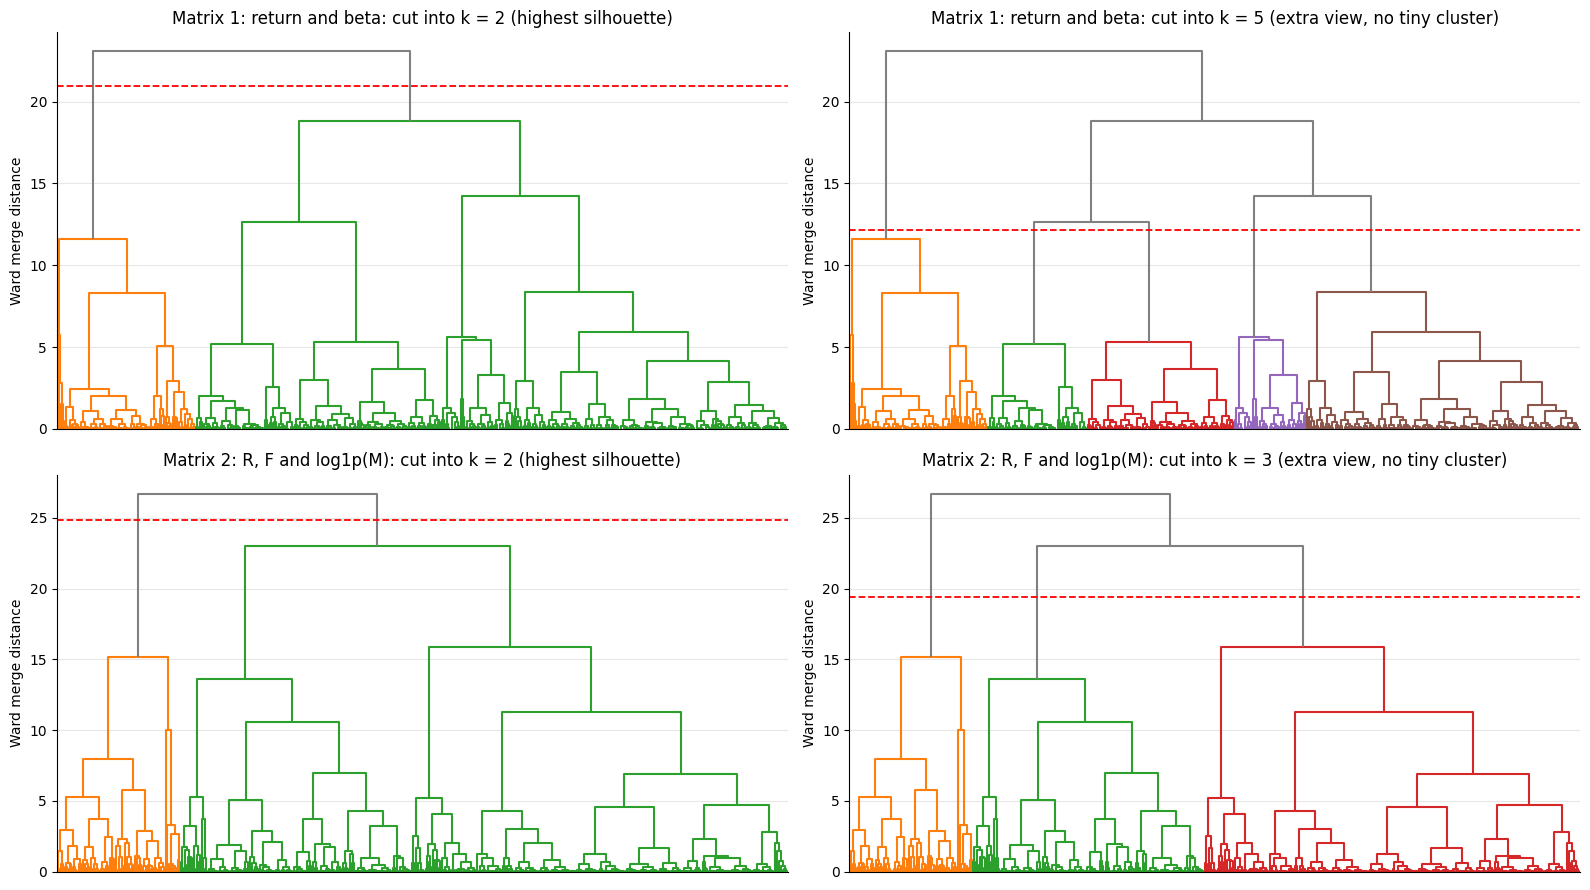

In [ ]:
# TASK 2.2 | Part B2: dendrograms with the chosen cuts drawn as red lines (formal k and the extra k), clusters coloured below the cut
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
for r, (n, L, title) in enumerate([("M1", link1, "Matrix 1: return and beta"), ("M2", link2, "Matrix 2: R, F and log1p(M)")]):
    for c, k in enumerate([ward_k[n], ward_k3[n]]):
        cut = (L[-k, 2] + L[-(k - 1), 2]) / 2        # halfway between the merge that turns k+1 clusters into k and the merge that turns k into k-1
        check(f"{n}: a cut at height {cut:.2f} gives exactly {k} clusters, the same as the k={k} solution used for profiling",
              adjusted_rand_score(fcluster(L, cut, criterion="distance"), fcluster(L, k, "maxclust")) == 1.0 and len(np.unique(fcluster(L, cut, criterion="distance"))) == k)
        dendrogram(L, ax=ax[r, c], no_labels=True, color_threshold=cut, above_threshold_color="grey")
        ax[r, c].axhline(cut, color="red", ls="--", lw=1.3)
        ax[r, c].set(title=f"{title}: cut into k = {k} ({'highest silhouette' if c == 0 else 'extra view, no tiny cluster'})", ylabel="Ward merge distance")
save_fig("fig17b_task22_dendrogram_cuts")

PASSED: M1 k=2: profile sizes add up to 486 shares
PASSED: M1 k=2: size-weighted cluster means equal the overall mean (mean_weekly_return)

Ward Matrix 1 (return, beta) | k = 2
         shares  percent  mean_return_%_per_week  mean_beta    closest_to_centre                   top_sector
cluster                                                                                                      
1           394     81.1                   0.205        0.9  ICE, VRSK, FDX, UDR              Financials (61)
2            92     18.9                   0.632        1.3  PHM, FLEX, UAL, AMP  Information Technology (29)
PASSED: M1 k=5: profile sizes add up to 486 shares
PASSED: M1 k=5: size-weighted cluster means equal the overall mean (mean_weekly_return)

Ward Matrix 1 (return, beta) | k = 5
         shares  percent  mean_return_%_per_week  mean_beta     closest_to_centre                   top_sector
cluster                                                                                        

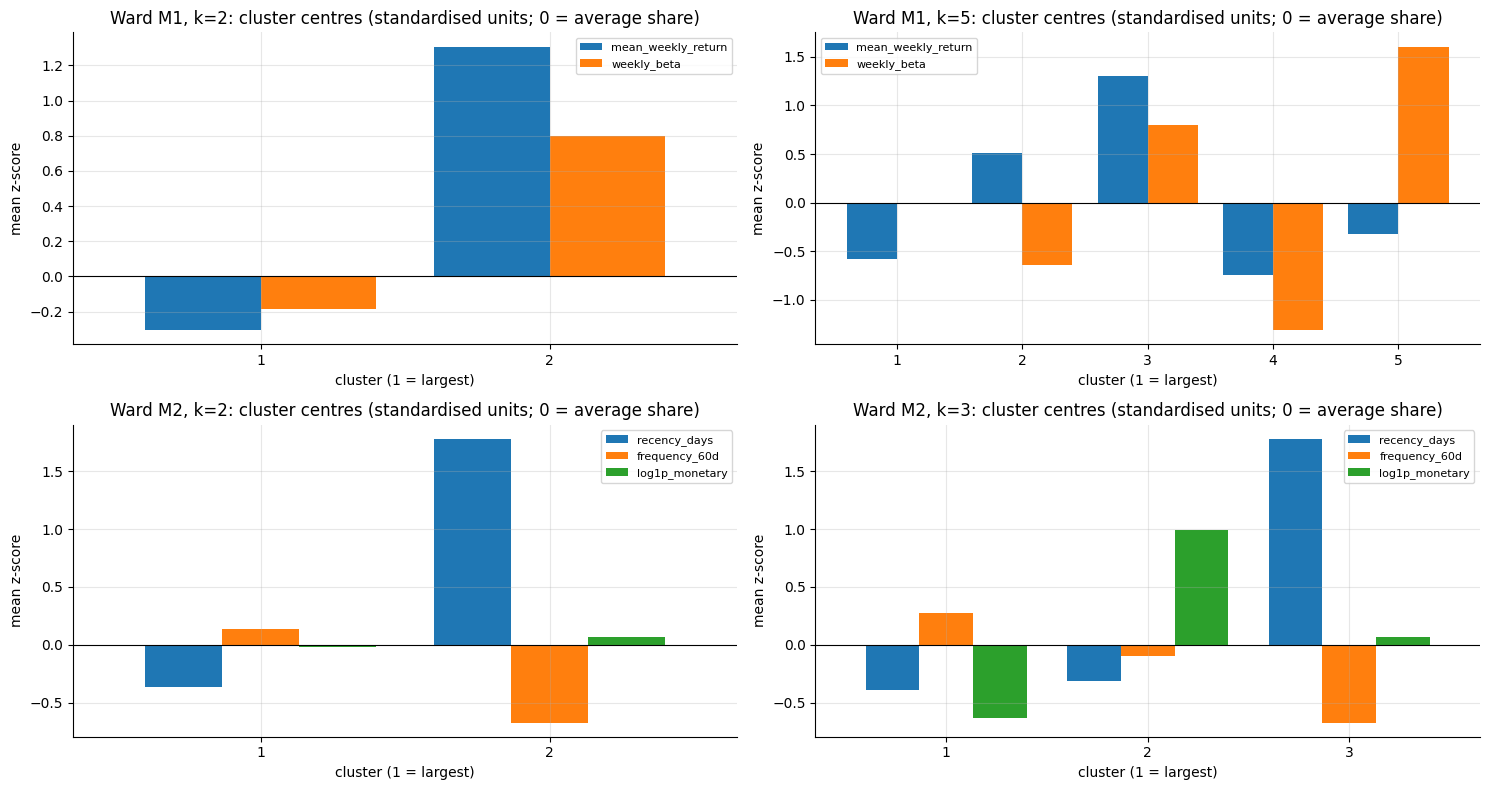

In [ ]:
# TASK 2.2 | Part C: Ward cluster profiles in original units (formal choice k = highest silhouette, plus the extra k without tiny clusters)
def relabel_by_size(lab):
    """Cluster 1 = largest, 2 = next largest, ... so labels are stable and readable."""
    order = pd.Series(lab).value_counts().index.tolist()
    return pd.Series(lab).map({old: new for new, old in enumerate(order, start=1)}).to_numpy()

ward_final = {}
def profile(n, k, lab):
    Zm = Z1 if n == "M1" else Z2
    ft = feature_table.loc[Zm.index]
    g = pd.Series(lab, index=Zm.index, name="cluster")
    out = pd.DataFrame({"shares": g.value_counts().sort_index(), "percent": (100 * g.value_counts(normalize=True).sort_index()).round(1)})
    if n == "M1":
        out["mean_return_%_per_week"] = (100 * ft["mean_weekly_return"]).groupby(g).mean().round(3)
        out["mean_beta"] = ft["weekly_beta"].groupby(g).mean().round(2)
    else:
        out["median_recency_days"] = ft["recency_days"].groupby(g).median()
        out["mean_frequency_60d"] = ft["frequency_60d"].groupby(g).mean().round(2)
        out["median_traded_value_USD_bn"] = (ft["monetary_usd"].groupby(g).median() / 1e9).round(1)
    cen = Zm.groupby(g).transform("mean")
    dist = np.sqrt(((Zm - cen) ** 2).sum(axis=1))
    out["closest_to_centre"] = [", ".join(dist[g == c].nsmallest(4).index) for c in out.index]
    out["top_sector"] = [f"{ft.loc[g == c, 'sector'].value_counts().index[0]} ({ft.loc[g == c, 'sector'].value_counts().iloc[0]})" for c in out.index]
    return g, out

fig, ax = plt.subplots(2, 2, figsize=(15, 8))
for r, n in enumerate(["M1", "M2"]):
    for c, k in enumerate(sorted({ward_k[n], ward_k3[n]})):
        lab = relabel_by_size(ward_labels[(n, k)])
        g, out = profile(n, k, lab)
        ward_final[(n, k)] = g
        Zm = Z1 if n == "M1" else Z2
        check(f"{n} k={k}: profile sizes add up to 486 shares", int(out["shares"].sum()) == len(Zm))
        ft = feature_table.loc[Zm.index]
        col = "mean_weekly_return" if n == "M1" else "recency_days"
        check(f"{n} k={k}: size-weighted cluster means equal the overall mean ({col})", np.isclose((ft[col].groupby(g).mean() * out["shares"]).sum() / len(Zm), ft[col].mean()))
        print(f"\nWard {'Matrix 1 (return, beta)' if n == 'M1' else 'Matrix 2 (R, F, log1p M)'} | k = {k}")
        print(out.to_string())
        Zm.groupby(g).mean().plot.bar(ax=ax[r, c], width=0.8, rot=0)
        ax[r, c].axhline(0, color="black", lw=0.8)
        ax[r, c].set(title=f"Ward {n}, k={k}: cluster centres (standardised units; 0 = average share)", xlabel="cluster (1 = largest)", ylabel="mean z-score")
        ax[r, c].legend(fontsize=8)
save_fig("fig18_task22_ward_profiles")
for (n, k), g in ward_final.items():
    g.to_csv(f"{DATA_DIR}/ward_{n}_k{k}_clusters.csv")

PASSED: M1 k=2: exactly 2 clusters covering all 486 shares
PASSED: M1 k=2: inertia equals the sum of squared distances to the centres
PASSED: M1 k=2: best of 50 starts is no worse than a single start
PASSED: M1 k=3: exactly 3 clusters covering all 486 shares
PASSED: M1 k=3: inertia equals the sum of squared distances to the centres
PASSED: M1 k=3: best of 50 starts is no worse than a single start
PASSED: M1 k=4: exactly 4 clusters covering all 486 shares
PASSED: M1 k=4: inertia equals the sum of squared distances to the centres
PASSED: M1 k=4: best of 50 starts is no worse than a single start
PASSED: M1 k=5: exactly 5 clusters covering all 486 shares
PASSED: M1 k=5: inertia equals the sum of squared distances to the centres
PASSED: M1 k=5: best of 50 starts is no worse than a single start
PASSED: M1 k=6: exactly 6 clusters covering all 486 shares
PASSED: M1 k=6: inertia equals the sum of squared distances to the centres
PASSED: M1 k=6: best of 50 starts is no worse than a single start


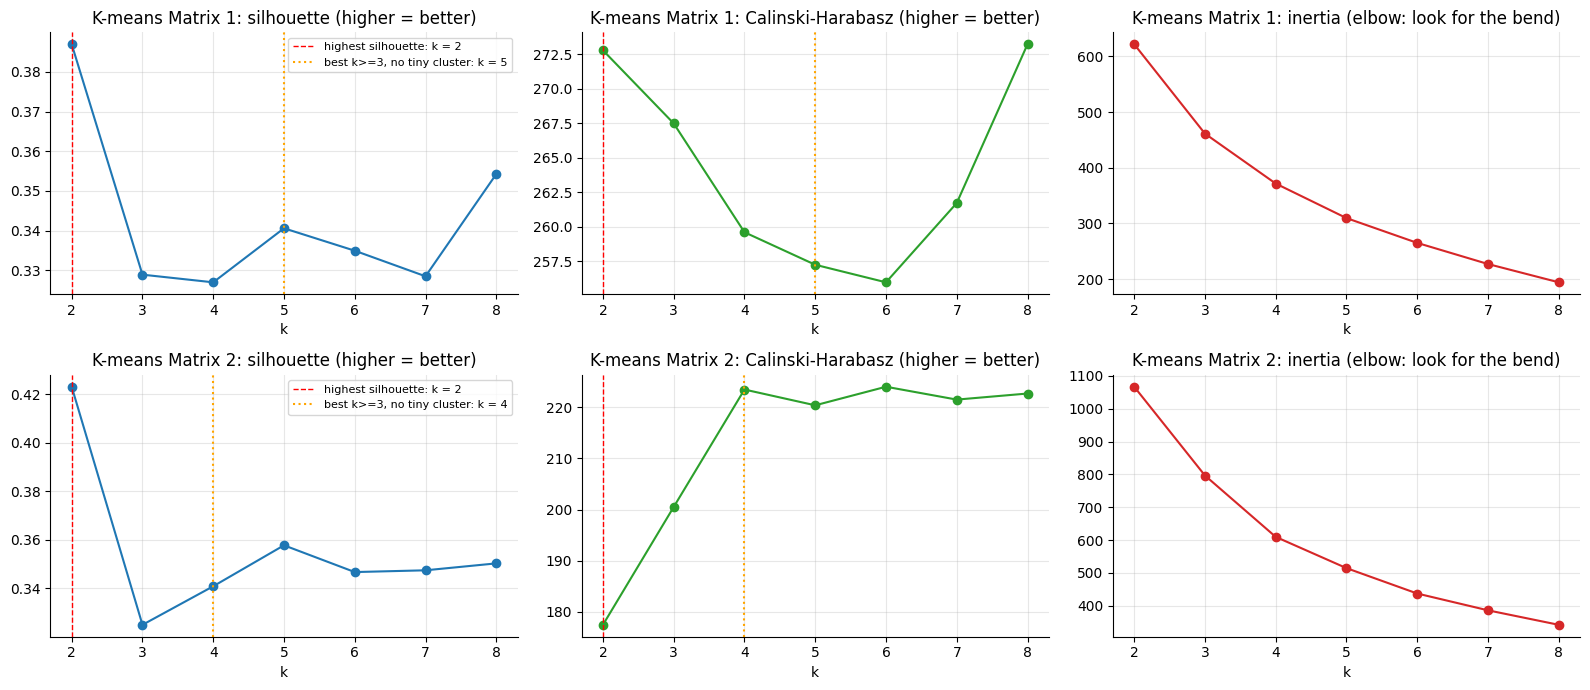

In [ ]:
# TASK 2.3 | Part A: K-means with k = 2 to 8 - fixed seed, 50 random starts, silhouette, Calinski-Harabasz, inertia and cluster sizes
from sklearn.cluster import KMeans

SEED, N_INIT = 42, 50
km_scores, km_labels = {}, {}
for n, Zm in [("M1", Z1), ("M2", Z2)]:
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(Zm.to_numpy())
        lab = km.labels_ + 1
        check(f"{n} k={k}: exactly {k} clusters covering all {len(Zm)} shares", len(np.unique(lab)) == k and len(lab) == len(Zm))
        manual = ((Zm.to_numpy() - km.cluster_centers_[km.labels_]) ** 2).sum()
        check(f"{n} k={k}: inertia equals the sum of squared distances to the centres", np.isclose(km.inertia_, manual))
        single = KMeans(n_clusters=k, n_init=1, random_state=SEED).fit(Zm.to_numpy()).inertia_
        check(f"{n} k={k}: best of {N_INIT} starts is no worse than a single start", km.inertia_ <= single + 1e-9)
        km_labels[(n, k)] = lab
        sizes = np.bincount(lab)[1:]
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Zm, lab), "calinski_harabasz": calinski_harabasz_score(Zm, lab),
                     "smallest": int(sizes.min()), "largest": int(sizes.max()), "sizes": sorted(sizes.tolist(), reverse=True)})
    km_scores[n] = pd.DataFrame(rows).set_index("k")
    print(f"\nK-means, {'Matrix 1 (return, beta)' if n == 'M1' else 'Matrix 2 (R, F, log1p M)'} (seed {SEED}, {N_INIT} starts)")
    print(km_scores[n].round(3).to_string())

# Same seed twice gives the same answer (reproducibility)
rep = KMeans(n_clusters=4, n_init=N_INIT, random_state=SEED).fit(Z2.to_numpy()).labels_ + 1
check("re-running with the same seed gives identical clusters", np.array_equal(rep, km_labels[("M2", 4)]))

km_k = {n: int(km_scores[n]["silhouette"].idxmax()) for n in km_scores}
km_k3 = {}
for n in km_scores:
    ok = km_scores[n][(km_scores[n].index >= 3) & (km_scores[n]["smallest"] >= MIN_SHARE * len(Z1))]
    km_k3[n] = int(ok["silhouette"].idxmax())
print("\nHighest silhouette:", km_k, "| Calinski-Harabasz would pick:", {n: int(km_scores[n]["calinski_harabasz"].idxmax()) for n in km_scores})
print(f"Best k >= 3 with every cluster at least {MIN_SHARE:.0%} of shares:", km_k3)
for n in km_scores:
    idx = (Z1 if n == "M1" else Z2).index
    km_scores[n].to_csv(f"{DATA_DIR}/kmeans_scores_{n}.csv")
    pd.DataFrame({f"k{km_k[n]}": km_labels[(n, km_k[n])], f"k{km_k3[n]}": km_labels[(n, km_k3[n])]}, index=idx).to_csv(f"{DATA_DIR}/kmeans_labels_{n}.csv")

fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for r, n in enumerate(["M1", "M2"]):
    sc = km_scores[n]
    for c, (col, colour, title) in enumerate([("silhouette", "tab:blue", "silhouette (higher = better)"), ("calinski_harabasz", "tab:green", "Calinski-Harabasz (higher = better)"),
                                              ("inertia", "tab:red", "inertia (elbow: look for the bend)")]):
        ax[r, c].plot(sc.index, sc[col], "o-", color=colour)
        if c < 2:
            ax[r, c].axvline(km_k[n], color="red", ls="--", lw=1, label=f"highest silhouette: k = {km_k[n]}")
            ax[r, c].axvline(km_k3[n], color="orange", ls=":", lw=1.5, label=f"best k>=3, no tiny cluster: k = {km_k3[n]}")
        if c == 0:
            ax[r, c].legend(fontsize=8)
        ax[r, c].set(title=f"K-means {'Matrix 1' if n == 'M1' else 'Matrix 2'}: {title}", xlabel="k")
save_fig("fig19_task23_kmeans_k_selection")

PASSED: K-means M1 k=2: profile sizes add up to 486 shares
PASSED: K-means M1 k=2: size-weighted cluster means equal the overall mean (mean_weekly_return)

K-means Matrix 1 (return, beta) | k = 2
         shares  percent  mean_return_%_per_week  mean_beta     closest_to_centre                   top_sector
cluster                                                                                                       
1           343     70.6                   0.183       0.82    CPT, GPC, ESS, MAA              Financials (57)
2           143     29.4                   0.533       1.35  NUE, CDNS, META, AMP  Information Technology (48)
PASSED: K-means M1 k=5: profile sizes add up to 486 shares
PASSED: K-means M1 k=5: size-weighted cluster means equal the overall mean (mean_weekly_return)

K-means Matrix 1 (return, beta) | k = 5
         shares  percent  mean_return_%_per_week  mean_beta      closest_to_centre                   top_sector
cluster                                             

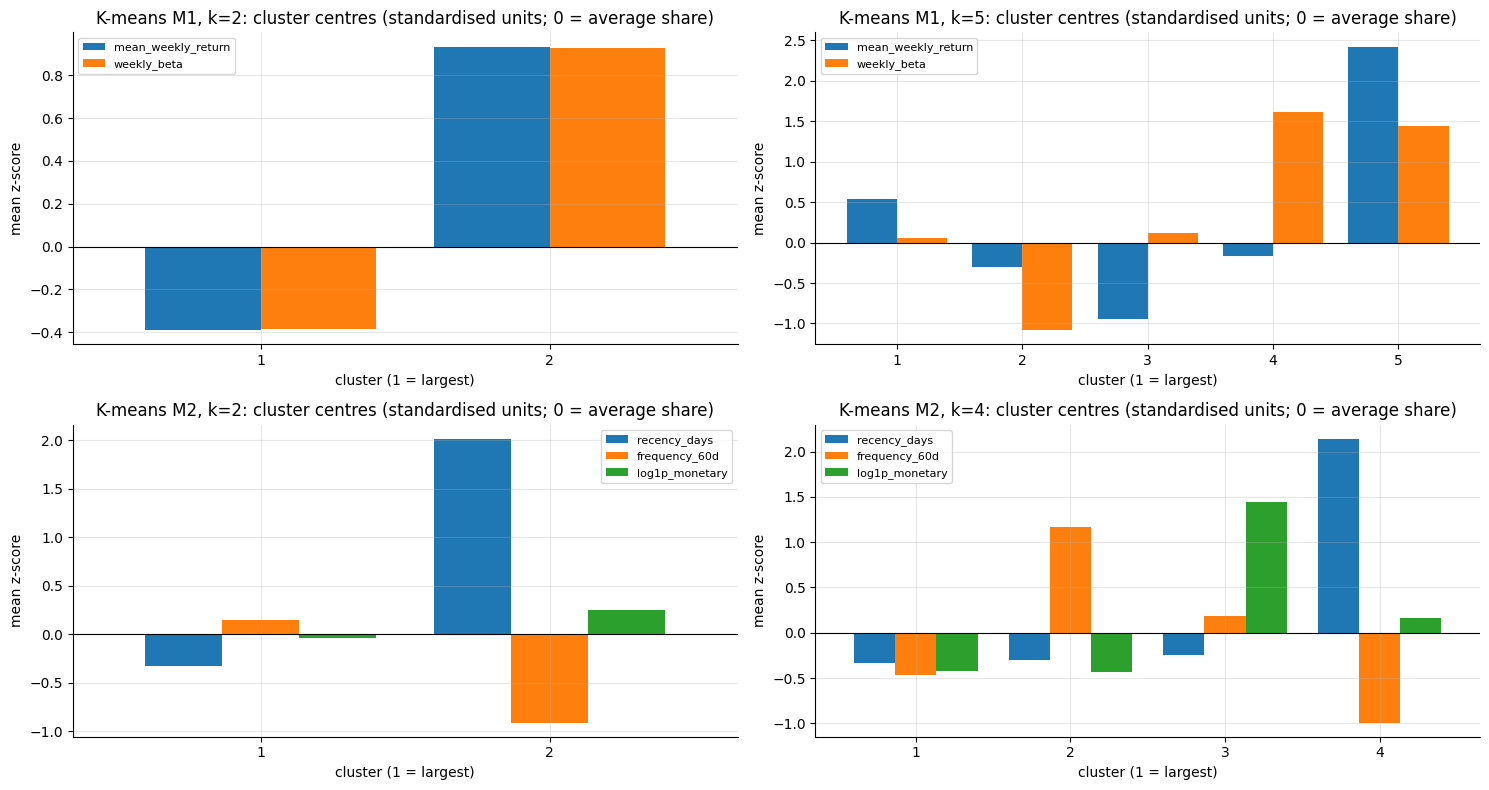

In [ ]:
# TASK 2.3 | Part B: K-means cluster profiles in original units (highest-silhouette k, plus the extra k without tiny clusters)
km_final = {}
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
for r, n in enumerate(["M1", "M2"]):
    for c, k in enumerate(sorted({km_k[n], km_k3[n]})):
        lab = relabel_by_size(km_labels[(n, k)])
        g, out = profile(n, k, lab)
        km_final[(n, k)] = g
        Zm = Z1 if n == "M1" else Z2
        ft = feature_table.loc[Zm.index]
        check(f"K-means {n} k={k}: profile sizes add up to 486 shares", int(out["shares"].sum()) == len(Zm))
        col = "mean_weekly_return" if n == "M1" else "recency_days"
        check(f"K-means {n} k={k}: size-weighted cluster means equal the overall mean ({col})", np.isclose((ft[col].groupby(g).mean() * out["shares"]).sum() / len(Zm), ft[col].mean()))
        print(f"\nK-means {'Matrix 1 (return, beta)' if n == 'M1' else 'Matrix 2 (R, F, log1p M)'} | k = {k}")
        print(out.to_string())
        Zm.groupby(g).mean().plot.bar(ax=ax[r, c], width=0.8, rot=0)
        ax[r, c].axhline(0, color="black", lw=0.8)
        ax[r, c].set(title=f"K-means {n}, k={k}: cluster centres (standardised units; 0 = average share)", xlabel="cluster (1 = largest)", ylabel="mean z-score")
        ax[r, c].legend(fontsize=8)
save_fig("fig20_task23_kmeans_profiles")
for (n, k), g in km_final.items():
    g.to_csv(f"{DATA_DIR}/kmeans_{n}_k{k}_clusters.csv")

PASSED: M1: PCA components are perpendicular unit directions
PASSED: M1: PCA scores equal (standardised data x components)
PASSED: M1: 2D map never makes two shares look further apart than they are

M1 PCA: PC1 explains 62.5% and PC2 37.5% of the variance (together 100.0%)
                    PC1 loading  PC2 loading
mean_weekly_return         0.71        -0.71
weekly_beta                0.71         0.71


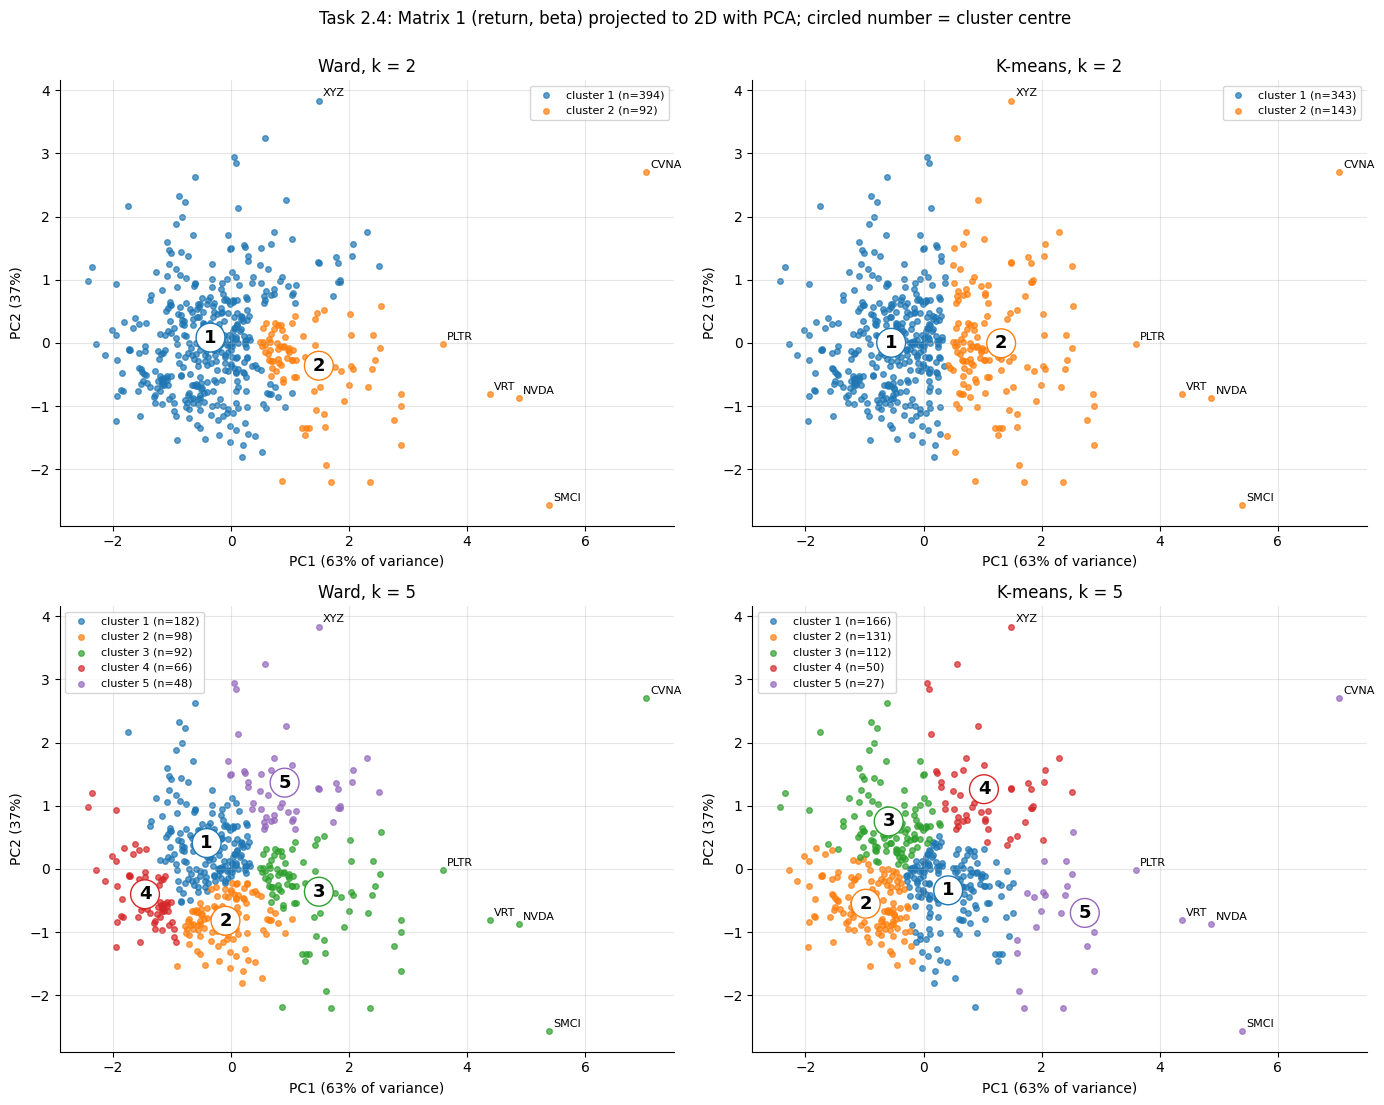

PASSED: M2: PCA components are perpendicular unit directions
PASSED: M2: PCA scores equal (standardised data x components)
PASSED: M2: 2D map never makes two shares look further apart than they are

M2 PCA: PC1 explains 45.8% and PC2 33.6% of the variance (together 79.4%)
                PC1 loading  PC2 loading
recency_days           0.71         0.02
frequency_60d         -0.65         0.40
log1p_monetary         0.27         0.92


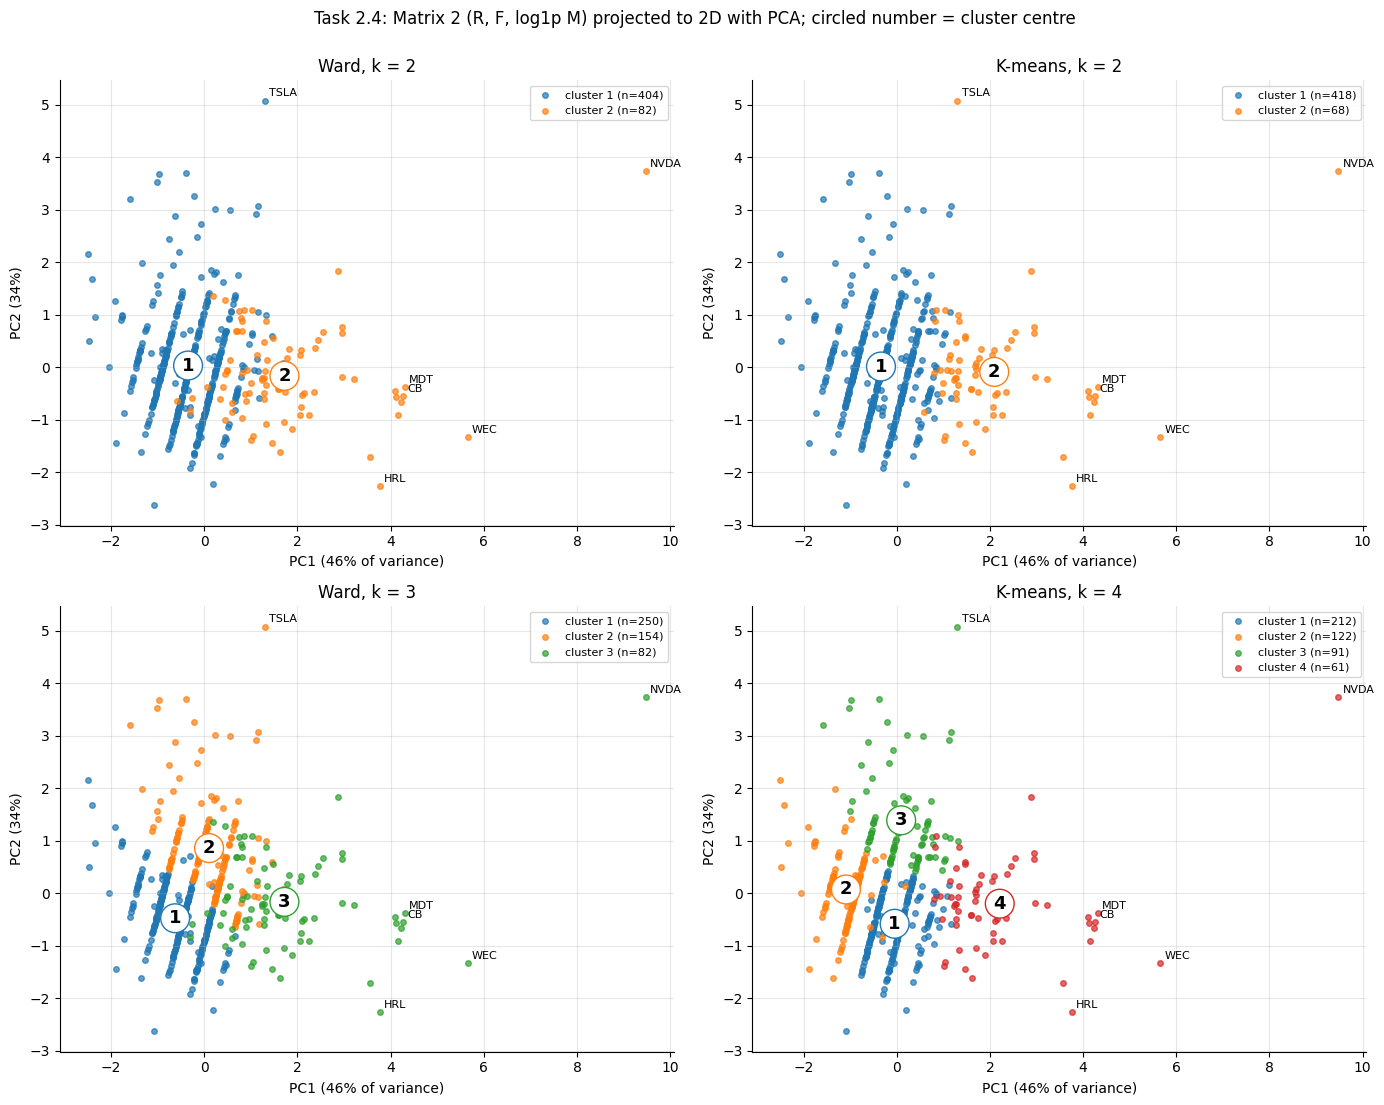

In [ ]:
# TASK 2.4 | Part A: 2D map of each matrix with PCA, coloured by cluster (Ward and K-means side by side)
from sklearn.decomposition import PCA

pca_xy = {}
for n, Zm, cols in [("M1", Z1, M1_COLS), ("M2", Z2, M2_COLS)]:
    pca = PCA(n_components=2, random_state=SEED).fit(Zm.to_numpy())
    xy = pd.DataFrame(pca.transform(Zm.to_numpy()), index=Zm.index, columns=["PC1", "PC2"])
    pca_xy[n] = xy
    check(f"{n}: PCA components are perpendicular unit directions", np.allclose(pca.components_ @ pca.components_.T, np.eye(2)))
    check(f"{n}: PCA scores equal (standardised data x components)", np.allclose(xy.to_numpy(), (Zm.to_numpy() - pca.mean_) @ pca.components_.T))
    check(f"{n}: 2D map never makes two shares look further apart than they are", (pdist(xy.to_numpy()) <= pdist(Zm.to_numpy()) + 1e-9).all())
    print(f"\n{n} PCA: PC1 explains {100 * pca.explained_variance_ratio_[0]:.1f}% and PC2 {100 * pca.explained_variance_ratio_[1]:.1f}% of the variance "
          f"(together {100 * pca.explained_variance_ratio_.sum():.1f}%)")
    print(pd.DataFrame(pca.components_.T, index=cols, columns=["PC1 loading", "PC2 loading"]).round(2).to_string())
    xy.to_csv(f"{DATA_DIR}/pca_coordinates_{n}.csv")

    fig, ax = plt.subplots(2, 2, figsize=(14, 11))
    far = (xy ** 2).sum(axis=1).nlargest(6).index                      # the same most extreme shares are named in every panel
    panels = [("Ward", ward_final, ward_k[n]), ("K-means", km_final, km_k[n]), ("Ward", ward_final, ward_k3[n]), ("K-means", km_final, km_k3[n])]
    for a, (algo, store, k) in zip(ax.ravel(), panels):
        g = store[(n, k)]
        for cl in sorted(g.unique()):
            m = g == cl
            a.scatter(xy.loc[m, "PC1"], xy.loc[m, "PC2"], s=16, alpha=0.7, color=plt.cm.tab10(cl - 1), label=f"cluster {cl} (n={int(m.sum())})")
            a.annotate(str(cl), (xy.loc[m, "PC1"].mean(), xy.loc[m, "PC2"].mean()), fontsize=13, fontweight="bold", ha="center", va="center",
                       bbox={"boxstyle": "circle", "fc": "white", "ec": plt.cm.tab10(cl - 1)})
        for t in far:
            a.annotate(t, (xy.at[t, "PC1"], xy.at[t, "PC2"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
        a.set(title=f"{algo}, k = {k}", xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}% of variance)", ylabel=f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}%)")
        a.legend(fontsize=8, loc="best")
    fig.suptitle(f"Task 2.4: {'Matrix 1 (return, beta)' if n == 'M1' else 'Matrix 2 (R, F, log1p M)'} projected to 2D with PCA; circled number = cluster centre", y=1.0)
    save_fig("fig21_task24_pca_matrix1" if n == "M1" else "fig22_task24_pca_matrix2")

PASSED: Ward k=2: the plotted shares are exactly the 486 clustered shares
PASSED: K-means k=2: the plotted shares are exactly the 486 clustered shares
PASSED: Ward k=5: the plotted shares are exactly the 486 clustered shares
PASSED: K-means k=5: the plotted shares are exactly the 486 clustered shares


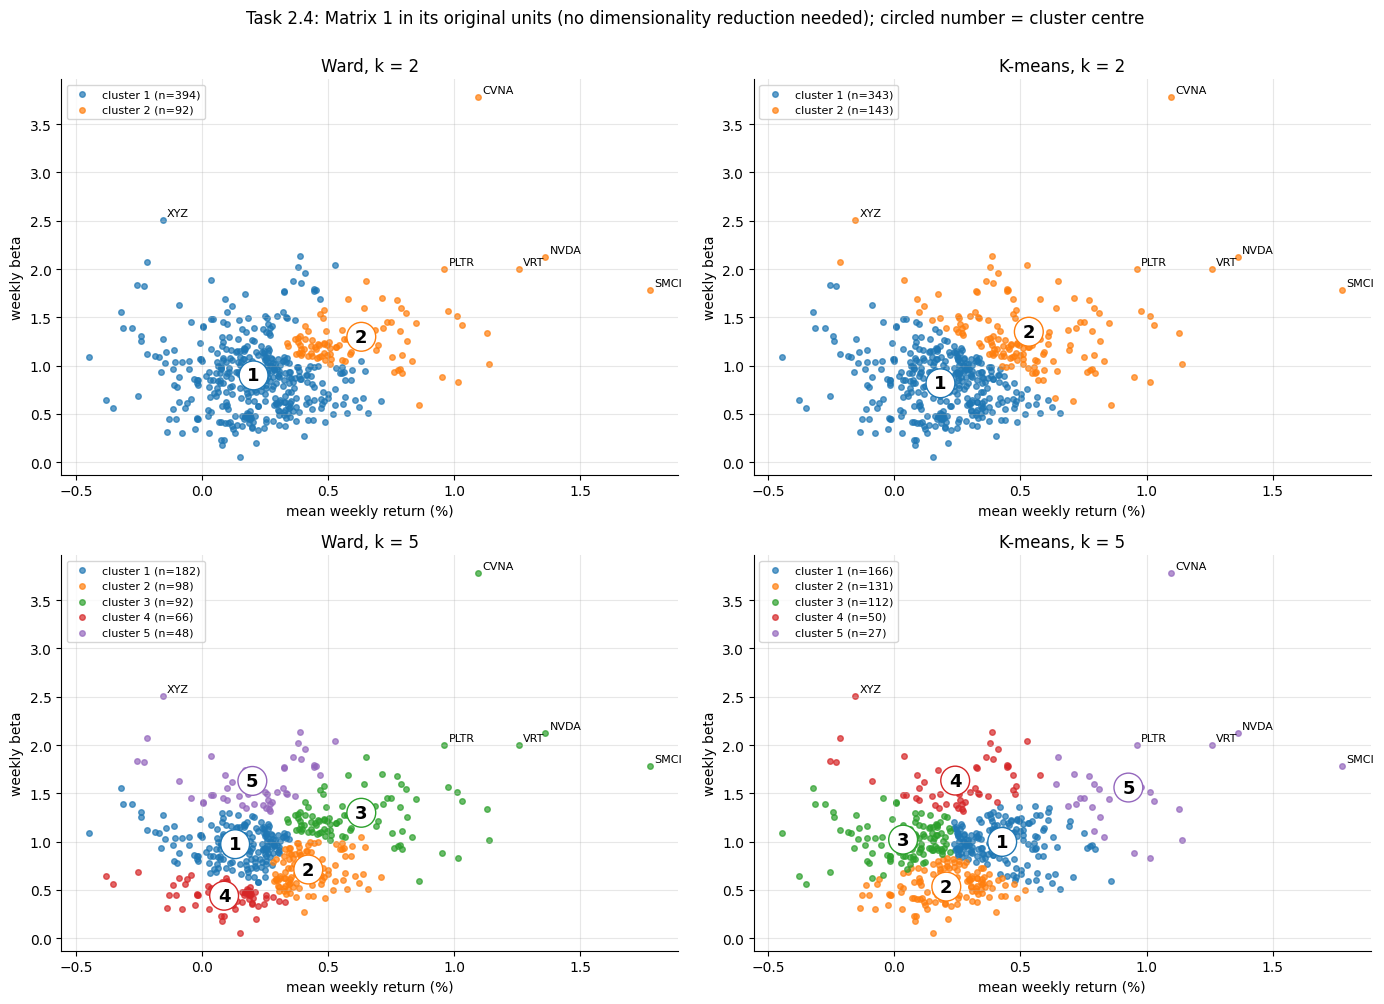

In [ ]:
# TASK 2.4 | Part A2: Matrix 1 drawn on its own two axes (a 2-feature matrix needs no dimensionality reduction; PCA would only rotate it)
x1 = 100 * feature_table["mean_weekly_return"]
far1 = (Z1 ** 2).sum(axis=1).nlargest(6).index
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for a, (algo, store, k) in zip(ax.ravel(), [("Ward", ward_final, ward_k["M1"]), ("K-means", km_final, km_k["M1"]), ("Ward", ward_final, ward_k3["M1"]), ("K-means", km_final, km_k3["M1"])]):
    g = store[("M1", k)]
    check(f"{algo} k={k}: the plotted shares are exactly the 486 clustered shares", g.index.equals(feature_table.index))
    for cl in sorted(g.unique()):
        m = g == cl
        a.scatter(x1[m], feature_table.loc[m, "weekly_beta"], s=16, alpha=0.7, color=plt.cm.tab10(cl - 1), label=f"cluster {cl} (n={int(m.sum())})")
        a.annotate(str(cl), (x1[m].mean(), feature_table.loc[m, "weekly_beta"].mean()), fontsize=13, fontweight="bold", ha="center", va="center",
                   bbox={"boxstyle": "circle", "fc": "white", "ec": plt.cm.tab10(cl - 1)})
    for t in far1:
        a.annotate(t, (x1[t], feature_table.at[t, "weekly_beta"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    a.set(title=f"{algo}, k = {k}", xlabel="mean weekly return (%)", ylabel="weekly beta"); a.legend(fontsize=8, loc="upper left")
fig.suptitle("Task 2.4: Matrix 1 in its original units (no dimensionality reduction needed); circled number = cluster centre", y=1.0)
save_fig("fig21b_task24_matrix1_original_axes")

PASSED: ARI of a clustering with itself is 1
PASSED: ARI ignores the cluster numbers (relabelled labels give the same value)
PASSED: ARI matches a manual calculation from the contingency table

Ward vs K-means, Matrix 1 (return, beta) - same k
 k   ARI  same_cluster_%  silhouette_Ward  silhouette_KMeans
 2 0.598          89.506            0.339              0.387
 3 0.516          81.893            0.274              0.329
 4 0.267          56.790            0.282              0.327
 5 0.318          60.494            0.304              0.341
 6 0.332          64.815            0.320              0.335
 7 0.402          61.934            0.324              0.328
 8 0.666          83.745            0.321              0.354

Ward vs K-means, Matrix 2 (R, F, log1p M) - same k
 k   ARI  same_cluster_%  silhouette_Ward  silhouette_KMeans
 2 0.700          93.827            0.368              0.423
 3 0.834          93.210            0.304              0.325
 4 0.343          67.901         

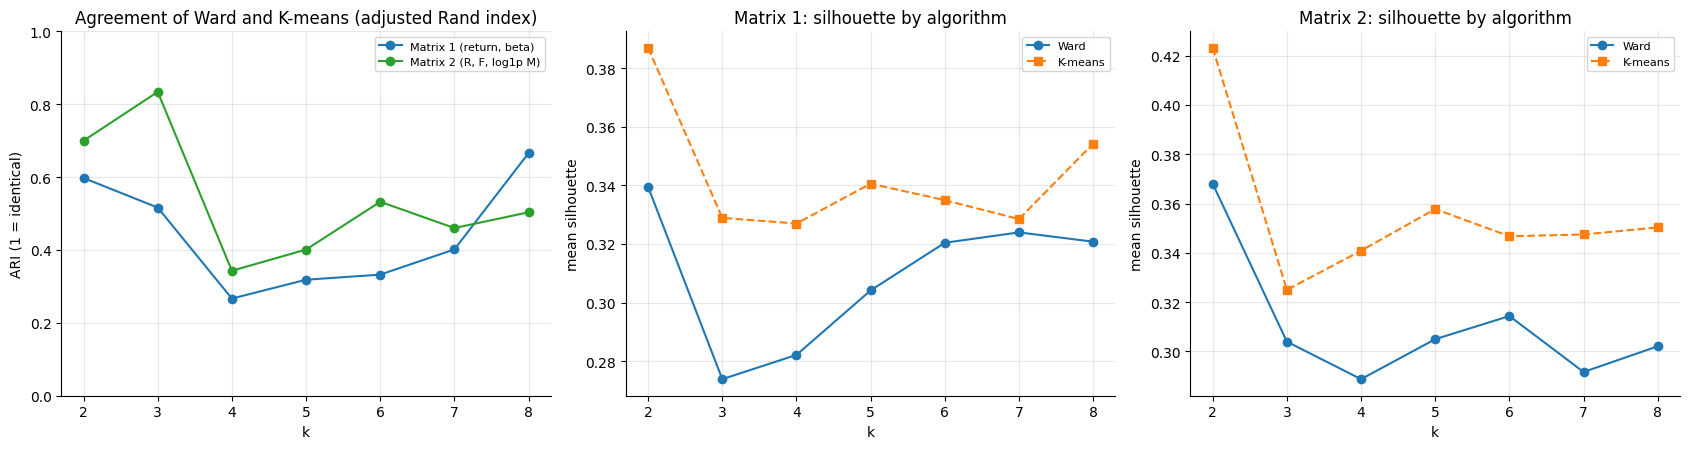

In [ ]:
# TASK 2.4 | Part B: Ward versus K-means on the same 486 shares (adjusted Rand index, memberships, silhouette side by side)
from scipy.optimize import linear_sum_assignment
from scipy.special import comb

def ari_manual(a, b):
    """Adjusted Rand index from the contingency table: 1 = identical groupings, about 0 = no better than chance."""
    t = pd.crosstab(a, b).to_numpy()
    sum_ij, sum_a, sum_b, tot = comb(t, 2).sum(), comb(t.sum(1), 2).sum(), comb(t.sum(0), 2).sum(), comb(t.sum(), 2)
    exp = sum_a * sum_b / tot
    return (sum_ij - exp) / (0.5 * (sum_a + sum_b) - exp)

check("ARI of a clustering with itself is 1", adjusted_rand_score(ward_labels[("M1", 3)], ward_labels[("M1", 3)]) == 1.0)
check("ARI ignores the cluster numbers (relabelled labels give the same value)", adjusted_rand_score(ward_labels[("M2", 3)], km_labels[("M2", 3)]) == adjusted_rand_score(relabel_by_size(ward_labels[("M2", 3)]), km_labels[("M2", 3)]))
check("ARI matches a manual calculation from the contingency table", np.isclose(ari_manual(ward_labels[("M1", 5)], km_labels[("M1", 5)]), adjusted_rand_score(ward_labels[("M1", 5)], km_labels[("M1", 5)])))

rows = []
for n in ["M1", "M2"]:
    for k in range(2, 9):
        ct = pd.crosstab(ward_labels[(n, k)], km_labels[(n, k)]).to_numpy()
        r_, c_ = linear_sum_assignment(-ct)                                  # best one-to-one matching of Ward and K-means clusters
        rows.append({"matrix": n, "k": k, "ARI": adjusted_rand_score(ward_labels[(n, k)], km_labels[(n, k)]),
                     "same_cluster_%": 100 * ct[r_, c_].sum() / ct.sum(),
                     "silhouette_Ward": ward_scores[n].at[k, "silhouette"], "silhouette_KMeans": km_scores[n].at[k, "silhouette"]})
cmp_ = pd.DataFrame(rows)
cmp_.to_csv(f"{DATA_DIR}/ward_vs_kmeans_comparison.csv", index=False)
for n in ["M1", "M2"]:
    print(f"\nWard vs K-means, {'Matrix 1 (return, beta)' if n == 'M1' else 'Matrix 2 (R, F, log1p M)'} - same k")
    print(cmp_[cmp_["matrix"] == n].drop(columns="matrix").round(3).to_string(index=False))

# Memberships: cluster numbers are by size (1 = largest) in each algorithm
for n, kw, kk in [("M1", ward_k["M1"], km_k["M1"]), ("M2", ward_k["M2"], km_k["M2"]), ("M1", ward_k3["M1"], km_k3["M1"]), ("M2", ward_k3["M2"], km_k3["M2"])]:
    ct = pd.crosstab(ward_final[(n, kw)].rename("Ward"), km_final[(n, kk)].rename("K-means"))
    check(f"{n}: Ward k={kw} vs K-means k={kk} table covers all 486 shares", int(ct.to_numpy().sum()) == 486)
    print(f"\n{n}: Ward k={kw} (rows) against K-means k={kk} (columns); ARI {adjusted_rand_score(ward_final[(n, kw)], km_final[(n, kk)]):.3f}")
    print(ct.to_string())

# Do the return/beta segments and the RFM segments describe the same shares?
for algo, store, kk in [("Ward", ward_final, ward_k), ("K-means", km_final, km_k)]:
    print(f"\n{algo}, formal k: ARI between Matrix 1 and Matrix 2 segments = {adjusted_rand_score(store[('M1', kk['M1'])], store[('M2', kk['M2'])]):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for n, colour in [("M1", "tab:blue"), ("M2", "tab:green")]:
    d = cmp_[cmp_["matrix"] == n]
    ax[0].plot(d["k"], d["ARI"], "o-", color=colour, label="Matrix 1 (return, beta)" if n == "M1" else "Matrix 2 (R, F, log1p M)")
ax[0].set(title="Agreement of Ward and K-means (adjusted Rand index)", xlabel="k", ylabel="ARI (1 = identical)", ylim=(0, 1)); ax[0].legend(fontsize=8)
for a, n, title in [(ax[1], "M1", "Matrix 1"), (ax[2], "M2", "Matrix 2")]:
    d = cmp_[cmp_["matrix"] == n]
    a.plot(d["k"], d["silhouette_Ward"], "o-", label="Ward"); a.plot(d["k"], d["silhouette_KMeans"], "s--", label="K-means")
    a.set(title=f"{title}: silhouette by algorithm", xlabel="k", ylabel="mean silhouette"); a.legend(fontsize=8)
save_fig("fig23_task24_ward_vs_kmeans")

PASSED: correlation matrices are symmetric with 1 on the diagonal
PASSED: Pearson matches a manual calculation (Frequency vs log1p Monetary)
PASSED: standardising does not change the correlations
PASSED: Spearman equals Pearson on the ranks
Pearson correlation (original units, Monetary on log1p scale):
                recency_days  frequency_60d  log1p_monetary
recency_days           1.000         -0.346           0.152
frequency_60d         -0.346          1.000           0.013
log1p_monetary         0.152          0.013           1.000

Spearman rank correlation (not affected by the Recency spike or by outliers):
                recency_days  frequency_60d  log1p_monetary
recency_days           1.000         -0.196           0.137
frequency_60d         -0.196          1.000          -0.048
log1p_monetary         0.137         -0.048           1.000

For reference, correlation with RAW Monetary: Recency 0.300 | Frequency 0.014 | log1p(M) 0.591
Strongest pair (Pearson): ('recency_days'

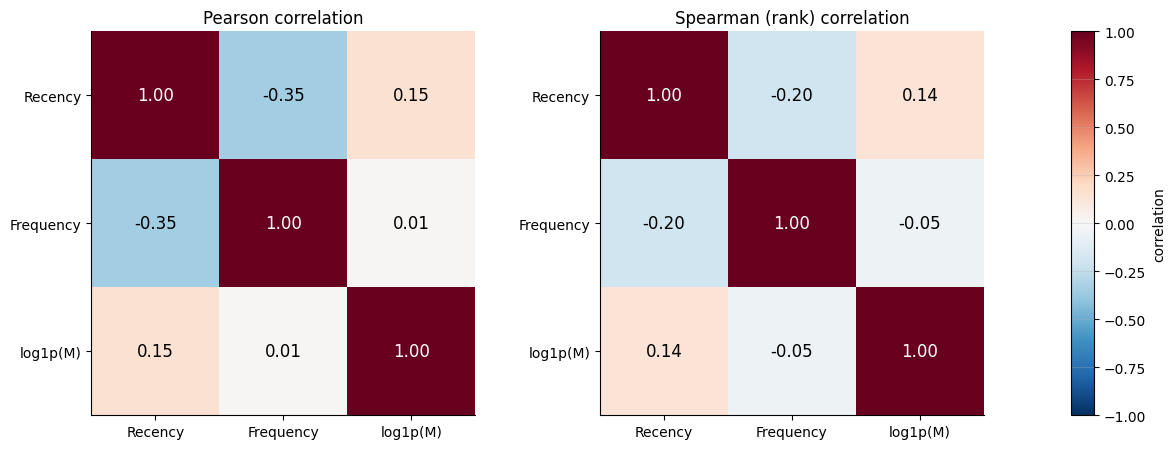

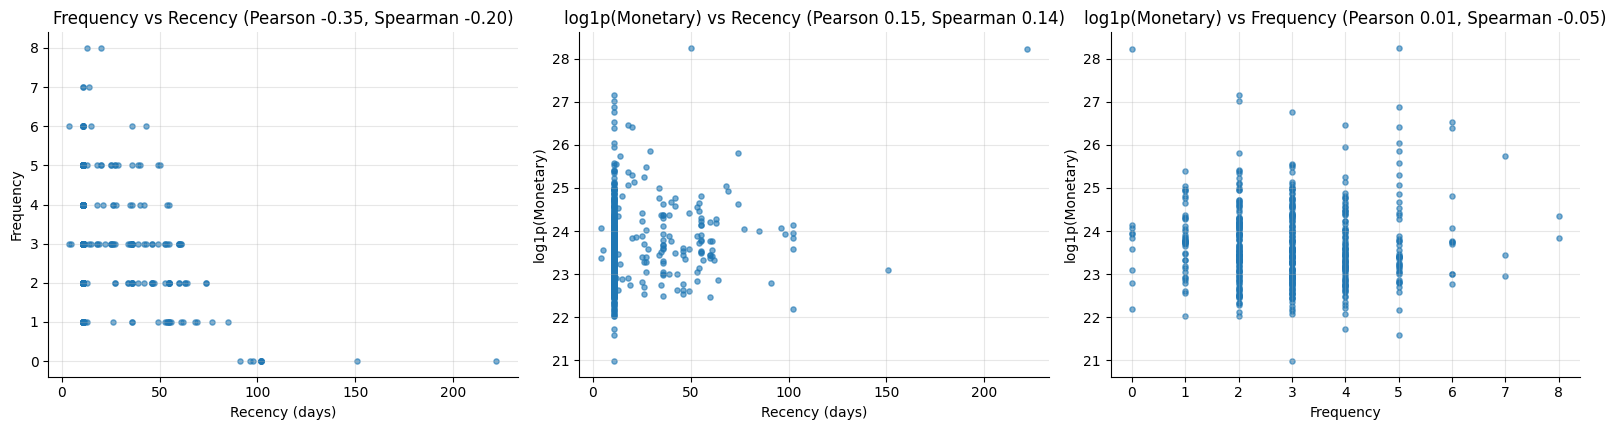

In [ ]:
# TASK 2.5 | Part A: correlations between Recency, Frequency and log1p(Monetary)
R3 = feature_table[M2_COLS]
pear, spear = R3.corr(method="pearson"), R3.corr(method="spearman")
check("correlation matrices are symmetric with 1 on the diagonal", np.allclose(pear, pear.T) and np.allclose(np.diag(pear), 1) and np.allclose(spear, spear.T))
check("Pearson matches a manual calculation (Frequency vs log1p Monetary)", np.isclose(pear.at["frequency_60d", "log1p_monetary"],
      ((R3["frequency_60d"] - R3["frequency_60d"].mean()) * (R3["log1p_monetary"] - R3["log1p_monetary"].mean())).sum() / ((len(R3) - 1) * R3["frequency_60d"].std() * R3["log1p_monetary"].std())))
check("standardising does not change the correlations", np.allclose(Z2.corr(), pear))
check("Spearman equals Pearson on the ranks", np.allclose(R3.rank().corr(), spear))
print("Pearson correlation (original units, Monetary on log1p scale):")
print(pear.round(3).to_string())
print("\nSpearman rank correlation (not affected by the Recency spike or by outliers):")
print(spear.round(3).to_string())
raw_m = feature_table["monetary_usd"]
print(f"\nFor reference, correlation with RAW Monetary: Recency {feature_table['recency_days'].corr(raw_m):.3f} | Frequency {feature_table['frequency_60d'].corr(raw_m):.3f} | log1p(M) {feature_table['log1p_monetary'].corr(raw_m):.3f}")
print("Strongest pair (Pearson):", pear.where(~np.eye(3, dtype=bool)).abs().stack().idxmax(), "| weakest pair:", pear.where(~np.eye(3, dtype=bool)).abs().stack().idxmin())
pear.to_csv(f"{DATA_DIR}/rfm_correlation_pearson.csv"); spear.to_csv(f"{DATA_DIR}/rfm_correlation_spearman.csv")

short = ["Recency", "Frequency", "log1p(M)"]
fig, ax = plt.subplots(1, 3, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1, 0.05]})     # third axis holds the colour bar, so nothing overlaps
for a, cm, title in [(ax[0], pear, "Pearson"), (ax[1], spear, "Spearman (rank)")]:
    im = a.imshow(cm.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    a.set(xticks=range(3), yticks=range(3), xticklabels=short, yticklabels=short, title=f"{title} correlation"); a.grid(False)
    for i in range(3):
        for j in range(3):
            a.text(j, i, f"{cm.iat[i, j]:.2f}", ha="center", va="center", fontsize=12, color="white" if abs(cm.iat[i, j]) > 0.6 else "black")
fig.colorbar(im, cax=ax[2], label="correlation")
save_fig("fig24_task25_rfm_correlation")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, (x, y, lx, ly) in zip(ax, [("recency_days", "frequency_60d", "Recency (days)", "Frequency"), ("recency_days", "log1p_monetary", "Recency (days)", "log1p(Monetary)"),
                                  ("frequency_60d", "log1p_monetary", "Frequency", "log1p(Monetary)")]):
    a.scatter(feature_table[x], feature_table[y], s=14, alpha=0.6)
    a.set(title=f"{ly} vs {lx.split(' (')[0]} (Pearson {pear.at[x, y]:.2f}, Spearman {spear.at[x, y]:.2f})", xlabel=lx, ylabel=ly)
save_fig("fig25_task25_rfm_pairs")

In [ ]:
# TASK 2.5 | Part A2: how much do Recency, Frequency and log1p(M) overlap? VIF, principal-axis variance, effective dimensions, and how much each feature drives the clusters
C = R3.corr().to_numpy()
vif = pd.Series(np.diag(np.linalg.inv(C)), index=M2_COLS, name="VIF")
eigvals = np.sort(np.linalg.eigvalsh(C))[::-1]
share = eigvals / eigvals.sum()
eff_dim = eigvals.sum() ** 2 / (eigvals ** 2).sum()
for j, c in enumerate(M2_COLS):                                  # manual check: VIF = 1 / (1 - R squared) when the feature is predicted from the other two
    others = [o for o in M2_COLS if o != c]
    A = np.column_stack([np.ones(len(Z2)), Z2[others].to_numpy()])
    resid = Z2[c].to_numpy() - A @ np.linalg.lstsq(A, Z2[c].to_numpy(), rcond=None)[0]
    check(f"VIF of {c} matches 1 / (1 - R squared) from a regression on the other two", np.isclose(vif[c], 1 / (resid @ resid / (Z2[c] ** 2).sum())))
check("the three principal-axis variances add up to 3 (one per standardised feature)", np.isclose(eigvals.sum(), 3))
print("Variance inflation factor (1 = a feature shares nothing with the others; above 5 would be a worry):")
print(vif.round(3).to_string())
print("\nShare of total variance on each principal axis (equal thirds would mean no overlap):", np.round(100 * share, 1).tolist(), "%")
print(f"Effective number of independent dimensions: {eff_dim:.2f} out of 3")

def eta_squared(values, labels):
    g = pd.Series(np.asarray(values, float)).groupby(np.asarray(labels))
    return float((g.size() * (g.mean() - np.mean(values)) ** 2).sum() / ((np.asarray(values, float) - np.mean(values)) ** 2).sum())
rows = []
for k in sorted({ward_k["M2"], ward_k3["M2"]}):
    for c in M2_COLS:
        rows.append({"k": k, "feature": c, "share_of_feature_explained_by_Ward_clusters_%": 100 * eta_squared(Z2[c], ward_final[("M2", k)].reindex(Z2.index))})
eta = pd.DataFrame(rows)
check("eta squared stays between 0 and 100%", eta.iloc[:, 2].between(0, 100).all())
print("\nHow much of each feature the Ward clusters explain (a feature with a big share is driving the grouping):")
print(eta.round(1).to_string(index=False))
eta.to_csv(f"{DATA_DIR}/rfm_feature_influence.csv", index=False)

PASSED: VIF of recency_days matches 1 / (1 - R squared) from a regression on the other two
PASSED: VIF of frequency_60d matches 1 / (1 - R squared) from a regression on the other two
PASSED: VIF of log1p_monetary matches 1 / (1 - R squared) from a regression on the other two
PASSED: the three principal-axis variances add up to 3 (one per standardised feature)
Variance inflation factor (1 = a feature shares nothing with the others; above 5 would be a worry):
recency_days      1.169
frequency_60d     1.142
log1p_monetary    1.029

Share of total variance on each principal axis (equal thirds would mean no overlap): [45.8, 33.6, 20.6] %
Effective number of independent dimensions: 2.74 out of 3
PASSED: eta squared stays between 0 and 100%

How much of each feature the Ward clusters explain (a feature with a big share is driving the grouping):
 k        feature  share_of_feature_explained_by_Ward_clusters_%
 2   recency_days                                           64.1
 2  frequency_60d   

PASSED: reduced matrix has the same 486 shares in the same order and no Monetary
PASSED: fresh standardisation of the reduced matrix has mean 0 and SD 1
PASSED: the fresh z-scores equal the earlier ones (each column is standardised on its own)
PASSED: reduced Ward: scipy and scikit-learn give the same 3 clusters
PASSED: reduced Ward k=2: exactly 2 clusters
PASSED: reduced Ward k=3: exactly 3 clusters
PASSED: reduced Ward k=4: exactly 4 clusters
PASSED: reduced Ward k=5: exactly 5 clusters
PASSED: reduced Ward k=6: exactly 6 clusters
PASSED: reduced Ward k=7: exactly 7 clusters
PASSED: reduced Ward k=8: exactly 8 clusters
PASSED: variance explained is between 0 and 100%
PASSED: variance explained matches a manual within-cluster calculation (reduced, k=3)
Ward on R and F only, against the full Ward (R, F, log1p M), same k:
 k  ARI_full_vs_reduced  silhouette_reduced  silhouette_full  log1pM_variance_explained_full_%  log1pM_variance_explained_reduced_%
 2                0.873            

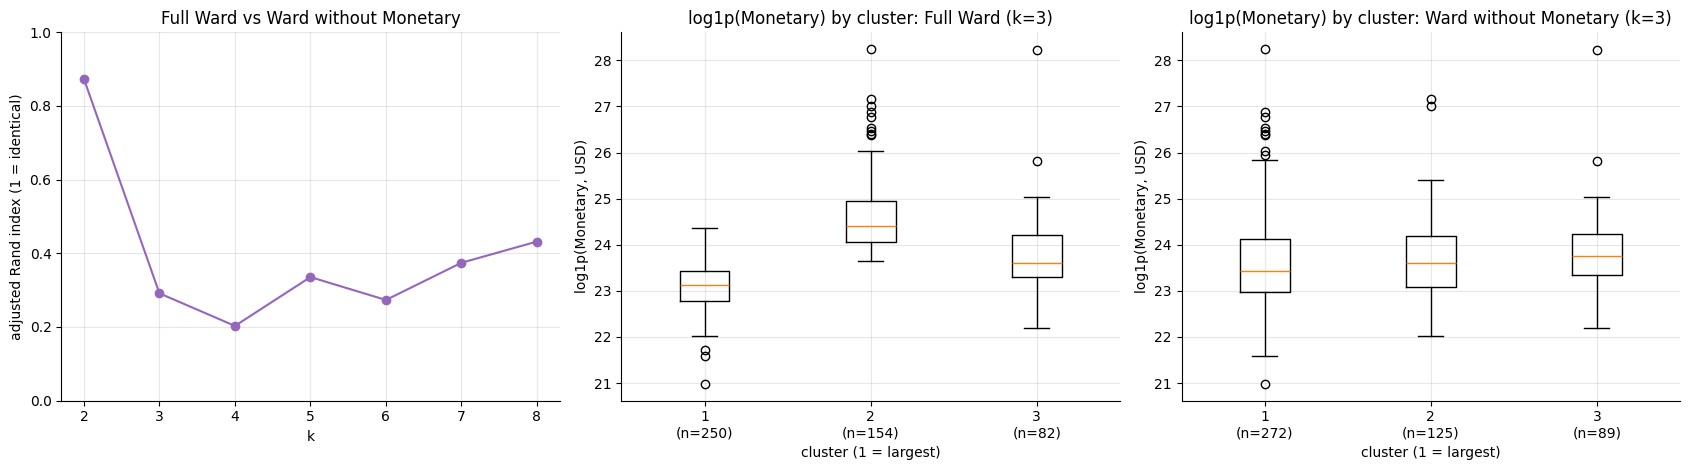

In [ ]:
# TASK 2.5 | Part B: remove Monetary, re-run Ward on Recency and Frequency only, compare with the full Ward (adjusted Rand index) and profile traded value
RF_COLS = ["recency_days", "frequency_60d"]
Z_rf = pd.DataFrame(StandardScaler().fit_transform(feature_table.loc[Z2.index, RF_COLS]), index=Z2.index, columns=RF_COLS)     # standardised afresh on R and F only
check("reduced matrix has the same 486 shares in the same order and no Monetary", Z_rf.index.equals(Z2.index) and list(Z_rf.columns) == RF_COLS)
check("fresh standardisation of the reduced matrix has mean 0 and SD 1", np.allclose(Z_rf.mean(), 0, atol=1e-9) and np.allclose(Z_rf.std(ddof=0), 1))
check("the fresh z-scores equal the earlier ones (each column is standardised on its own)", np.allclose(Z_rf, Z2[RF_COLS]))
link_rf = linkage(Z_rf.to_numpy(), method="ward", metric="euclidean")
check("reduced Ward: scipy and scikit-learn give the same 3 clusters",
      adjusted_rand_score(fcluster(link_rf, 3, "maxclust"), AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Z_rf.to_numpy())) == 1.0)

tv = feature_table.loc[Z2.index, "log1p_monetary"]
def share_of_variance_explained(values, labels):
    """Between-cluster sum of squares / total sum of squares (0 = clusters say nothing about the value, 1 = clusters explain it fully)."""
    g = pd.Series(values.to_numpy(), index=values.index).groupby(labels)
    return float((g.size() * (g.mean() - values.mean()) ** 2).sum() / ((values - values.mean()) ** 2).sum())

rows = []
for k in range(2, 9):
    lab_full, lab_rf = ward_labels[("M2", k)], fcluster(link_rf, k, "maxclust")
    check(f"reduced Ward k={k}: exactly {k} clusters", len(np.unique(lab_rf)) == k)
    rows.append({"k": k, "ARI_full_vs_reduced": adjusted_rand_score(lab_full, lab_rf), "silhouette_reduced": silhouette_score(Z_rf, lab_rf),
                 "silhouette_full": ward_scores["M2"].at[k, "silhouette"], "log1pM_variance_explained_full_%": 100 * share_of_variance_explained(tv, lab_full),
                 "log1pM_variance_explained_reduced_%": 100 * share_of_variance_explained(tv, lab_rf)})
rf_cmp = pd.DataFrame(rows)
check("variance explained is between 0 and 100%", rf_cmp.filter(like="explained").to_numpy().min() >= 0 and rf_cmp.filter(like="explained").to_numpy().max() <= 100)
manual = 1 - sum(((tv[fcluster(link_rf, 3, 'maxclust') == c] - tv[fcluster(link_rf, 3, 'maxclust') == c].mean()) ** 2).sum() for c in range(1, 4)) / ((tv - tv.mean()) ** 2).sum()
check("variance explained matches a manual within-cluster calculation (reduced, k=3)", np.isclose(100 * manual, rf_cmp.set_index("k").at[3, "log1pM_variance_explained_reduced_%"]))
rf_cmp.to_csv(f"{DATA_DIR}/ward_without_monetary_comparison.csv", index=False)
print("Ward on R and F only, against the full Ward (R, F, log1p M), same k:")
print(rf_cmp.round(3).to_string(index=False))

# Memberships and traded-value profiles for the reduced clustering, at the full model's k values
rf_final = {}
for k in sorted({ward_k["M2"], ward_k3["M2"]}):
    g = pd.Series(relabel_by_size(fcluster(link_rf, k, "maxclust")), index=Z2.index, name="cluster")
    rf_final[k] = g
    ct = pd.crosstab(ward_final[("M2", k)].rename("full Ward"), g.rename("without Monetary"))
    check(f"k={k}: membership table covers all 486 shares", int(ct.to_numpy().sum()) == 486)
    print(f"\nk = {k}: full Ward (rows) against Ward without Monetary (columns); ARI {adjusted_rand_score(ward_final[('M2', k)], g):.3f}")
    print(ct.to_string())
    ft = feature_table.loc[Z2.index]
    for title, grp in [("without Monetary", g), ("full Ward", ward_final[("M2", k)])]:
        prof = pd.DataFrame({"shares": grp.value_counts().sort_index(), "median_recency_days": ft["recency_days"].groupby(grp).median(),
                             "mean_frequency_60d": ft["frequency_60d"].groupby(grp).mean().round(2),
                             "median_traded_value_USD_bn": (ft["monetary_usd"].groupby(grp).median() / 1e9).round(1),
                             "mean_log1p_M": ft["log1p_monetary"].groupby(grp).mean().round(2)})
        print(f"  Profile, {title}, k={k}:")
        print(prof.to_string())
    g.to_csv(f"{DATA_DIR}/ward_without_monetary_k{k}_clusters.csv")

kb = ward_k3["M2"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(rf_cmp["k"], rf_cmp["ARI_full_vs_reduced"], "o-", color="tab:purple")
ax[0].set(title="Full Ward vs Ward without Monetary", xlabel="k", ylabel="adjusted Rand index (1 = identical)", ylim=(0, 1))
for a, grp, title in [(ax[1], ward_final[("M2", kb)], f"Full Ward (k={kb})"), (ax[2], rf_final[kb], f"Ward without Monetary (k={kb})")]:
    cl = sorted(grp.unique())
    a.boxplot([tv[grp == c] for c in cl])
    a.set_xticks(range(1, len(cl) + 1)); a.set_xticklabels([f"{c}\n(n={int((grp == c).sum())})" for c in cl])
    a.set(title=f"log1p(Monetary) by cluster: {title}", xlabel="cluster (1 = largest)", ylabel="log1p(Monetary, USD)")
save_fig("fig26_task25_ward_without_monetary")

PASSED: the last drift date is the study's observation date
PASSED: every drift date has at least 80 sessions of history (20-session baseline + 60-session window)
PASSED: rebuilding Matrix 2 at the observation date reproduces the saved feature table
PASSED: 2023-12-29: no missing values in Matrix 2
PASSED: 2024-01-31: no missing values in Matrix 2
PASSED: 2024-02-29: no missing values in Matrix 2
PASSED: 2024-03-28: no missing values in Matrix 2
PASSED: 2024-04-30: no missing values in Matrix 2
PASSED: 2024-05-31: no missing values in Matrix 2
PASSED: 2024-06-28: no missing values in Matrix 2
PASSED: 2024-07-31: no missing values in Matrix 2
PASSED: 2024-08-30: no missing values in Matrix 2
PASSED: 2024-09-30: no missing values in Matrix 2
PASSED: 2024-10-31: no missing values in Matrix 2
PASSED: 2024-11-29: no missing values in Matrix 2
PASSED: 2024-12-31: no missing values in Matrix 2
PASSED: k=2: the pipeline at the observation date reproduces the earlier Ward clusters (ARI = 1)
PAS

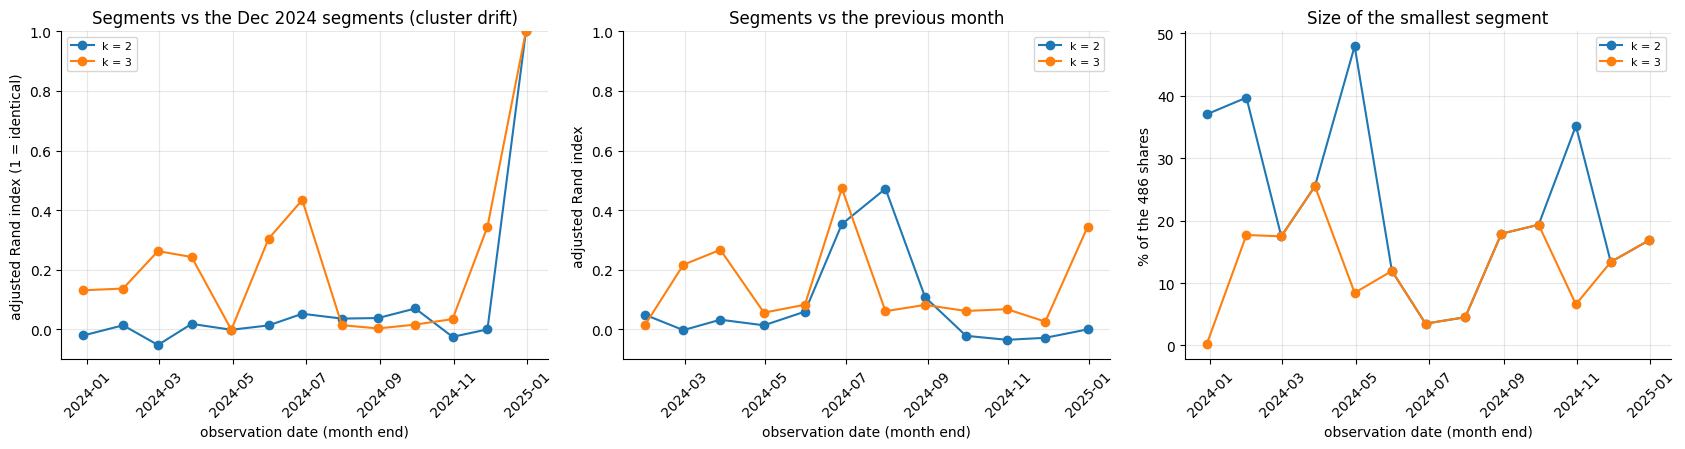

In [ ]:
# TASK 2 | Experiment D (cluster drift): do the Matrix 2 (R, F, log1p M) Ward segments stay stable when the observation date moves?
drift_dates = []
for ym in pd.period_range("2023-12", "2024-12", freq="M"):                       # last trading day of each month, Dec 2023 to Dec 2024
    drift_dates.append(trading_days[trading_days <= ym.to_timestamp(how="end").normalize()][-1])
check("the last drift date is the study's observation date", drift_dates[-1] == OBS_DATE)
check("every drift date has at least 80 sessions of history (20-session baseline + 60-session window)", all(trading_days.get_loc(d) >= 79 for d in drift_dates))

def matrix2_at(d):
    r = rfm_at(d).loc[feature_table.index]
    return pd.DataFrame({"recency_days": r["recency_days"], "frequency_60d": r["frequency_60d"], "log1p_monetary": np.log1p(r["monetary_usd"])})

base = matrix2_at(OBS_DATE)
check("rebuilding Matrix 2 at the observation date reproduces the saved feature table", np.allclose(base.to_numpy(float), feature_table[M2_COLS].to_numpy(float)))

DRIFT_KS = sorted({ward_k["M2"], ward_k3["M2"]})
snap = {}
for d in drift_dates:
    X = matrix2_at(d)
    check(f"{d.date()}: no missing values in Matrix 2", not X.isna().any().any())
    Zd = StandardScaler().fit_transform(X.to_numpy(float))                      # standardised on this date's own distribution
    Ld = linkage(Zd, method="ward", metric="euclidean")
    snap[d] = {k: fcluster(Ld, k, "maxclust") for k in DRIFT_KS}
    snap[d]["Z"] = Zd
for k in DRIFT_KS:
    check(f"k={k}: the pipeline at the observation date reproduces the earlier Ward clusters (ARI = 1)", adjusted_rand_score(snap[OBS_DATE][k], ward_labels[("M2", k)]) == 1.0)

rows = []
for k in DRIFT_KS:
    prev = None
    for d in drift_dates:
        lab = snap[d][k]
        ct = pd.crosstab(lab, ward_labels[("M2", k)]).to_numpy()
        r_, c_ = linear_sum_assignment(-ct)
        sizes = np.sort(np.bincount(lab)[1:])[::-1]
        rows.append({"k": k, "date": d.date(), "silhouette": silhouette_score(snap[d]["Z"], lab), "ARI_vs_Dec2024": adjusted_rand_score(lab, ward_labels[("M2", k)]),
                     "same_cluster_%_vs_Dec2024": 100 * ct[r_, c_].sum() / ct.sum(), "ARI_vs_previous_month": np.nan if prev is None else adjusted_rand_score(lab, prev),
                     "smallest_cluster_%": 100 * sizes[-1] / len(lab), "sizes": sizes.tolist()})
        prev = lab
drift = pd.DataFrame(rows)
drift.to_csv(f"{DATA_DIR}/cluster_drift_ward_matrix2.csv", index=False)
for k in DRIFT_KS:
    print(f"\nCluster drift, Ward on Matrix 2 (R, F, log1p M), k = {k} (each date standardised on its own data)")
    print(drift[drift["k"] == k].drop(columns="k").round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for k, colour in zip(DRIFT_KS, ["tab:blue", "tab:orange", "tab:green"]):
    d_k = drift[drift["k"] == k]
    x = pd.to_datetime(d_k["date"])
    ax[0].plot(x, d_k["ARI_vs_Dec2024"], "o-", color=colour, label=f"k = {k}")
    ax[1].plot(x, d_k["ARI_vs_previous_month"], "o-", color=colour, label=f"k = {k}")
    ax[2].plot(x, d_k["smallest_cluster_%"], "o-", color=colour, label=f"k = {k}")
ax[0].set(title="Segments vs the Dec 2024 segments (cluster drift)", ylabel="adjusted Rand index (1 = identical)", ylim=(-0.1, 1))
ax[1].set(title="Segments vs the previous month", ylabel="adjusted Rand index", ylim=(-0.1, 1))
ax[2].set(title="Size of the smallest segment", ylabel="% of the 486 shares")
for a in ax:
    a.legend(fontsize=8); a.tick_params(axis="x", rotation=45); a.set_xlabel("observation date (month end)")
save_fig("fig27_task2_cluster_drift")

# **TASK 03**

In [ ]:
# TASK 3.1.1 | Part A: the four dimension tables (share, sector, date, benchmark) of the data mart
MART_DIR = f"{DATA_DIR}/mart"
os.makedirs(MART_DIR, exist_ok=True)
RUN_ID = f"RFM_{OBS_DATE.date()}_v1"      # one run = one observation date + one calculation version (reused in Task 3.1.2)

dim_sector = (inclusion_log.groupby("sector").agg(shares_in_index=("included", "size"), shares_retained=("included", "sum"))
              .reset_index().rename(columns={"sector": "sector_name"}))
dim_sector.insert(0, "sector_key", range(1, len(dim_sector) + 1))

dim_share = inclusion_log.reset_index()[["ticker", "company", "sector", "Date added", "included", "exclusion_reason"]]
dim_share = dim_share.rename(columns={"Date added": "date_added_to_index"})
dim_share["sector_key"] = dim_share["sector"].map(dim_sector.set_index("sector_name")["sector_key"])
dim_share = dim_share.drop(columns="sector")
dim_share.insert(0, "share_key", range(1, len(dim_share) + 1))
dim_share["exclusion_reason"] = dim_share["exclusion_reason"].fillna("")

week_end = trading_days + pd.to_timedelta((4 - trading_days.dayofweek) % 7, unit="D")      # the Friday that ends each day's week
dim_date = pd.DataFrame({"date_key": trading_days.strftime("%Y%m%d").astype(int), "date": trading_days, "year": trading_days.year,
                         "quarter": trading_days.quarter, "month": trading_days.month, "week_ending_friday": week_end,
                         "session_no": np.arange(1, len(trading_days) + 1),
                         "is_observation_date": trading_days == OBS_DATE, "in_final_60_session_window": trading_days.isin(WIN)})

dim_benchmark = pd.DataFrame({"benchmark_key": [1], "symbol": [BENCH], "name": ["S&P 500 index"],
                              "type": ["price index (dividends not reinvested)"], "source": [info["price_source"]]})

check("dim_share holds all 503 index members: 486 retained, 17 excluded", len(dim_share) == 503 and int(dim_share["included"].sum()) == 486)
check("dim_share: ticker and share_key are unique", dim_share["ticker"].is_unique and dim_share["share_key"].is_unique)
check("dim_share: every share has a sector key that exists in dim_sector", dim_share["sector_key"].notna().all() and dim_share["sector_key"].isin(dim_sector["sector_key"]).all())
check("dim_sector: counts add up to 503 members and 486 retained shares", dim_sector["shares_in_index"].sum() == 503 and dim_sector["shares_retained"].sum() == 486)
sector_of = dim_share.merge(dim_sector, on="sector_key").set_index("ticker")["sector_name"]
check("sector in the mart equals the sector in the Task 1 feature table for every retained share", (sector_of.loc[feature_table.index] == feature_table["sector"]).all())
check("dim_date: one row per trading day, unique keys, week endings are Fridays",
      len(dim_date) == len(trading_days) and dim_date["date_key"].is_unique and (dim_date["week_ending_friday"].dt.dayofweek == 4).all())
check("dim_date: exactly one observation date and a 60-session window", dim_date["is_observation_date"].sum() == 1 and dim_date["in_final_60_session_window"].sum() == 60)

print(f"dim_share {len(dim_share)} rows | dim_sector {len(dim_sector)} | dim_date {len(dim_date)} | dim_benchmark {len(dim_benchmark)} | run id {RUN_ID}")
print(dim_sector.to_string(index=False))
print(dim_date.tail(2).to_string(index=False))

PASSED: dim_share holds all 503 index members: 486 retained, 17 excluded
PASSED: dim_share: ticker and share_key are unique
PASSED: dim_share: every share has a sector key that exists in dim_sector
PASSED: dim_sector: counts add up to 503 members and 486 retained shares
PASSED: sector in the mart equals the sector in the Task 1 feature table for every retained share
PASSED: dim_date: one row per trading day, unique keys, week endings are Fridays
PASSED: dim_date: exactly one observation date and a 60-session window
dim_share 503 rows | dim_sector 11 | dim_date 1005 | dim_benchmark 1 | run id RFM_2024-12-31_v1
 sector_key            sector_name  shares_in_index  shares_retained
          1 Communication Services               22               20
          2 Consumer Discretionary               47               47
          3       Consumer Staples               33               32
          4                 Energy               21               20
          5             Financials    

In [ ]:
# TASK 3.1.1 | Part B: daily fact table - one row per retained share per trading day, with the derived daily metrics
def long(panel, name):
    return panel.rename_axis("date").reset_index().melt("date", var_name="ticker", value_name=name)

f = long(c_inc, "close").merge(long(a_inc, "adj_close"), on=["date", "ticker"]).merge(long(v_inc, "volume"), on=["date", "ticker"])
f = f.sort_values(["ticker", "date"]).reset_index(drop=True)
g = f.groupby("ticker", sort=False)
f["traded_value_usd"] = f["close"] * f["volume"]                                              # Close x Volume, as in Monetary
f["daily_return"] = g["adj_close"].pct_change(fill_method=None)                               # Adj Close, as in the weekly returns
f["baseline_vol_20d"] = g["volume"].transform(lambda s: s.rolling(20).mean().shift(1))        # preceding 20 sessions only
f["high_volume_flag"] = (f["volume"] > 2.0 * f["baseline_vol_20d"]) & f["baseline_vol_20d"].notna()
f["date_key"] = f["date"].dt.strftime("%Y%m%d").astype(int)
f["share_key"] = f["ticker"].map(dim_share.set_index("ticker")["share_key"])
fact_share_day = f[["date_key", "share_key", "close", "adj_close", "volume", "traded_value_usd", "daily_return", "baseline_vol_20d", "high_volume_flag"]].copy()

n_sh, n_td = len(included), len(trading_days)
check("grain: (date_key, share_key) is unique", not fact_share_day.duplicated(["date_key", "share_key"]).any())
check(f"row count is exactly {n_sh} shares x {n_td} trading days", len(fact_share_day) == n_sh * n_td)
check("every retained share appears on every trading day", (fact_share_day.groupby("share_key").size() == n_td).all())
check("keys resolve to dim_share and dim_date", fact_share_day["share_key"].isin(dim_share["share_key"]).all() and fact_share_day["date_key"].isin(dim_date["date_key"]).all())
check("the shares in the fact are exactly the retained shares of dim_share", set(fact_share_day["share_key"]) == set(dim_share.loc[dim_share["included"], "share_key"]))

t0 = included[0]; k0 = int(dim_share.set_index("ticker").at[t0, "share_key"])
manual = a_inc[t0].to_numpy()[1:] / a_inc[t0].to_numpy()[:-1] - 1
check("daily return equals Adj Close / previous Adj Close - 1 (manual, first share)", np.allclose(fact_share_day.query("share_key == @k0")["daily_return"].to_numpy()[1:], manual))
check("only each share's first day has a missing return", fact_share_day["daily_return"].isna().sum() == n_sh)
check("traded value equals Close x Volume, not Adj Close x Volume", np.allclose(fact_share_day["traded_value_usd"], fact_share_day["close"] * fact_share_day["volume"]))
wide = lambda col: fact_share_day.pivot(index="date_key", columns="share_key", values=col).set_axis(trading_days).set_axis(included, axis=1)
check("20-day baseline equals the Task 1.4 baseline for every share-day", np.allclose(wide("baseline_vol_20d").to_numpy(float), baseline.to_numpy(float), equal_nan=True))
fl = wide("high_volume_flag").astype(bool)
check("event flags equal the Task 1.4 flags in memory", fl.equals(flags.astype(bool)))
saved = pd.read_csv(f"{DATA_DIR}/high_volume_flags.csv", index_col=0, parse_dates=True).astype(bool)
check("event flags equal the saved high_volume_flags.csv", fl.equals(saved.loc[trading_days, included]))

fact_share_day.to_csv(f"{MART_DIR}/fact_share_day.csv.gz", index=False, compression="gzip")
print(f"\nfact_share_day: {len(fact_share_day):,} rows ({n_sh} shares x {n_td} trading days), {int(fact_share_day['high_volume_flag'].sum()):,} high-volume share-days")
print(fact_share_day.head(3).round(4).to_string(index=False))
print("saved:", round(os.path.getsize(f"{MART_DIR}/fact_share_day.csv.gz") / 1e6, 1), "MB")

PASSED: grain: (date_key, share_key) is unique
PASSED: row count is exactly 486 shares x 1005 trading days
PASSED: every retained share appears on every trading day
PASSED: keys resolve to dim_share and dim_date
PASSED: the shares in the fact are exactly the retained shares of dim_share
PASSED: daily return equals Adj Close / previous Adj Close - 1 (manual, first share)
PASSED: only each share's first day has a missing return
PASSED: traded value equals Close x Volume, not Adj Close x Volume
PASSED: 20-day baseline equals the Task 1.4 baseline for every share-day
PASSED: event flags equal the Task 1.4 flags in memory
PASSED: event flags equal the saved high_volume_flags.csv

fact_share_day: 488,430 rows (486 shares x 1005 trading days), 18,280 high-volume share-days
 date_key  share_key  close  adj_close  volume  traded_value_usd  daily_return  baseline_vol_20d  high_volume_flag
 20210104         10 118.64   114.0091 2030700      2.409222e+08           NaN               NaN            

In [ ]:
# TASK 3.1.1 | Part C: benchmark daily fact and run-level snapshot fact, then save all mart tables
bm_close = pd.read_csv(f"{DATA_DIR}/raw_close.csv", index_col=0, parse_dates=True)[BENCH].reindex(trading_days)       # read from the frozen snapshot files
bm_adj = pd.read_csv(f"{DATA_DIR}/raw_adj_close.csv", index_col=0, parse_dates=True)[BENCH].reindex(trading_days)
fact_benchmark_day = pd.DataFrame({"date_key": dim_date["date_key"].to_numpy(), "benchmark_key": 1,
                                   "close": bm_close.to_numpy(), "adj_close": bm_adj.to_numpy()})
fact_benchmark_day["daily_return"] = fact_benchmark_day["adj_close"].pct_change(fill_method=None)

feat_cols = ["mean_weekly_return", "weekly_beta", "recency_days", "frequency_60d", "monetary_usd"]
fact_share_snapshot = feature_table[feat_cols].copy()
fact_share_snapshot.insert(0, "share_key", fact_share_snapshot.index.map(dim_share.set_index("ticker")["share_key"]).to_numpy())
fact_share_snapshot.insert(0, "obs_date_key", int(OBS_DATE.strftime("%Y%m%d")))
fact_share_snapshot.insert(0, "run_id", RUN_ID)
fact_share_snapshot = fact_share_snapshot.reset_index(drop=True)

check("benchmark fact: one row per trading day, unique date keys that exist in dim_date",
      len(fact_benchmark_day) == len(trading_days) and fact_benchmark_day["date_key"].is_unique and fact_benchmark_day["date_key"].isin(dim_date["date_key"]).all())
check("benchmark fact: no missing prices, only the first return is missing",
      fact_benchmark_day[["close", "adj_close"]].notna().all().all() and fact_benchmark_day["daily_return"].isna().sum() == 1)
check("benchmark daily return equals Adj Close / previous Adj Close - 1 (manual)",
      np.allclose(fact_benchmark_day["daily_return"].to_numpy()[1:], bm_adj.to_numpy()[1:] / bm_adj.to_numpy()[:-1] - 1))
check("benchmark key resolves to dim_benchmark", set(fact_benchmark_day["benchmark_key"]) == set(dim_benchmark["benchmark_key"]))
check("snapshot fact: one row per retained share, keys unique and in dim_share",
      len(fact_share_snapshot) == len(included) and fact_share_snapshot["share_key"].is_unique and fact_share_snapshot["share_key"].isin(dim_share["share_key"]).all())
check("snapshot fact: all five features present with no missing values", fact_share_snapshot[feat_cols].notna().all().all())
check("snapshot fact equals the Task 1 feature table row by row",
      np.allclose(fact_share_snapshot[feat_cols].to_numpy(float), feature_table.loc[dim_share.set_index("share_key").loc[fact_share_snapshot["share_key"], "ticker"], feat_cols].to_numpy(float)))

for name, tbl in {"dim_share": dim_share, "dim_sector": dim_sector, "dim_date": dim_date, "dim_benchmark": dim_benchmark,
                  "fact_benchmark_day": fact_benchmark_day, "fact_share_snapshot": fact_share_snapshot}.items():
    tbl.to_csv(f"{MART_DIR}/{name}.csv", index=False)
print("\nSaved to", MART_DIR, ":", sorted(os.listdir(MART_DIR)))
print(fact_benchmark_day.tail(2).round(4).to_string(index=False))
print(fact_share_snapshot.head(3).round(4).to_string(index=False))

PASSED: benchmark fact: one row per trading day, unique date keys that exist in dim_date
PASSED: benchmark fact: no missing prices, only the first return is missing
PASSED: benchmark daily return equals Adj Close / previous Adj Close - 1 (manual)
PASSED: benchmark key resolves to dim_benchmark
PASSED: snapshot fact: one row per retained share, keys unique and in dim_share
PASSED: snapshot fact: all five features present with no missing values
PASSED: snapshot fact equals the Task 1 feature table row by row

Saved to /content/drive/MyDrive/CWK1_snapshot/data/mart : ['dim_benchmark.csv', 'dim_cluster_solution.csv', 'dim_date.csv', 'dim_sector.csv', 'dim_share.csv', 'fact_benchmark_day.csv', 'fact_cluster_assignment.csv', 'fact_share_day.csv.gz', 'fact_share_snapshot.csv', 'lineage_files.csv', 'reproducibility_check.csv', 'run_parameters.csv']
 date_key  benchmark_key     close  adj_close  daily_return
 20241230              1 5906.9399  5906.9399       -0.0107
 20241231              1 58

In [ ]:
# TASK 3.1.1 | Part D: reconciliation - rebuild the Task 1 features from the mart's daily facts and compare with the feature table
tick = dim_share.set_index("share_key")["ticker"]
win_keys = dim_date.loc[dim_date["in_final_60_session_window"], "date_key"]
in_win = fact_share_day[fact_share_day["date_key"].isin(win_keys)]
rebuilt = pd.DataFrame(index=feature_table.index)
rebuilt["monetary_usd"] = in_win.groupby("share_key")["traded_value_usd"].sum().rename(index=tick)
rebuilt["frequency_60d"] = in_win.groupby("share_key")["high_volume_flag"].sum().rename(index=tick)
last_flag = fact_share_day[fact_share_day["high_volume_flag"]].groupby("share_key")["date_key"].max().rename(index=tick)
rebuilt["recency_days"] = (OBS_DATE - pd.to_datetime(last_flag.astype(str), format="%Y%m%d")).dt.days

daily = fact_share_day.pivot(index="date_key", columns="share_key", values="daily_return").rename(columns=tick)
bench = fact_benchmark_day.set_index("date_key")["daily_return"]
week_of = dim_date.set_index("date_key")["week_ending_friday"]
wk_share = (1 + daily).groupby(week_of).prod() - 1               # compound the daily returns inside each Friday-ending week
wk_bench = (1 + bench).groupby(week_of).prod() - 1
wk_share, wk_bench = wk_share.loc[weekly_ret.index], wk_bench.loc[weekly_ret.index]
rebuilt["mean_weekly_return"] = wk_share[feature_table.index].mean()
rebuilt["weekly_beta"] = wk_share[feature_table.index].apply(lambda s: s.cov(wk_bench) / wk_bench.var())

check("weekly share returns compounded from the daily facts equal the Task 1.2 weekly returns", np.allclose(wk_share[included].to_numpy(), weekly_ret[included].to_numpy()))
check("weekly benchmark returns compounded from the daily facts equal the Task 1.2 weekly returns", np.allclose(wk_bench.to_numpy(), weekly_ret[BENCH].to_numpy()))
check("Recency rebuilt from the mart equals the feature table", (rebuilt["recency_days"] == feature_table["recency_days"]).all())
check("Frequency rebuilt from the mart equals the feature table", (rebuilt["frequency_60d"] == feature_table["frequency_60d"]).all())
check("Monetary rebuilt from the mart equals the feature table", np.allclose(rebuilt["monetary_usd"], feature_table["monetary_usd"]))
check("mean weekly return rebuilt from the mart equals the feature table", np.allclose(rebuilt["mean_weekly_return"], feature_table["mean_weekly_return"]))
check("weekly beta rebuilt from the mart equals the feature table", np.allclose(rebuilt["weekly_beta"], feature_table["weekly_beta"]))

diff = (rebuilt - feature_table[rebuilt.columns]).abs().max()
print(f"\nWeeks compared: {len(weekly_ret)} complete weeks | shares compared: {len(rebuilt)}")
print("Largest absolute difference between the mart rebuild and the Task 1 feature table:")
print(diff.to_string())

PASSED: weekly share returns compounded from the daily facts equal the Task 1.2 weekly returns
PASSED: weekly benchmark returns compounded from the daily facts equal the Task 1.2 weekly returns
PASSED: Recency rebuilt from the mart equals the feature table
PASSED: Frequency rebuilt from the mart equals the feature table
PASSED: Monetary rebuilt from the mart equals the feature table
PASSED: mean weekly return rebuilt from the mart equals the feature table
PASSED: weekly beta rebuilt from the mart equals the feature table

Weeks compared: 207 complete weeks | shares compared: 486
Largest absolute difference between the mart rebuild and the Task 1 feature table:
monetary_usd          2.441406e-04
frequency_60d         0.000000e+00
recency_days          0.000000e+00
mean_weekly_return    3.946496e-17
weekly_beta           7.549517e-15


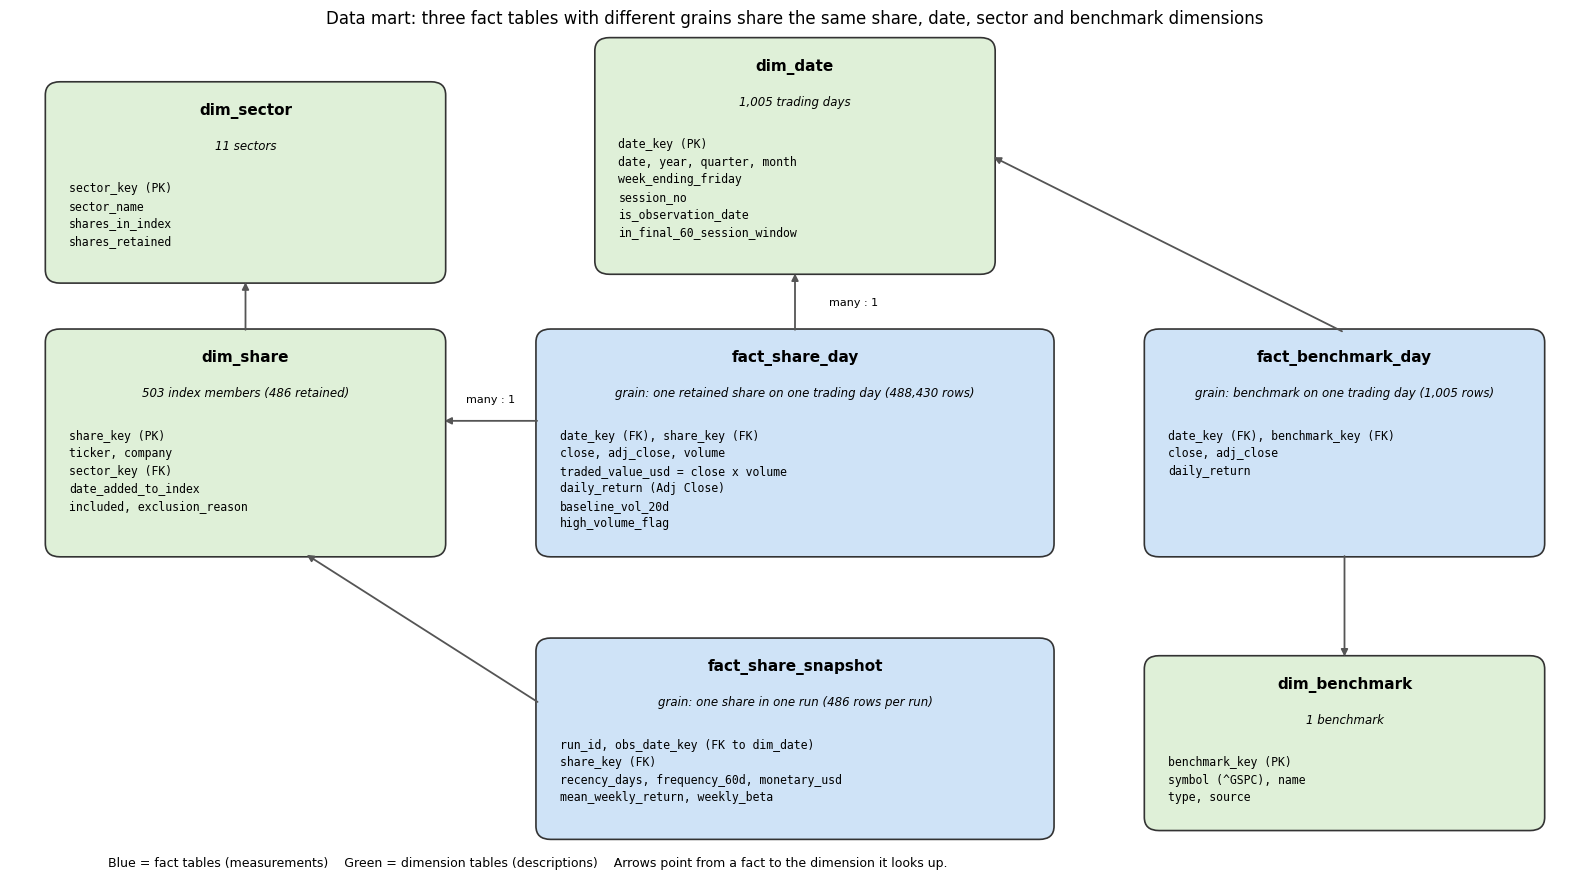

PASSED: diagram counts match the real tables


True

In [ ]:
# TASK 3.1.1 | Part E: star-schema diagram of the data mart
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xlim(0, 160); ax.set_ylim(0, 96); ax.axis("off")

def box(x, y, w, h, title, grain, fields, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.5", fc=color, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y + h - 2, title, ha="center", va="top", fontsize=11, fontweight="bold")
    ax.text(x + w / 2, y + h - 6.2, grain, ha="center", va="top", fontsize=8.5, style="italic")
    ax.text(x + 2, y + h - 11, "\n".join(fields), ha="left", va="top", fontsize=8.3, linespacing=1.45, family="monospace")

def link(p, q):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.3))

FACT, DIM = "#cfe3f7", "#dff0d8"
box(60, 69, 40, 26, "dim_date", f"{len(dim_date):,} trading days", ["date_key (PK)", "date, year, quarter, month", "week_ending_friday", "session_no", "is_observation_date", "in_final_60_session_window"], DIM)
box(4, 68, 40, 22, "dim_sector", f"{len(dim_sector)} sectors", ["sector_key (PK)", "sector_name", "shares_in_index", "shares_retained"], DIM)
box(4, 37, 40, 25, "dim_share", f"{len(dim_share)} index members ({int(dim_share['included'].sum())} retained)", ["share_key (PK)", "ticker, company", "sector_key (FK)", "date_added_to_index", "included, exclusion_reason"], DIM)
box(54, 37, 52, 25, "fact_share_day", f"grain: one retained share on one trading day ({len(fact_share_day):,} rows)", ["date_key (FK), share_key (FK)", "close, adj_close, volume", "traded_value_usd = close x volume", "daily_return (Adj Close)", "baseline_vol_20d", "high_volume_flag"], FACT)
box(116, 37, 40, 25, "fact_benchmark_day", f"grain: benchmark on one trading day ({len(fact_benchmark_day):,} rows)", ["date_key (FK), benchmark_key (FK)", "close, adj_close", "daily_return"], FACT)
box(116, 6, 40, 19, "dim_benchmark", f"{len(dim_benchmark)} benchmark", ["benchmark_key (PK)", "symbol (^GSPC), name", "type, source"], DIM)
box(54, 5, 52, 22, "fact_share_snapshot", f"grain: one share in one run ({len(fact_share_snapshot)} rows per run)", ["run_id, obs_date_key (FK to dim_date)", "share_key (FK)", "recency_days, frequency_60d, monetary_usd", "mean_weekly_return, weekly_beta"], FACT)

link((54, 52), (44, 52))       # fact_share_day -> dim_share
link((24, 62), (24, 68))       # dim_share -> dim_sector
link((80, 62), (80, 69))       # fact_share_day -> dim_date
link((136, 62), (100, 82))     # fact_benchmark_day -> dim_date
link((136, 37), (136, 25))     # fact_benchmark_day -> dim_benchmark
link((54, 20), (30, 37))       # fact_share_snapshot -> dim_share
ax.text(49, 54, "many : 1", fontsize=8, ha="center"); ax.text(86, 65, "many : 1", fontsize=8, ha="center")
ax.text(10, 1.5, "Blue = fact tables (measurements)    Green = dimension tables (descriptions)    Arrows point from a fact to the dimension it looks up.", fontsize=9)
ax.set_title("Data mart: three fact tables with different grains share the same share, date, sector and benchmark dimensions", fontsize=12)
save_fig("fig28_task31_star_schema")
plt.show()

check("diagram counts match the real tables", (len(dim_share), len(dim_sector), len(dim_date), len(fact_share_day), len(fact_benchmark_day), len(fact_share_snapshot)) == (503, 11, 1005, 488430, 1005, 486))

In [ ]:
# TASK 3.1.2 | Part A: run parameter table - sources, windows, observation date and calculation settings kept with the run
import sys, sklearn, scipy
SEED, N_INIT, MIN_SHARE = 42, 50, 0.05      # same values as Task 2 (re-stated so this cell can be re-run on its own)
params = [
    ("source", "ticker list", info["ticker_source"]),
    ("source", "price data", info["price_source"]),
    ("source", "retrieved (UTC)", info["retrieved_utc"]),
    ("source", "study period", f"{info['study_start']} to before {info['study_end_exclusive']}"),
    ("source", "benchmark", info["benchmark"]),
    ("window", "observation date", str(OBS_DATE.date())),
    ("window", "RFM window", f"{WIN[0].date()} to {WIN[-1].date()} ({len(WIN)} trading sessions)"),
    ("window", "weekly features", f"{len(weekly_ret)} complete Friday-ending weeks, {weekly_ret.index[0].date()} to {weekly_ret.index[-1].date()}"),
    ("window", "high-volume event", "volume above 2.0 x the mean of the preceding 20 sessions"),
    ("calculation", "shares retained", "strict common history: 486 of 503 shares"),
    ("calculation", "returns", "Adj Close; weekly return = Friday-to-Friday; beta = cov(share, benchmark) / var(benchmark)"),
    ("calculation", "Recency / Frequency / Monetary", "days since last event / events in the 60-session window / sum of Close x Volume in the window"),
    ("clustering", "Matrix 1", ", ".join(M1_COLS) + " (standardised)"),
    ("clustering", "Matrix 2", ", ".join(M2_COLS) + " (standardised separately; Monetary as log1p)"),
    ("clustering", "algorithms", f"Ward linkage; K-means with n_init={N_INIT}, random_state={SEED}"),
    ("clustering", "choice of k", f"highest silhouette (formal); best silhouette with k>=3 and no cluster under {MIN_SHARE:.0%} (extra)"),
    ("environment", "snapshot packages", ", ".join(f"{k} {v}" for k, v in info["package_versions"].items())),
    ("environment", "this runtime", f"python {sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}, scipy {scipy.__version__}"),
]
run_parameters = pd.DataFrame(params, columns=["group", "parameter", "value"])
run_parameters.insert(0, "run_id", RUN_ID)

check("run id matches the run id used in the snapshot fact", (fact_share_snapshot["run_id"] == RUN_ID).all())
check("the window is the last 60 sessions and ends on the observation date", len(WIN) == 60 and WIN[-1] == OBS_DATE and WIN[0] == trading_days[-60])
check("window dates in the table match dim_date", set(dim_date.loc[dim_date["in_final_60_session_window"], "date"]) == set(WIN))
check("benchmark in the table equals the benchmark used in the mart", info["benchmark"] == BENCH == dim_benchmark.at[0, "symbol"])
check("weekly feature count equals the weeks used in Task 1.2", len(weekly_ret) == 207)
check("every parameter has a non-empty value", run_parameters["value"].astype(str).str.len().gt(0).all())
check("the runtime uses the same pandas and numpy as the snapshot", pd.__version__ == info["package_versions"]["pandas"] and np.__version__ == info["package_versions"]["numpy"], hard=False)

run_parameters.to_csv(f"{MART_DIR}/run_parameters.csv", index=False)
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    print(run_parameters.drop(columns="run_id").to_string(index=False))
print("\nsaved:", f"{MART_DIR}/run_parameters.csv")

PASSED: run id matches the run id used in the snapshot fact
PASSED: the window is the last 60 sessions and ends on the observation date
PASSED: window dates in the table match dim_date
PASSED: benchmark in the table equals the benchmark used in the mart
PASSED: weekly feature count equals the weeks used in Task 1.2
PASSED: every parameter has a non-empty value
PASSED: the runtime uses the same pandas and numpy as the snapshot
      group                      parameter                                                                                         value
     source                    ticker list                                     https://en.wikipedia.org/wiki/List_of_S%26P_500_companies
     source                     price data                                      yfinance 0.2.66 (auto_adjust=False, actions=True, daily)
     source                retrieved (UTC)                                                                          2026-11-19 10:27 UTC
     source           

In [ ]:
# TASK 3.1.2 | Part B: source file lineage - every file the run used or produced, with its fingerprint (md5), size and stage
import hashlib, glob
def md5_8(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()[:8]          # same short fingerprint as the snapshot manifest

stages = [("1 source download", [f"raw_{k}.csv" for k in info["md5"]] + ["sp500_constituents.csv", "snapshot_info.json"]),
          ("2 Task 1 derived", ["weekly_returns.csv", "high_volume_flags.csv", "inclusion_exclusion_log.csv", "feature_table.csv"]),
          ("3 Task 2 clusters", sorted(os.path.basename(p) for p in glob.glob(f"{DATA_DIR}/*_clusters.csv"))),
          ("4 Task 3 mart", sorted(os.path.relpath(p, DATA_DIR) for p in glob.glob(f"{MART_DIR}/*")))]
rows = []
for stage, files in stages:
    for fn in files:
        p = f"{DATA_DIR}/{fn}"
        exists = os.path.exists(p)
        n_rows = n_cols = None
        if exists and fn.endswith((".csv", ".csv.gz")):
            d = pd.read_csv(p)
            n_rows, n_cols = d.shape
        key = fn[4:-4] if fn.startswith("raw_") else None
        rows.append({"stage": stage, "file": fn, "exists": exists, "rows": n_rows, "cols": n_cols,
                     "md5_now": md5_8(p) if exists else None, "md5_recorded": info["md5"].get(key) if key else None})
lineage = pd.DataFrame(rows)
lineage[["rows", "cols"]] = lineage[["rows", "cols"]].astype("Int64")
lineage["matches_manifest"] = np.where(lineage["md5_recorded"].isna(), "-", np.where(lineage["md5_now"] == lineage["md5_recorded"], "yes", "NO"))
lineage.insert(0, "run_id", RUN_ID)

raw = lineage[lineage["md5_recorded"].notna()]
check(f"all {len(info['md5'])} raw price files listed in the snapshot manifest exist", len(raw) == len(info["md5"]) and raw["exists"].all())
check("every raw price file matches the md5 fingerprint recorded at download", (raw["matches_manifest"] == "yes").all())
check("every file in the lineage exists", lineage["exists"].all())
check("no file is listed twice", lineage["file"].is_unique)
shapes = lineage.set_index("file").loc[["raw_close.csv", "raw_adj_close.csv", "raw_volume.csv"], ["rows", "cols"]]
check("Close, Adj Close and Volume have the same shape (1005 trading days; date column + 503 shares + benchmark = 505 columns)", (shapes == shapes.iloc[0]).all().all() and tuple(shapes.iloc[0]) == (1005, 505))
mart_rows = lineage.set_index("file")["rows"]
check("mart tables have the expected row counts", mart_rows["mart/fact_share_day.csv.gz"] == 488430 and mart_rows["mart/fact_benchmark_day.csv"] == 1005 and mart_rows["mart/fact_share_snapshot.csv"] == 486 and mart_rows["mart/dim_share.csv"] == 503)

lineage.to_csv(f"{MART_DIR}/lineage_files.csv", index=False)
with pd.option_context("display.width", 250, "display.max_rows", 100):
    print(lineage.drop(columns=["run_id", "exists"]).to_string(index=False))
print(f"\n{len(lineage)} files recorded | saved: {MART_DIR}/lineage_files.csv")

PASSED: all 8 raw price files listed in the snapshot manifest exist
PASSED: every raw price file matches the md5 fingerprint recorded at download
PASSED: every file in the lineage exists
PASSED: no file is listed twice
PASSED: Close, Adj Close and Volume have the same shape (1005 trading days; date column + 503 shares + benchmark = 505 columns)
PASSED: mart tables have the expected row counts
            stage                                  file   rows  cols  md5_now md5_recorded matches_manifest
1 source download                          raw_open.csv   1005   505 c4cea66a     c4cea66a              yes
1 source download                          raw_high.csv   1005   505 d961d1db     d961d1db              yes
1 source download                           raw_low.csv   1005   505 5d6efe75     5d6efe75              yes
1 source download                         raw_close.csv   1005   505 240665b9     240665b9              yes
1 source download                     raw_adj_close.csv   1005  

In [ ]:
# TASK 3.1.2 | Part C: cluster assignments retained for every Task 2 solution, tied to the run id
from sklearn.metrics import silhouette_score
solutions = []      # (algorithm, matrix label, features, k, role, assignment, standardised matrix, silhouette reported in Task 2)
for algo, store, kf, ke, scores in [("Ward", ward_final, ward_k, ward_k3, ward_scores), ("K-means", km_final, km_k, km_k3, km_scores)]:
    for (n, k), g in sorted(store.items()):
        solutions.append((algo, n, M1_COLS if n == "M1" else M2_COLS, k, "formal (best silhouette)" if k == kf[n] else "extra (k>=3, no cluster under 5%)",
                          g, Z1 if n == "M1" else Z2, scores[n].at[k, "silhouette"]))
rf_sil = rf_cmp.set_index("k")["silhouette_reduced"] if "k" in rf_cmp.columns else rf_cmp["silhouette_reduced"]
for k, g in sorted(rf_final.items()):
    solutions.append(("Ward without Monetary", "M2 without Monetary", RF_COLS, k, "sensitivity", g, Z_rf, rf_sil[k]))

share_key_of = dim_share.set_index("ticker")["share_key"]
sol_rows, assign = [], []
for key, (algo, n, cols, k, role, g, Z, sil_reported) in enumerate(solutions, start=1):
    sizes = g.value_counts().sort_index()
    sol_rows.append({"run_id": RUN_ID, "solution_key": key, "algorithm": algo, "matrix": n, "features": ", ".join(cols), "k": k, "role": role,
                     "silhouette": silhouette_score(Z.loc[g.index], g), "reported_silhouette": sil_reported,
                     "cluster_sizes": "/".join(map(str, sizes.tolist())), "smallest_cluster_pct": 100 * sizes.min() / len(g)})
    assign.append(pd.DataFrame({"run_id": RUN_ID, "solution_key": key, "share_key": g.index.map(share_key_of), "cluster": g.to_numpy()}))
dim_cluster_solution = pd.DataFrame(sol_rows)
fact_cluster_assignment = pd.concat(assign, ignore_index=True)

check("10 solutions are retained: 4 Ward, 4 K-means and 2 Ward without Monetary", len(dim_cluster_solution) == 10 and dim_cluster_solution["algorithm"].value_counts().to_dict() == {"Ward": 4, "K-means": 4, "Ward without Monetary": 2})
check("grain: one row per (solution, share) and nothing missing", not fact_cluster_assignment.duplicated(["solution_key", "share_key"]).any() and fact_cluster_assignment["share_key"].notna().all()
      and (fact_cluster_assignment.groupby("solution_key").size() == len(included)).all())
check("every assignment points to a retained share in dim_share", set(fact_cluster_assignment["share_key"]) == set(dim_share.loc[dim_share["included"], "share_key"]))
check("each solution has exactly k clusters numbered 1 to k", all(sorted(g["cluster"].unique()) == list(range(1, r.k + 1)) for (_, g), r in zip(fact_cluster_assignment.groupby("solution_key"), dim_cluster_solution.itertuples())))
check("cluster 1 is the largest in every solution (labels ordered by size, as in Task 2)", all((g["cluster"].value_counts().sort_index().diff().dropna() <= 0).all() for _, g in fact_cluster_assignment.groupby("solution_key")))
check("silhouette recomputed from the retained assignments equals the Task 2 value", np.allclose(dim_cluster_solution["silhouette"], dim_cluster_solution["reported_silhouette"]))
file_name = {"Ward": "ward_{n}_k{k}", "K-means": "kmeans_{n}_k{k}", "Ward without Monetary": "ward_without_monetary_k{k}"}
tick_of = dim_share.set_index("share_key")["ticker"]
same = []
for r in dim_cluster_solution.itertuples():
    saved = pd.read_csv(f"{DATA_DIR}/{file_name[r.algorithm].format(n=r.matrix, k=r.k)}_clusters.csv", index_col=0)["cluster"]
    sub = fact_cluster_assignment[fact_cluster_assignment["solution_key"] == r.solution_key]
    got = sub.set_index(sub["share_key"].map(tick_of))["cluster"]
    same.append(got.loc[saved.index].equals(saved))
check("the retained assignments equal the saved Task 2 cluster files for all 10 solutions", all(same))

dim_cluster_solution.drop(columns="reported_silhouette").to_csv(f"{MART_DIR}/dim_cluster_solution.csv", index=False)
fact_cluster_assignment.to_csv(f"{MART_DIR}/fact_cluster_assignment.csv", index=False)
print(f"\nfact_cluster_assignment: {len(fact_cluster_assignment):,} rows (10 solutions x {len(included)} shares) | run {RUN_ID}")
print(dim_cluster_solution.drop(columns=["run_id", "reported_silhouette"]).round(3).to_string(index=False))

PASSED: 10 solutions are retained: 4 Ward, 4 K-means and 2 Ward without Monetary
PASSED: grain: one row per (solution, share) and nothing missing
PASSED: every assignment points to a retained share in dim_share
PASSED: each solution has exactly k clusters numbered 1 to k
PASSED: cluster 1 is the largest in every solution (labels ordered by size, as in Task 2)
PASSED: silhouette recomputed from the retained assignments equals the Task 2 value
PASSED: the retained assignments equal the saved Task 2 cluster files for all 10 solutions

fact_cluster_assignment: 4,860 rows (10 solutions x 486 shares) | run RFM_2024-12-31_v1
 solution_key             algorithm              matrix                                    features  k                              role  silhouette     cluster_sizes  smallest_cluster_pct
            1                  Ward                  M1             mean_weekly_return, weekly_beta  2          formal (best silhouette)       0.339            394/92                18.

In [ ]:
# TASK 3.1.2 | Part D: reproducibility proof - rebuild every cluster solution from the stored mart and compare with the stored assignments
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, fcluster

snap = fact_share_snapshot.assign(ticker=fact_share_snapshot["share_key"].map(dim_share.set_index("share_key")["ticker"])).set_index("ticker")
snap["log1p_monetary"] = np.log1p(snap["monetary_usd"])
std = lambda cols: StandardScaler().fit_transform(snap[cols])                     # each matrix is standardised on its own
mats = {"M1": std(["mean_weekly_return", "weekly_beta"]), "M2": std(["recency_days", "frequency_60d", "log1p_monetary"]),
        "M2 without Monetary": std(["recency_days", "frequency_60d"])}
order = snap["share_key"].to_numpy()

def rerun(r, seed=SEED):
    Z = mats[r.matrix]
    if r.algorithm == "K-means":
        return KMeans(n_clusters=r.k, n_init=N_INIT, random_state=seed).fit_predict(Z)
    return fcluster(linkage(Z, method="ward"), r.k, "maxclust")

rows = []
for r in dim_cluster_solution.itertuples():
    stored = fact_cluster_assignment[fact_cluster_assignment["solution_key"] == r.solution_key].set_index("share_key")["cluster"].loc[order].to_numpy()
    again = rerun(r)
    other = rerun(r, seed=7) if r.algorithm == "K-means" else None                  # Ward has no random element
    rows.append({"solution_key": r.solution_key, "algorithm": r.algorithm, "matrix": r.matrix, "k": r.k,
                 "ARI_rerun_vs_stored": adjusted_rand_score(stored, again),
                 "same_sizes": sorted(np.unique(again, return_counts=True)[1]) == sorted(np.unique(stored, return_counts=True)[1]),
                 "ARI_other_seed_vs_stored": None if other is None else adjusted_rand_score(stored, other)})
repro = pd.DataFrame(rows)

check("the stored mart reproduces Matrix 1, Matrix 2 and the reduced matrix with the right shape", mats["M1"].shape == (486, 2) and mats["M2"].shape == (486, 3) and mats["M2 without Monetary"].shape == (486, 2))
check("the rebuilt rows follow the same share order as the stored assignments", set(order) == set(fact_cluster_assignment["share_key"]) and len(order) == 486)
check("all 10 solutions are reproduced exactly from the mart (ARI = 1 against the stored assignments)", (repro["ARI_rerun_vs_stored"] == 1.0).all())
check("the reproduced clusters have the same sizes", repro["same_sizes"].all())

repro.to_csv(f"{MART_DIR}/reproducibility_check.csv", index=False)
print("\nRe-running all 10 solutions from the stored mart (same settings and seed):")
print(repro.round(3).to_string(index=False))
print("\nK-means rerun with a different seed (7) instead of 42 - how much does the seed matter:")
print(repro.dropna(subset=["ARI_other_seed_vs_stored"])[["matrix", "k", "ARI_other_seed_vs_stored"]].round(3).to_string(index=False))

PASSED: the stored mart reproduces Matrix 1, Matrix 2 and the reduced matrix with the right shape
PASSED: the rebuilt rows follow the same share order as the stored assignments
PASSED: all 10 solutions are reproduced exactly from the mart (ARI = 1 against the stored assignments)
PASSED: the reproduced clusters have the same sizes

Re-running all 10 solutions from the stored mart (same settings and seed):
 solution_key             algorithm              matrix  k  ARI_rerun_vs_stored  same_sizes  ARI_other_seed_vs_stored
            1                  Ward                  M1  2                  1.0        True                       NaN
            2                  Ward                  M1  5                  1.0        True                       NaN
            3                  Ward                  M2  2                  1.0        True                       NaN
            4                  Ward                  M2  3                  1.0        True                       NaN
  

In [ ]:
# TASK 3.1.2 | Part E: version register - the baseline and every variant of the calculation, each with what changed and where its output is kept
import hashlib
md5_short = lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()[:8]
exp_c = pd.read_csv(f"{DATA_DIR}/experiment_c_observation_date_sensitivity.csv")
drift_file = pd.read_csv(f"{DATA_DIR}/cluster_drift_ward_matrix2.csv")
rf_file = pd.read_csv(f"{DATA_DIR}/ward_without_monetary_comparison.csv")
recency_changed = int((feature_table["recency_idio_days"] != feature_table["recency_days"]).sum())

versions = [
    ("v1", RUN_ID, "baseline", "As the brief: Adj Close returns, Close x Volume traded value, event = volume above 2x the preceding 20-session mean, observation date 2024-12-31",
     str(OBS_DATE.date()), "feature_table.csv", len(feature_table)),
    ("v1-A", f"{RUN_ID}-A", "experiment", "Weekly returns from Close (price return) instead of Adj Close; compared in Task 1 Experiment A and Task 3.2.3 Part B",
     str(OBS_DATE.date()), "figures/fig08_experiment_a_price_basis.png (figure only)", None),
    ("v1-B", f"{RUN_ID}-B", "experiment", f"Recency and Frequency recomputed ignoring the market-wide days (more than 30% of shares flagged); {recency_changed} of 486 shares get a different Recency",
     str(OBS_DATE.date()), "feature_table.csv, columns recency_idio_days and frequency_idio_60d", len(feature_table)),
    ("v1-C", f"{RUN_ID}-C", "experiment", "Observation date moved to earlier month-ends to see how Recency, Frequency and Monetary change",
     f"{exp_c['observation_date'].iloc[0]} to {exp_c['observation_date'].iloc[-1]}", "experiment_c_observation_date_sensitivity.csv", len(exp_c)),
    ("v1-RF", f"{RUN_ID}-RF", "experiment", "Ward clustering on Recency and Frequency only (Monetary removed), k = 2 to 8; the cluster lists for k = 2 and 3 are kept",
     str(OBS_DATE.date()), "ward_without_monetary_comparison.csv; ward_without_monetary_k2_clusters.csv; ward_without_monetary_k3_clusters.csv", len(rf_file)),
    ("v1-D", f"{RUN_ID}-D", "experiment", "Matrix 2 Ward clusters rebuilt at 13 earlier month-ends (k = 2 and 3) and compared with the December 2024 clusters",
     f"{drift_file['date'].min()} to {drift_file['date'].max()}", "cluster_drift_ward_matrix2.csv", len(drift_file)),
]
version_register = pd.DataFrame(versions, columns=["version_id", "run_id", "kind", "what_changed", "observation_date(s)", "output", "rows_in_output"])
first_file = lambda s: s.split(";")[0].split(",")[0].split(" (")[0].strip()
version_register["rows_in_output"] = version_register["rows_in_output"].astype("Int64")
version_register["md5"] = [md5_short(f"{DATA_DIR}/{first_file(o)}") if first_file(o).endswith(".csv") else "-" for o in version_register["output"]]

check("every version has its own unique run id and the baseline carries the run id used in the mart", version_register["run_id"].is_unique and version_register.at[0, "run_id"] == RUN_ID == fact_share_snapshot["run_id"].iloc[0])
check("each table named in the register exists and is not empty", all(os.path.exists(f"{DATA_DIR}/{first_file(o)}") and r > 0 for o, r in zip(version_register["output"], version_register["rows_in_output"]) if first_file(o).endswith(".csv")))
check("the Task 2.5 cluster lists named in the register exist", all(os.path.exists(f"{DATA_DIR}/ward_without_monetary_k{k}_clusters.csv") for k in (2, 3)))
check("Experiment B's columns exist and really differ from the baseline", {"recency_idio_days", "frequency_idio_60d"} <= set(feature_table.columns) and recency_changed > 0)
check("Experiment C ends at the baseline observation date and has the 4 dates shown in Task 1", len(exp_c) == 4 and pd.Timestamp(exp_c["observation_date"].iloc[-1]) == OBS_DATE)
check("Experiment D covers k = 2 and 3 at 13 dates, ending at the baseline date where it agrees with itself (ARI = 1)",
      len(drift_file) == 26 and drift_file["k"].nunique() == 2 and pd.Timestamp(drift_file["date"].max()) == OBS_DATE and np.allclose(drift_file.loc[drift_file["date"] == drift_file["date"].max(), "ARI_vs_Dec2024"], 1.0))
sil = dim_cluster_solution.set_index(["algorithm", "matrix", "k"])["silhouette"]
rf_ = rf_file.set_index("k")
check("the Monetary-removal file covers k = 2 to 8 and its silhouettes equal the ones stored with the cluster solutions (k = 2 and 3, with and without Monetary)",
      rf_file["k"].tolist() == list(range(2, 9)) and np.isclose(rf_.at[2, "silhouette_full"], sil[("Ward", "M2", 2)]) and np.isclose(rf_.at[3, "silhouette_full"], sil[("Ward", "M2", 3)])
      and np.isclose(rf_.at[2, "silhouette_reduced"], sil[("Ward without Monetary", "M2 without Monetary", 2)]) and np.isclose(rf_.at[3, "silhouette_reduced"], sil[("Ward without Monetary", "M2 without Monetary", 3)]))
check("Experiment A's figure exists in the figures folder", os.path.exists("figures/fig08_experiment_a_price_basis.png"), hard=False)

version_register.to_csv(f"{MART_DIR}/version_register.csv", index=False)
with pd.option_context("display.max_colwidth", 95, "display.width", 250):
    print(version_register[["version_id", "run_id", "kind", "observation_date(s)", "rows_in_output", "md5"]].to_string(index=False))
    print(); print(version_register[["version_id", "what_changed", "output"]].to_string(index=False))
print("\nsaved:", f"{MART_DIR}/version_register.csv")

PASSED: every version has its own unique run id and the baseline carries the run id used in the mart
PASSED: each table named in the register exists and is not empty
PASSED: the Task 2.5 cluster lists named in the register exist
PASSED: Experiment B's columns exist and really differ from the baseline
PASSED: Experiment C ends at the baseline observation date and has the 4 dates shown in Task 1
PASSED: Experiment D covers k = 2 and 3 at 13 dates, ending at the baseline date where it agrees with itself (ARI = 1)
PASSED: the Monetary-removal file covers k = 2 to 8 and its silhouettes equal the ones stored with the cluster solutions (k = 2 and 3, with and without Monetary)
PASSED: Experiment A's figure exists in the figures folder
version_id               run_id       kind      observation_date(s)  rows_in_output      md5
        v1    RFM_2024-12-31_v1   baseline               2024-12-31             486 b5556f8e
      v1-A  RFM_2024-12-31_v1-A experiment               2024-12-31          

In [ ]:
# TASK 3.1.3 | Part A: stakeholder questions 1 and 2 (market activity monitor, sector activity) answered from the saved mart files only
m_fact = pd.read_csv(f"{MART_DIR}/fact_share_day.csv.gz")
m_date = pd.read_csv(f"{MART_DIR}/dim_date.csv", parse_dates=["date"])
m_share = pd.read_csv(f"{MART_DIR}/dim_share.csv")
m_sector = pd.read_csv(f"{MART_DIR}/dim_sector.csv")

# Question 1 (market monitoring): on which days did unusually many shares trade on unusually high volume?
daily = m_fact.merge(m_date[["date_key", "date", "session_no"]], on="date_key").query("session_no > 20")        # first 20 sessions have no baseline yet
activity = daily.groupby("date")["high_volume_flag"].agg(shares_flagged="sum", share_of_shares="mean")
top_days = activity.sort_values("share_of_shares", ascending=False).head(5)

# Question 2 (sector view): in the RFM window, how often did shares in each sector have a high-volume day?
win_f = m_fact.merge(m_date.loc[m_date["in_final_60_session_window"], ["date_key"]], on="date_key")
sec = (win_f.merge(m_share[["share_key", "sector_key"]], on="share_key").merge(m_sector, on="sector_key")
       .groupby("sector_name").agg(events=("high_volume_flag", "sum"), shares=("share_key", "nunique")))
sec["events_per_share"] = sec["events"] / sec["shares"]
sec = sec.sort_values("events_per_share", ascending=False)

check("activity monitor equals the share of flagged shares per day in the Task 1.4 flags", np.allclose(activity["share_of_shares"].to_numpy(), flags.mean(axis=1).loc[activity.index].to_numpy()))
check("activity monitor covers every trading day after the first 20 sessions", len(activity) == len(trading_days) - 20)
check("sector event counts add up to the Frequency column of the feature table", sec["events"].sum() == feature_table["frequency_60d"].sum())
check("sector share counts equal the retained shares per sector in dim_sector", (sec["shares"].sort_index().to_numpy() == m_sector.set_index("sector_name")["shares_retained"].sort_index().to_numpy()).all())
by_sector_ft = feature_table.groupby("sector")["frequency_60d"].sum()
check("each sector's event count equals the feature table's Frequency summed by sector", (sec["events"].sort_index() == by_sector_ft.sort_index()).all())

print("Q1: five days with the largest share of shares on high volume (whole market)")
print((top_days.assign(share_of_shares=lambda d: (100 * d["share_of_shares"]).round(1))).to_string())
print(f"\nMedian day: {100 * activity['share_of_shares'].median():.1f}% of shares flagged | highest day: {100 * activity['share_of_shares'].max():.1f}%")
print("\nQ2: high-volume days per share by sector, RFM window")
print(sec.round(2).to_string())

PASSED: activity monitor equals the share of flagged shares per day in the Task 1.4 flags
PASSED: activity monitor covers every trading day after the first 20 sessions
PASSED: sector event counts add up to the Frequency column of the feature table
PASSED: sector share counts equal the retained shares per sector in dim_sector
PASSED: each sector's event count equals the feature table's Frequency summed by sector
Q1: five days with the largest share of shares on high volume (whole market)
            shares_flagged  share_of_shares
date                                       
2024-12-20             354             72.8
2023-12-15             319             65.6
2024-09-20             310             63.8
2022-12-16             283             58.2
2021-09-17             277             57.0

Median day: 2.1% of shares flagged | highest day: 72.8%

Q2: high-volume days per share by sector, RFM window
                        events  shares  events_per_share
sector_name                     

In [ ]:
# TASK 3.1.3 | Part B: stakeholder questions 3 and 4 (segment make-up by sector, sector return against the benchmark), from the saved mart files
m_assign = pd.read_csv(f"{MART_DIR}/fact_cluster_assignment.csv")
m_sol = pd.read_csv(f"{MART_DIR}/dim_cluster_solution.csv")
m_bench = pd.read_csv(f"{MART_DIR}/fact_benchmark_day.csv")

# Question 3 (portfolio analyst): which sectors do the Ward RFM segments (Matrix 2, k = 2) draw their shares from?
sol_key = int(m_sol.query("algorithm == 'Ward' and matrix == 'M2' and k == 2")["solution_key"].iloc[0])
seg = (m_assign.query("solution_key == @sol_key").merge(m_share[["share_key", "sector_key"]], on="share_key").merge(m_sector[["sector_key", "sector_name"]], on="sector_key"))
seg_mix = pd.crosstab(seg["sector_name"], seg["cluster"])
seg_mix["share_in_cluster_2_%"] = 100 * seg_mix[2] / seg_mix.sum(axis=1)
seg_mix = seg_mix.sort_values("share_in_cluster_2_%", ascending=False)

# Question 4 (risk and performance): over the RFM window, did each sector's typical share beat the benchmark? (descriptive, price return only)
win_keys = m_date.loc[m_date["in_final_60_session_window"], "date_key"]
wr = m_fact[m_fact["date_key"].isin(win_keys)].groupby("share_key")["daily_return"].apply(lambda s: (1 + s).prod() - 1)
bench_win = (1 + m_bench.loc[m_bench["date_key"].isin(win_keys), "daily_return"]).prod() - 1
perf = (wr.rename("window_return").reset_index().merge(m_share[["share_key", "sector_key"]], on="share_key").merge(m_sector[["sector_key", "sector_name"]], on="sector_key")
        .groupby("sector_name")["window_return"].median().to_frame("median_share_return"))
perf["benchmark_return"] = bench_win
perf["median_minus_benchmark"] = perf["median_share_return"] - bench_win
perf = perf.sort_values("median_minus_benchmark", ascending=False)

check("segment make-up equals a crosstab built directly from the Task 1 feature table and Task 2 clusters",
      seg_mix[[1, 2]].sort_index().equals(pd.crosstab(feature_table["sector"], ward_final[("M2", 2)]).sort_index().rename_axis("sector_name").rename_axis(columns="cluster")))
check("every one of the 486 retained shares is in exactly one segment", seg_mix[[1, 2]].to_numpy().sum() == len(included))
base_i = trading_days.get_loc(WIN[0]) - 1                                         # the close just before the window starts
manual = a_inc.loc[WIN[-1]] / a_inc.iloc[base_i] - 1
check("window returns compounded from the mart equal Adj Close at the end / before the start - 1 (all 486 shares)", np.allclose(wr.rename(index=dict(zip(m_share["share_key"], m_share["ticker"]))).loc[included].to_numpy(), manual.loc[included].to_numpy()))
bm_px = pd.read_csv(f"{DATA_DIR}/raw_adj_close.csv", index_col=0, parse_dates=True)[BENCH].reindex(trading_days)
check("benchmark window return equals the index level at the end / before the start - 1", np.isclose(bench_win, bm_px.loc[WIN[-1]] / bm_px.iloc[base_i] - 1))
check("all 11 sectors are present in both answers", len(seg_mix) == 11 and len(perf) == 11)

print(f"Q3: Ward RFM segments on Matrix 2 (k = 2, solution {sol_key}): shares per sector in each segment")
print(seg_mix.round(1).to_string())
print(f"\nQ4: median share return per sector over the RFM window against the benchmark ({100 * bench_win:.2f}%)")
print((100 * perf).round(2).to_string())

PASSED: segment make-up equals a crosstab built directly from the Task 1 feature table and Task 2 clusters
PASSED: every one of the 486 retained shares is in exactly one segment
PASSED: window returns compounded from the mart equal Adj Close at the end / before the start - 1 (all 486 shares)
PASSED: benchmark window return equals the index level at the end / before the start - 1
PASSED: all 11 sectors are present in both answers
Q3: Ward RFM segments on Matrix 2 (k = 2, solution 3): shares per sector in each segment
cluster                  1   2  share_in_cluster_2_%
sector_name                                         
Materials               15   8                  34.8
Utilities               21   9                  30.0
Information Technology  56  18                  24.3
Consumer Staples        25   7                  21.9
Communication Services  16   4                  20.0
Consumer Discretionary  38   9                  19.1
Health Care             49   9                  15.5
F

/tmp/ipykernel_1460/109386019.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


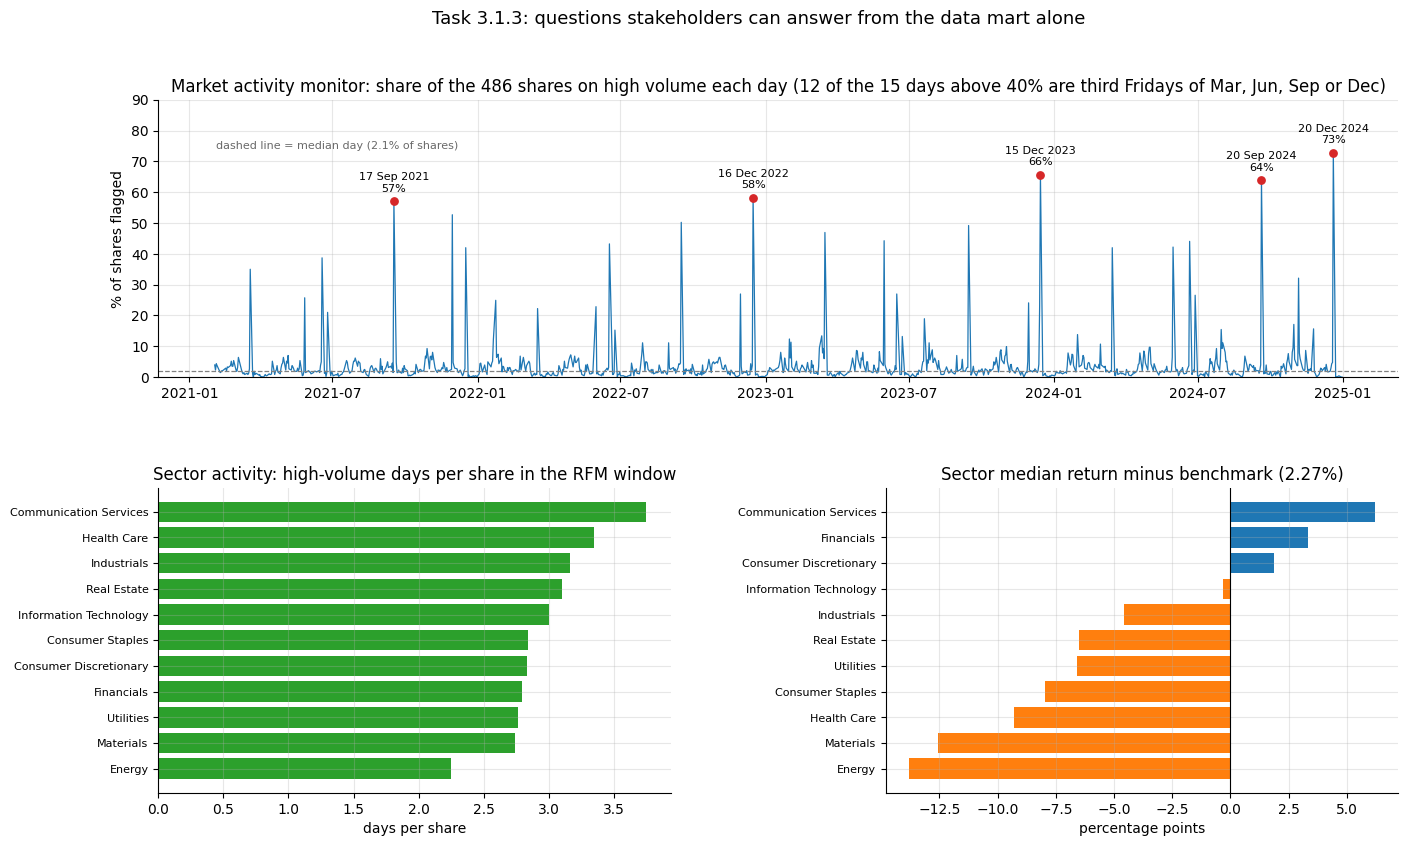

PASSED: the title's claim holds: 12 of the 15 days above 40% are third Fridays of March, June, September or December
PASSED: figure values come from the saved-mart answers (5 top days, 11 sectors in each bar chart)


True

In [ ]:
# TASK 3.1.3 | Part C: figure of the stakeholder answers (fig29) - market activity, sector activity and sector return against the benchmark
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1], hspace=0.38, wspace=0.42)

ax = fig.add_subplot(gs[0, :])
ax.plot(activity.index, 100 * activity["share_of_shares"], color="tab:blue", lw=0.9)
ax.scatter(top_days.index, 100 * top_days["share_of_shares"], color="tab:red", zorder=3, s=28)
for d, v in top_days["share_of_shares"].items():
    ax.annotate(f"{d:%d %b %Y}\n{100 * v:.0f}%", (d, 100 * v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
ax.axhline(100 * activity["share_of_shares"].median(), color="grey", ls="--", lw=0.9)
ax.text(activity.index[2], 100 * activity["share_of_shares"].median() + 72, f"dashed line = median day ({100 * activity['share_of_shares'].median():.1f}% of shares)", fontsize=8, color="dimgrey")
ax.set(title="Market activity monitor: share of the 486 shares on high volume each day (12 of the 15 days above 40% are third Fridays of Mar, Jun, Sep or Dec)", ylabel="% of shares flagged", ylim=(0, 90))

ax = fig.add_subplot(gs[1, 0])
s_ = sec["events_per_share"].sort_values()
ax.barh(s_.index, s_.values, color="tab:green")
ax.set(title="Sector activity: high-volume days per share in the RFM window", xlabel="days per share")
ax.tick_params(axis="y", labelsize=8)

ax = fig.add_subplot(gs[1, 1])
p_ = (100 * perf["median_minus_benchmark"]).sort_values()
ax.barh(p_.index, p_.values, color=np.where(p_.values >= 0, "tab:blue", "tab:orange"))
ax.axvline(0, color="black", lw=0.8)
ax.set(title=f"Sector median return minus benchmark ({100 * bench_win:.2f}%)", xlabel="percentage points")
ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Task 3.1.3: questions stakeholders can answer from the data mart alone", fontsize=13)
save_fig("fig29_task313_stakeholder_answers")
plt.show()

big = activity[activity["share_of_shares"] > 0.40]
third_friday = (big.index.dayofweek == 4) & (big.index.day >= 15) & (big.index.day <= 21) & big.index.month.isin([3, 6, 9, 12])
check("the title's claim holds: 12 of the 15 days above 40% are third Fridays of March, June, September or December", len(big) == 15 and int(third_friday.sum()) == 12)
check("figure values come from the saved-mart answers (5 top days, 11 sectors in each bar chart)", len(top_days) == 5 and len(s_) == 11 and len(p_) == 11)

In [ ]:
# TASK 3.2.1 | Part A: original-unit profiles of the Ward clusters (Matrix 1 and Matrix 2, formal and extra k)
prof_cols = {"mean_weekly_return": "weekly return %", "weekly_beta": "beta", "recency_days": "recency days",
             "frequency_60d": "frequency (events)", "monetary_usd": "monetary $bn"}
def profile_orig(labels):
    d = feature_table.loc[labels.index, list(prof_cols)].copy()
    d["mean_weekly_return"] *= 100                      # weekly return in percent
    d["monetary_usd"] /= 1e9                            # traded value in billions of US dollars
    g = d.groupby(labels.rename("cluster"))
    out = g.median().rename(columns=prof_cols)          # medians: the features are skewed (see Task 2.1)
    out.insert(0, "shares", g.size())
    out.insert(1, "% of shares", 100 * out["shares"] / len(labels))
    return out

ward_profiles = {key: profile_orig(lab) for key, lab in sorted(ward_final.items())}

for (n, k), tbl in ward_profiles.items():
    check(f"{n} k={k}: cluster sizes add up to the 486 retained shares", tbl["shares"].sum() == len(included) == len(ward_final[(n, k)]))
    check(f"{n} k={k}: sizes equal the sizes stored in the mart", "/".join(map(str, tbl["shares"].tolist())) == m_sol.query("algorithm == 'Ward' and matrix == @n and k == @k")["cluster_sizes"].iloc[0])
    check(f"{n} k={k}: no missing values in the profile", tbl.notna().all().all())
lab = ward_final[("M2", 2)]
members = lab[lab == 2].index
check("hand calculation: Matrix 2 k=2, cluster 2 median recency, frequency and monetary equal the profile",
      np.isclose(feature_table.loc[members, "recency_days"].median(), ward_profiles[("M2", 2)].at[2, "recency days"]) and
      np.isclose(feature_table.loc[members, "frequency_60d"].median(), ward_profiles[("M2", 2)].at[2, "frequency (events)"]) and
      np.isclose(feature_table.loc[members, "monetary_usd"].median() / 1e9, ward_profiles[("M2", 2)].at[2, "monetary $bn"]))
members1 = ward_final[("M1", 2)][ward_final[("M1", 2)] == 1].index
check("hand calculation: Matrix 1 k=2, cluster 1 median weekly return (in %) and beta equal the profile",
      np.isclose(100 * feature_table.loc[members1, "mean_weekly_return"].median(), ward_profiles[("M1", 2)].at[1, "weekly return %"]) and
      np.isclose(feature_table.loc[members1, "weekly_beta"].median(), ward_profiles[("M1", 2)].at[1, "beta"]))

pd.concat({f"{n} k={k}": t for (n, k), t in ward_profiles.items()}, names=["solution", "cluster"]).to_csv(f"{DATA_DIR}/ward_cluster_profiles_original_units.csv")
all_med = feature_table[list(prof_cols)].median() * pd.Series({"mean_weekly_return": 100, "weekly_beta": 1, "recency_days": 1, "frequency_60d": 1, "monetary_usd": 1e-9})
print("All 486 shares, median:", dict(zip(prof_cols.values(), all_med.round(2))), "\n")
for (n, k), tbl in ward_profiles.items():
    print(f"Ward, {'Matrix 1 (return, beta)' if n == 'M1' else 'Matrix 2 (RFM)'}, k = {k}: median of each original feature per cluster")
    print(tbl.round(2).to_string(), "\n")

PASSED: M1 k=2: cluster sizes add up to the 486 retained shares
PASSED: M1 k=2: sizes equal the sizes stored in the mart
PASSED: M1 k=2: no missing values in the profile
PASSED: M1 k=5: cluster sizes add up to the 486 retained shares
PASSED: M1 k=5: sizes equal the sizes stored in the mart
PASSED: M1 k=5: no missing values in the profile
PASSED: M2 k=2: cluster sizes add up to the 486 retained shares
PASSED: M2 k=2: sizes equal the sizes stored in the mart
PASSED: M2 k=2: no missing values in the profile
PASSED: M2 k=3: cluster sizes add up to the 486 retained shares
PASSED: M2 k=3: sizes equal the sizes stored in the mart
PASSED: M2 k=3: no missing values in the profile
PASSED: hand calculation: Matrix 2 k=2, cluster 2 median recency, frequency and monetary equal the profile
PASSED: hand calculation: Matrix 1 k=2, cluster 1 median weekly return (in %) and beta equal the profile
All 486 shares, median: {'weekly return %': 0.26, 'beta': 0.95, 'recency days': 11.0, 'frequency (events)': 

In [ ]:
# TASK 3.2.1 | Part B: how much do the return-and-beta clusters (Matrix 1) overlap with the RFM clusters (Matrix 2)?
from scipy.stats import chi2_contingency
from sklearn.metrics import adjusted_rand_score
overlap = {}
for (k1, k2) in [(2, 2), (5, 3)]:
    a, b = ward_final[("M1", k1)], ward_final[("M2", k2)].loc[ward_final[("M1", k1)].index]
    ct = pd.crosstab(a.rename("Matrix 1 cluster"), b.rename("Matrix 2 cluster"))
    chi2, p, dof, expected = chi2_contingency(ct, correction=False)
    n = ct.to_numpy().sum()
    overlap[(k1, k2)] = {"table": ct, "expected": pd.DataFrame(expected, index=ct.index, columns=ct.columns), "ARI": adjusted_rand_score(a, b),
                         "chi2": chi2, "p": p, "cramers_v": np.sqrt(chi2 / (n * (min(ct.shape) - 1)))}

    # hand calculations of the same statistics
    exp_hand = np.outer(ct.sum(axis=1), ct.sum(axis=0)) / n
    check(f"M1 k={k1} vs M2 k={k2}: the table covers all 486 shares", n == len(included))
    check(f"M1 k={k1} vs M2 k={k2}: expected counts equal row total x column total / 486", np.allclose(exp_hand, expected))
    check(f"M1 k={k1} vs M2 k={k2}: chi-square equals the sum of (observed - expected)^2 / expected", np.isclose(((ct.to_numpy() - exp_hand) ** 2 / exp_hand).sum(), chi2))
    pairs = lambda x: (x * (x - 1) / 2).sum()                                    # Adjusted Rand Index from the table, by hand
    sum_ij, sum_a, sum_b, tot = pairs(ct.to_numpy()), pairs(ct.sum(axis=1).to_numpy()), pairs(ct.sum(axis=0).to_numpy()), n * (n - 1) / 2
    check(f"M1 k={k1} vs M2 k={k2}: ARI equals the textbook pair-counting formula", np.isclose((sum_ij - sum_a * sum_b / tot) / (0.5 * (sum_a + sum_b) - sum_a * sum_b / tot), overlap[(k1, k2)]["ARI"]))

for (k1, k2), o in overlap.items():
    print(f"Matrix 1 (k={k1}) clusters against Matrix 2 (k={k2}) clusters: number of shares")
    print(o["table"].to_string())
    print("expected if the two groupings were unrelated:"); print(o["expected"].round(1).to_string())
    print(f"ARI = {o['ARI']:.3f} | chi-square = {o['chi2']:.1f}, p = {o['p']:.3f} | Cramer's V = {o['cramers_v']:.3f}\n")

PASSED: M1 k=2 vs M2 k=2: the table covers all 486 shares
PASSED: M1 k=2 vs M2 k=2: expected counts equal row total x column total / 486
PASSED: M1 k=2 vs M2 k=2: chi-square equals the sum of (observed - expected)^2 / expected
PASSED: M1 k=2 vs M2 k=2: ARI equals the textbook pair-counting formula
PASSED: M1 k=5 vs M2 k=3: the table covers all 486 shares
PASSED: M1 k=5 vs M2 k=3: expected counts equal row total x column total / 486
PASSED: M1 k=5 vs M2 k=3: chi-square equals the sum of (observed - expected)^2 / expected
PASSED: M1 k=5 vs M2 k=3: ARI equals the textbook pair-counting formula
Matrix 1 (k=2) clusters against Matrix 2 (k=2) clusters: number of shares
Matrix 2 cluster    1   2
Matrix 1 cluster         
1                 331  63
2                  73  19
expected if the two groupings were unrelated:
Matrix 2 cluster      1     2
Matrix 1 cluster             
1                 327.5  66.5
2                  76.5  15.5
ARI = 0.029 | chi-square = 1.2, p = 0.282 | Cramer's V = 0

In [ ]:
# TASK 3.2.1 | Part C: sector composition of every Ward cluster, with a permutation test of whether sector and cluster are related
from scipy.stats import chi2_contingency
sector = feature_table["sector"]
sec_code = pd.Categorical(sector).codes
N_PERM = 5000

def chi2_codes(sc, cl, n_s, n_c):
    ct = np.bincount(sc * n_c + cl, minlength=n_s * n_c).reshape(n_s, n_c)
    e = np.outer(ct.sum(1), ct.sum(0)) / ct.sum()
    return ((ct - e) ** 2 / e).sum()

def perm_p(cl, n_c, chi2):                                                      # share of 5,000 label shuffles with a chi-square at least as large
    rng = np.random.default_rng(SEED)                                          # fixed seed: the same p-value every run
    return (1 + sum(chi2_codes(sec_code, rng.permutation(cl), 11, n_c) >= chi2 for _ in range(N_PERM))) / (N_PERM + 1)

sector_mix, sector_test = {}, []
for (n, k), lab in sorted(ward_final.items()):
    lab = lab.loc[feature_table.index]
    cl = lab.to_numpy() - 1
    ct = pd.crosstab(sector, lab.rename("cluster"))
    chi2, p_asym, dof, expected = chi2_contingency(ct, correction=False)
    resid = (ct - expected) / np.sqrt(expected * (1 - ct.sum(1).to_numpy()[:, None] / 486) * (1 - ct.sum(0).to_numpy()[None, :] / 486))
    sector_mix[(n, k)] = {"counts": ct, "pct_of_cluster": 100 * ct / ct.sum(), "resid": resid}
    sector_test.append({"solution": f"{n} k={k}", "chi2": chi2, "cells_expected_below_5_%": 100 * (expected < 5).mean(), "p_asymptotic": p_asym,
                        "p_permutation": perm_p(cl, k, chi2), "cramers_v": np.sqrt(chi2 / (486 * (min(ct.shape) - 1)))})
    check(f"{n} k={k}: the table covers all 486 shares and every sector row matches dim_sector", ct.to_numpy().sum() == 486 and
          (ct.sum(axis=1).sort_index().to_numpy() == m_sector.set_index("sector_name")["shares_retained"].sort_index().to_numpy()).all())
    check(f"{n} k={k}: chi-square equals the hand calculation from the table", np.isclose(chi2, chi2_codes(sec_code, cl, 11, k)))
sector_test = pd.DataFrame(sector_test)
check("the permutation test gives the same p-value when repeated with the same seed", perm_p(ward_final[("M2", 2)].loc[feature_table.index].to_numpy() - 1, 2, sector_test.at[2, "chi2"]) == sector_test.at[2, "p_permutation"])
check("permutation and chi-square p-values agree on which solutions are related at the 5% level (so the small cells do not change the answer)",
      ((sector_test["p_permutation"] < 0.05) == (sector_test["p_asymptotic"] < 0.05)).all(), hard=False)

pd.concat({f"{n} k={k}": o["pct_of_cluster"] for (n, k), o in sector_mix.items()}, names=["solution"]).to_csv(f"{DATA_DIR}/ward_cluster_sector_composition_pct.csv")
print("Is the sector of a share related to its Ward cluster? (p-values from 5,000 random relabellings)")
print(sector_test.round(3).to_string(index=False))
for (n, k), o in sector_mix.items():
    big = o["resid"].stack()
    big = big[big.abs() >= 3].sort_values(key=abs, ascending=False)
    print(f"{n} k={k}: sectors far from chance (adjusted residual of 3 or more):", {f"{s} in cluster {c}": round(v, 1) for (s, c), v in big.items()} or "none")

PASSED: M1 k=2: the table covers all 486 shares and every sector row matches dim_sector
PASSED: M1 k=2: chi-square equals the hand calculation from the table
PASSED: M1 k=5: the table covers all 486 shares and every sector row matches dim_sector
PASSED: M1 k=5: chi-square equals the hand calculation from the table
PASSED: M2 k=2: the table covers all 486 shares and every sector row matches dim_sector
PASSED: M2 k=2: chi-square equals the hand calculation from the table
PASSED: M2 k=3: the table covers all 486 shares and every sector row matches dim_sector
PASSED: M2 k=3: chi-square equals the hand calculation from the table
PASSED: the permutation test gives the same p-value when repeated with the same seed
PASSED: permutation and chi-square p-values agree on which solutions are related at the 5% level (so the small cells do not change the answer)
Is the sector of a share related to its Ward cluster? (p-values from 5,000 random relabellings)
solution    chi2  cells_expected_below_5_%  

/tmp/ipykernel_1460/109386019.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


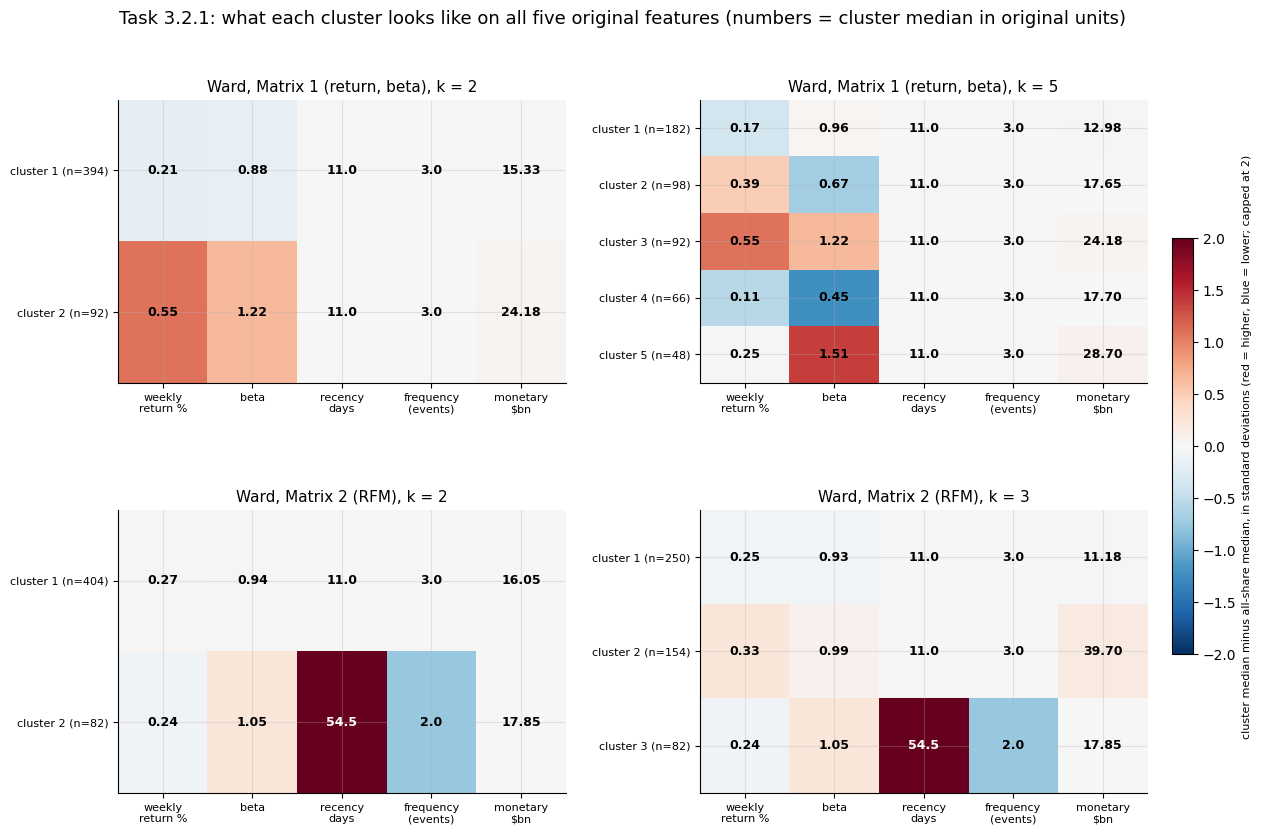

PASSED: heatmap colour for Matrix 2 k=2, cluster 2, recency equals (cluster median - all-share median) / standard deviation
PASSED: heatmaps show every cluster of the four solutions (2 + 5 + 2 + 3 = 12 rows)


True

In [ ]:
# TASK 3.2.1 | Part D: profile heatmaps of the four Ward solutions - numbers are in original units, colours show distance from the typical share
raw_scale = pd.Series({"mean_weekly_return": 100, "weekly_beta": 1, "recency_days": 1, "frequency_60d": 1, "monetary_usd": 1e-9})
overall_med = feature_table[list(prof_cols)].median() * raw_scale
overall_sd = feature_table[list(prof_cols)].std() * raw_scale
effect = {key: (tbl[list(prof_cols.values())] - overall_med.set_axis(list(prof_cols.values()))) / overall_sd.set_axis(list(prof_cols.values())) for key, tbl in ward_profiles.items()}

fig, axes = plt.subplots(2, 2, figsize=(16, 9), gridspec_kw={"hspace": 0.45, "wspace": 0.3})
for ax, ((n, k), tbl) in zip(axes.ravel(), ward_profiles.items()):
    e = effect[(n, k)]
    im = ax.imshow(e.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    for i in range(e.shape[0]):
        for j in range(e.shape[1]):
            v = tbl.iloc[i, j + 2]
            ax.text(j, i, f"{v:.2f}" if j in (0, 1, 4) else f"{v:.1f}", ha="center", va="center", fontsize=9, fontweight="bold", color="white" if abs(e.iloc[i, j]) > 1.4 else "black")
    ax.set_xticks(range(5)); ax.set_xticklabels(["weekly\nreturn %", "beta", "recency\ndays", "frequency\n(events)", "monetary\n$bn"], fontsize=8)
    ax.set_yticks(range(e.shape[0])); ax.set_yticklabels([f"cluster {c} (n={s})" for c, s in tbl["shares"].items()], fontsize=8)
    ax.set_title(f"Ward, {'Matrix 1 (return, beta)' if n == 'M1' else 'Matrix 2 (RFM)'}, k = {k}", fontsize=11)
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
cb.set_label("cluster median minus all-share median, in standard deviations (red = higher, blue = lower; capped at 2)", fontsize=8)
fig.suptitle("Task 3.2.1: what each cluster looks like on all five original features (numbers = cluster median in original units)", fontsize=13, x=0.44)
save_fig("fig30_task321_cluster_profiles")
plt.show()

ref = ward_profiles[("M2", 2)].at[2, "recency days"]
check("heatmap colour for Matrix 2 k=2, cluster 2, recency equals (cluster median - all-share median) / standard deviation",
      np.isclose(effect[("M2", 2)].at[2, "recency days"], (ref - feature_table["recency_days"].median()) / feature_table["recency_days"].std()))
check("heatmaps show every cluster of the four solutions (2 + 5 + 2 + 3 = 12 rows)", sum(len(t) for t in ward_profiles.values()) == 12)

/tmp/ipykernel_1460/109386019.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


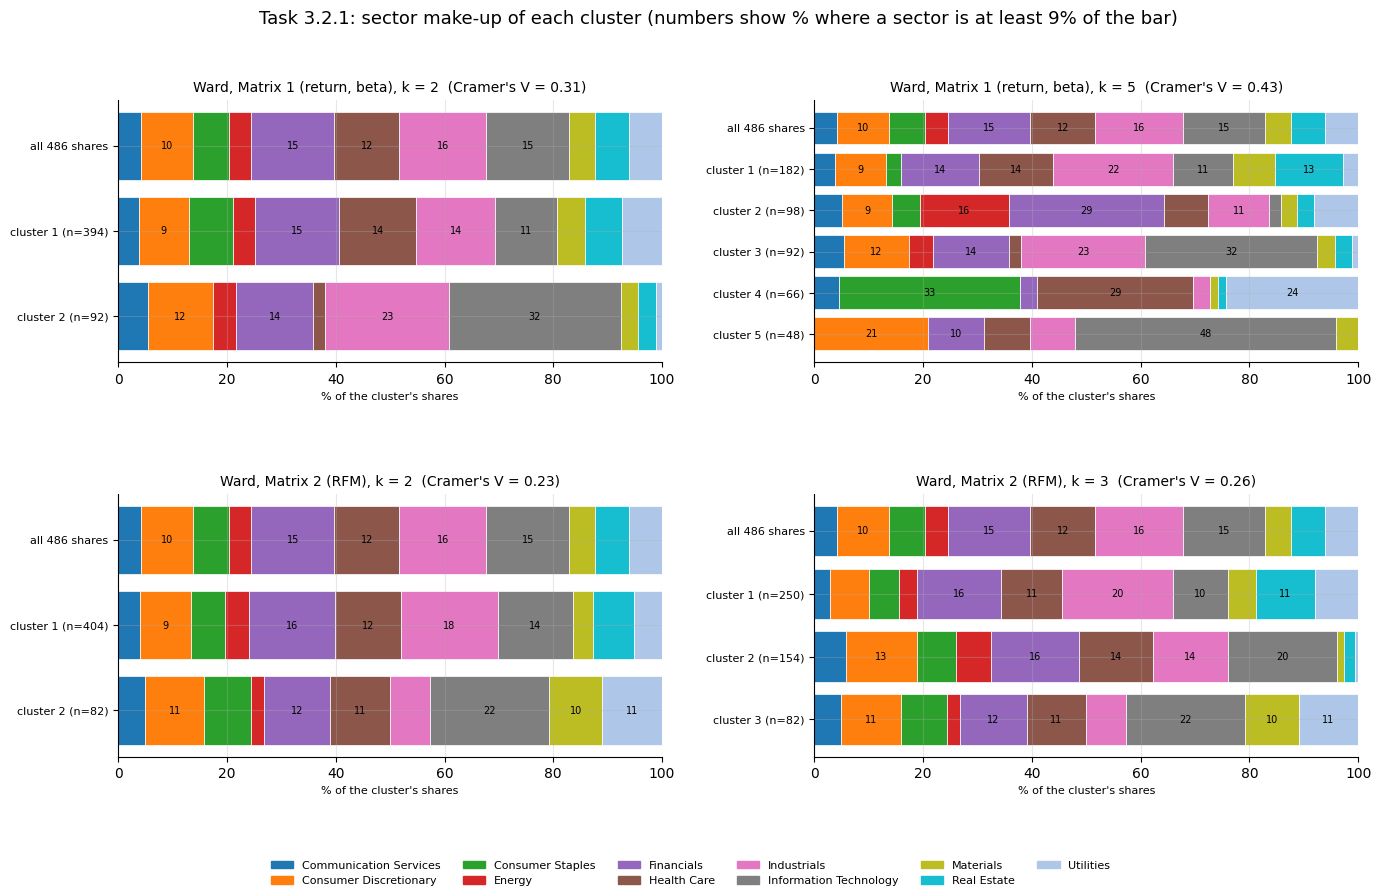

PASSED: every bar adds up to 100%
PASSED: the all-shares bar equals the sector shares of the 486 retained shares


True

In [ ]:
# TASK 3.2.1 | Part E: sector composition of the Ward clusters - each bar is one cluster, compared with all 486 shares
sectors = list(m_sector.sort_values("sector_name")["sector_name"])
colors = dict(zip(sectors, plt.cm.tab20(np.linspace(0, 1, 20))[[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1]]))
all_mix = 100 * m_sector.set_index("sector_name")["shares_retained"].reindex(sectors) / 486

fig, axes = plt.subplots(2, 2, figsize=(16, 9), gridspec_kw={"hspace": 0.5, "wspace": 0.28})
for ax, ((n, k), o) in zip(axes.ravel(), sector_mix.items()):
    pct = o["pct_of_cluster"].reindex(sectors)
    rows = [("all 486 shares", all_mix)] + [(f"cluster {c} (n={int(o['counts'][c].sum())})", pct[c]) for c in pct.columns]
    for y, (name, vals) in enumerate(rows[::-1]):
        left = 0
        for s in sectors:
            ax.barh(y, vals[s], left=left, color=colors[s], edgecolor="white", lw=0.5)
            if vals[s] >= 9:
                ax.text(left + vals[s] / 2, y, f"{vals[s]:.0f}", ha="center", va="center", fontsize=7)
            left += vals[s]
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows[::-1]], fontsize=8)
    ax.set_xlim(0, 100); ax.set_xlabel("% of the cluster's shares", fontsize=8)
    ax.set_title(f"Ward, {'Matrix 1 (return, beta)' if n == 'M1' else 'Matrix 2 (RFM)'}, k = {k}  (Cramer's V = {sector_test.set_index('solution').at[f'{n} k={k}', 'cramers_v']:.2f})", fontsize=10)
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[s]) for s in sectors]
fig.legend(handles, sectors, loc="lower center", ncol=6, fontsize=8, frameon=False)
fig.suptitle("Task 3.2.1: sector make-up of each cluster (numbers show % where a sector is at least 9% of the bar)", fontsize=13)
fig.subplots_adjust(bottom=0.15)
save_fig("fig31_task321_sector_composition")
plt.show()

check("every bar adds up to 100%", all(np.allclose(o["pct_of_cluster"].sum(), 100) for o in sector_mix.values()) and np.isclose(all_mix.sum(), 100))
check("the all-shares bar equals the sector shares of the 486 retained shares", np.allclose(all_mix.to_numpy(), 100 * feature_table["sector"].value_counts(normalize=True).reindex(sectors).to_numpy()))

In [ ]:
# TASK 3.2.2 | Part A: correlations between the five features (original units, Monetary on the log scale), with bootstrap 95% intervals
corr_cols = ["mean_weekly_return", "weekly_beta", "recency_days", "frequency_60d", "log1p_monetary"]
short = {"mean_weekly_return": "return", "weekly_beta": "beta", "recency_days": "recency", "frequency_60d": "frequency", "log1p_monetary": "log1p(monetary)",
         "recency_idio_days": "recency (market days ignored)", "frequency_idio_60d": "frequency (market days ignored)"}
N_BOOT = 2000
pearson = feature_table[corr_cols].corr()
spearman = feature_table[corr_cols].corr(method="spearman")

def boot_ci(x, y, seed=SEED):
    idx = np.random.default_rng(seed).integers(0, len(x), size=(N_BOOT, len(x)))              # 2,000 resamples of the 486 shares
    xs, ys = x[idx], y[idx]
    r = ((xs - xs.mean(1, keepdims=True)) * (ys - ys.mean(1, keepdims=True))).mean(1) / (xs.std(1) * ys.std(1))
    return np.percentile(r, [2.5, 97.5])

pairs = [("recency_days", "frequency_60d"), ("recency_days", "log1p_monetary"), ("frequency_60d", "log1p_monetary"),
         ("weekly_beta", "log1p_monetary"), ("mean_weekly_return", "log1p_monetary"), ("mean_weekly_return", "weekly_beta"),
         ("recency_idio_days", "frequency_idio_60d")]
rows = []
for a, b in pairs:
    x, y = feature_table[a].to_numpy(float), feature_table[b].to_numpy(float)
    rx, ry = feature_table[a].rank().to_numpy(), feature_table[b].rank().to_numpy()          # Spearman interval: ranks of the full sample, resampled
    p_lo, p_hi = boot_ci(x, y)
    s_lo, s_hi = boot_ci(rx, ry)
    rows.append({"pair": f"{short[a]} vs {short[b]}", "pearson": np.corrcoef(x, y)[0, 1], "pearson_95%_low": p_lo, "pearson_95%_high": p_hi,
                 "spearman": np.corrcoef(rx, ry)[0, 1], "spearman_95%_low": s_lo, "spearman_95%_high": s_hi})
ci = pd.DataFrame(rows).set_index("pair")

check("correlation matrices are symmetric with 1 on the diagonal", np.allclose(pearson, pearson.T) and np.allclose(np.diag(pearson), 1) and np.allclose(spearman, spearman.T) and np.allclose(np.diag(spearman), 1))
check("hand calculation: recency vs frequency Pearson equals the covariance formula",
      np.isclose(pearson.at["recency_days", "frequency_60d"], np.cov(feature_table["recency_days"], feature_table["frequency_60d"])[0, 1] / (feature_table["recency_days"].std() * feature_table["frequency_60d"].std())))
check("Spearman equals Pearson computed on the ranks", np.isclose(spearman.at["recency_days", "frequency_60d"], np.corrcoef(feature_table["recency_days"].rank(), feature_table["frequency_60d"].rank())[0, 1]))
check("the three clustering correlations reproduce Task 2.5 (Pearson -0.346, 0.152, 0.013)",
      np.allclose(ci.iloc[:3]["pearson"].round(3), [-0.346, 0.152, 0.013]))
check("the same three Spearman correlations reproduce Task 2.5 (-0.196, 0.137, -0.048)",
      np.allclose(ci.iloc[:3]["spearman"].round(3), [-0.196, 0.137, -0.048]))
check("every estimate lies inside its own bootstrap interval", ((ci["pearson"] >= ci["pearson_95%_low"]) & (ci["pearson"] <= ci["pearson_95%_high"]) & (ci["spearman"] >= ci["spearman_95%_low"]) & (ci["spearman"] <= ci["spearman_95%_high"])).all())
x0, y0 = feature_table["recency_days"].to_numpy(float), feature_table["frequency_60d"].to_numpy(float)
check("the bootstrap gives the same interval when repeated with the same seed", np.allclose(boot_ci(x0, y0), boot_ci(x0, y0)))

print("Pearson correlation of the five original features:"); print(pearson.rename(index=short, columns=short).round(2).to_string())
print("\nSpearman rank correlation (not driven by outliers or by the Recency spike):"); print(spearman.rename(index=short, columns=short).round(2).to_string())
print("\nKey pairs with bootstrap 95% intervals (2,000 resamples):"); print(ci.round(2).to_string())

PASSED: correlation matrices are symmetric with 1 on the diagonal
PASSED: hand calculation: recency vs frequency Pearson equals the covariance formula
PASSED: Spearman equals Pearson computed on the ranks
PASSED: the three clustering correlations reproduce Task 2.5 (Pearson -0.346, 0.152, 0.013)
PASSED: the same three Spearman correlations reproduce Task 2.5 (-0.196, 0.137, -0.048)
PASSED: every estimate lies inside its own bootstrap interval
PASSED: the bootstrap gives the same interval when repeated with the same seed
Pearson correlation of the five original features:
                 return  beta  recency  frequency  log1p(monetary)
return             1.00  0.25     0.08       0.00             0.28
beta               0.25  1.00     0.07       0.08             0.24
recency            0.08  0.07     1.00      -0.35             0.15
frequency          0.00  0.08    -0.35       1.00             0.01
log1p(monetary)    0.28  0.24     0.15       0.01             1.00

Spearman rank correl

In [ ]:
# TASK 3.2.2 | Part B: what removing Monetary changes (Ward on Recency and Frequency only, against the full Matrix 2)
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score, silhouette_score
L_full, L_rf = linkage(Z2.to_numpy(), "ward"), linkage(Z_rf.to_numpy(), "ward")
rows = []
for k in range(2, 9):
    a, b = fcluster(L_full, k, "maxclust"), fcluster(L_rf, k, "maxclust")
    rows.append({"k": k, "ARI_full_vs_without_Monetary": adjusted_rand_score(a, b), "silhouette_full": silhouette_score(Z2, a), "silhouette_without_Monetary": silhouette_score(Z_rf, b)})
rm = pd.DataFrame(rows).set_index("k")

check("the table reproduces the Task 2.5 adjusted Rand indices for k = 2 to 8", np.allclose(rm["ARI_full_vs_without_Monetary"].round(3), [0.873, 0.291, 0.203, 0.335, 0.273, 0.374, 0.432]))
check("the table reproduces the Task 2.5 silhouettes without Monetary", np.allclose(rm["silhouette_without_Monetary"].round(3), [0.524, 0.488, 0.516, 0.593, 0.686, 0.686, 0.689]))
check("the table reproduces the Task 2.5 silhouettes of the full matrix", np.allclose(rm["silhouette_full"].round(3), [0.368, 0.304, 0.289, 0.305, 0.314, 0.292, 0.302]))
full2, red2 = ward_final[("M2", 2)].loc[Z2.index], rf_final[2].loc[Z2.index]
full3, red3 = ward_final[("M2", 3)].loc[Z2.index], rf_final[3].loc[Z2.index]
check("the stored k=2 and k=3 clusters are the same groupings as the ones rebuilt here (ARI = 1)",
      adjusted_rand_score(full2, fcluster(L_full, 2, "maxclust")) == 1 and adjusted_rand_score(red3, fcluster(L_rf, 3, "maxclust")) == 1)

# k = 2: which shares change segment when Monetary is removed?
movers = pd.DataFrame({"company": feature_table["company"], "sector": feature_table["sector"], "recency_days": feature_table["recency_days"],
                       "frequency_60d": feature_table["frequency_60d"], "monetary_$bn": feature_table["monetary_usd"] / 1e9,
                       "full_cluster": full2, "without_Monetary_cluster": red2}).loc[lambda d: d["full_cluster"] != d["without_Monetary_cluster"]].sort_values("recency_days")
tab2 = pd.crosstab(full2.rename("full Ward"), red2.rename("without Monetary"))
check("k=2 comparison table matches the Task 2.5 table (394 / 10 / 3 / 79)", tab2.to_numpy().tolist() == [[394, 10], [3, 79]])
check("the number of shares that change segment equals the off-diagonal of the table", len(movers) == tab2.to_numpy().sum() - np.trace(tab2.to_numpy()) == 13)

# k = 3: what does the full matrix's third cluster look like without Monetary?
tab3 = pd.crosstab(full3.rename("full Ward"), red3.rename("without Monetary"))
med_m = lambda lab: (feature_table["monetary_usd"] / 1e9).groupby(lab).median().round(1).to_dict()
check("k=3 comparison table covers all 486 shares", tab3.to_numpy().sum() == 486)

print(rm.round(3).to_string())
print("\nk = 2: full Ward (rows) against Ward without Monetary (columns)"); print(tab2.to_string())
print(f"\nThe {len(movers)} shares that change segment (median recency {movers['recency_days'].median():.0f} days, median Monetary ${movers['monetary_$bn'].median():.1f}bn against ${feature_table['monetary_usd'].median() / 1e9:.1f}bn for all shares):")
print(movers.round(1).to_string())
print("\nk = 3: full Ward (rows) against Ward without Monetary (columns)"); print(tab3.to_string())
print("median Monetary ($bn) per cluster - full k=3:", med_m(full3), "| without Monetary k=3:", med_m(red3))

PASSED: the table reproduces the Task 2.5 adjusted Rand indices for k = 2 to 8
PASSED: the table reproduces the Task 2.5 silhouettes without Monetary
PASSED: the table reproduces the Task 2.5 silhouettes of the full matrix
PASSED: the stored k=2 and k=3 clusters are the same groupings as the ones rebuilt here (ARI = 1)
PASSED: k=2 comparison table matches the Task 2.5 table (394 / 10 / 3 / 79)
PASSED: the number of shares that change segment equals the off-diagonal of the table
PASSED: k=3 comparison table covers all 486 shares
   ARI_full_vs_without_Monetary  silhouette_full  silhouette_without_Monetary
k                                                                            
2                         0.873            0.368                        0.524
3                         0.291            0.304                        0.488
4                         0.203            0.289                        0.516
5                         0.335            0.305                        0.59

/tmp/ipykernel_1460/109386019.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


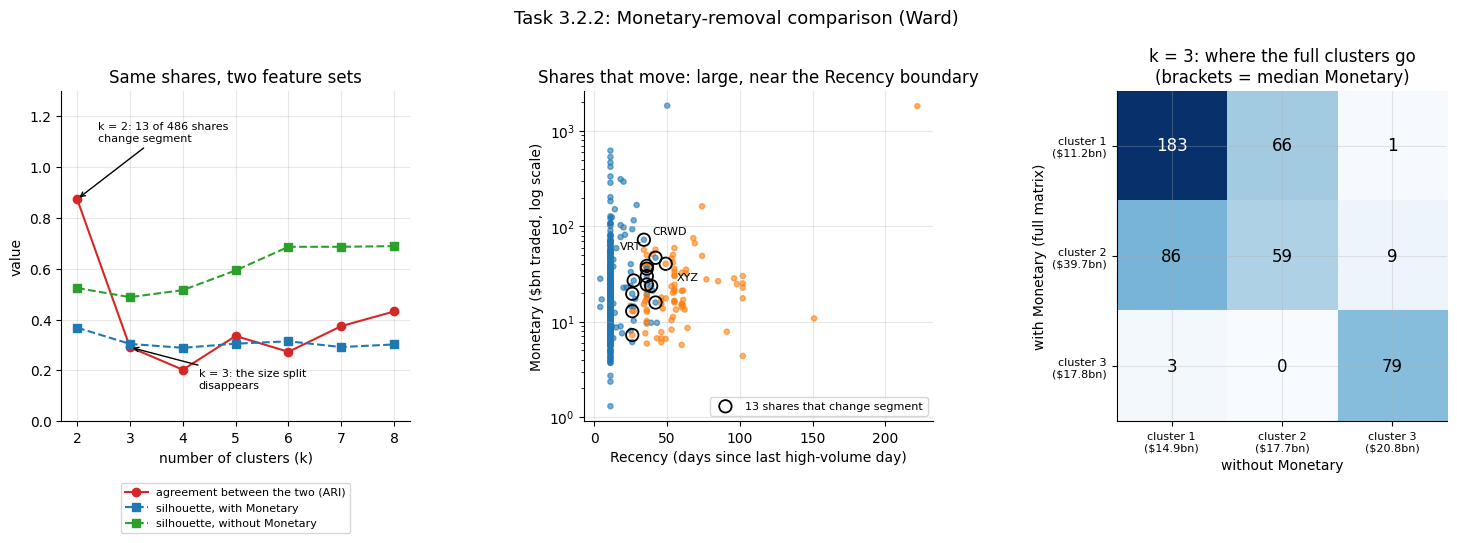

PASSED: the scatter highlights exactly the 13 shares that change segment
PASSED: the k = 3 heat map shows all 486 shares


True

In [ ]:
# TASK 3.2.2 | Part C: figure of what removing Monetary changes
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), gridspec_kw={"wspace": 0.5})

ax = axes[0]
ax.plot(rm.index, rm["ARI_full_vs_without_Monetary"], "o-", color="tab:red", label="agreement between the two (ARI)")
ax.plot(rm.index, rm["silhouette_full"], "s--", color="tab:blue", label="silhouette, with Monetary")
ax.plot(rm.index, rm["silhouette_without_Monetary"], "s--", color="tab:green", label="silhouette, without Monetary")
ax.set(xlabel="number of clusters (k)", ylabel="value", title="Same shares, two feature sets", ylim=(0, 1.3))
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17))
ax.annotate("k = 2: 13 of 486 shares\nchange segment", (2, 0.873), xytext=(2.4, 1.1), fontsize=8, arrowprops=dict(arrowstyle="->"))
ax.annotate("k = 3: the size split\ndisappears", (3, 0.291), xytext=(4.3, 0.13), fontsize=8, arrowprops=dict(arrowstyle="->"))

ax = axes[1]
x, y = feature_table["recency_days"], feature_table["monetary_usd"] / 1e9
cols = full2.map({1: "tab:blue", 2: "tab:orange"})
ax.scatter(x, y, c=cols.loc[x.index], s=14, alpha=0.6)
ax.scatter(x.loc[movers.index], y.loc[movers.index], facecolors="none", edgecolors="black", s=80, lw=1.3, label="13 shares that change segment")
for t, off in {"CRWD": (6, 4), "VRT": (-26, 6), "XYZ": (8, -12)}.items():
    ax.annotate(t, (x[t], y[t]), xytext=off, textcoords="offset points", fontsize=8)
ax.set_yscale("log")
ax.set(xlabel="Recency (days since last high-volume day)", ylabel="Monetary ($bn traded, log scale)", title="Shares that move: large, near the Recency boundary")
ax.legend(fontsize=8, loc="lower right")

ax = axes[2]
im = ax.imshow(tab3.to_numpy(), cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, tab3.iat[i, j], ha="center", va="center", fontsize=12, color="white" if tab3.iat[i, j] > 100 else "black")
mf = (feature_table["monetary_usd"] / 1e9).groupby(full3).median()
mr = (feature_table["monetary_usd"] / 1e9).groupby(red3).median()
ax.set_xticks(range(3)); ax.set_xticklabels([f"cluster {c}\n(${mr[c]:.1f}bn)" for c in tab3.columns], fontsize=8)
ax.set_yticks(range(3)); ax.set_yticklabels([f"cluster {c}\n(${mf[c]:.1f}bn)" for c in tab3.index], fontsize=8)
ax.set(xlabel="without Monetary", ylabel="with Monetary (full matrix)", title="k = 3: where the full clusters go\n(brackets = median Monetary)")
fig.suptitle("Task 3.2.2: Monetary-removal comparison (Ward)", fontsize=13)
fig.subplots_adjust(top=0.84, bottom=0.27)
save_fig("fig32_task322_monetary_removal")
plt.show()

check("the scatter highlights exactly the 13 shares that change segment", len(movers) == 13 and set(movers.index) <= set(x.index))
check("the k = 3 heat map shows all 486 shares", int(tab3.to_numpy().sum()) == 486)

In [ ]:
# TASK 3.2.2 | Part D: which features stay stable over time? Each feature in two non-overlapping periods, same 486 shares
f_ = m_fact[["date_key", "share_key", "traded_value_usd", "high_volume_flag"]].copy()
sess = m_date.set_index("date_key")["session_no"]
f_["session"] = f_["date_key"].map(sess)
date_of = m_date.set_index("session_no")["date"]
tick_of = m_share.set_index("share_key")["ticker"]

def rfm_window(end_session, length=60):
    w = f_[(f_["session"] > end_session - length) & (f_["session"] <= end_session)]
    last_event = f_[(f_["session"] <= end_session) & f_["high_volume_flag"]].groupby("share_key")["session"].max()
    out = pd.DataFrame({"recency_days": (date_of[end_session] - last_event.map(date_of)).dt.days,
                        "frequency_60d": w.groupby("share_key")["high_volume_flag"].sum(),
                        "log1p_monetary": np.log1p(w.groupby("share_key")["traded_value_usd"].sum())})
    return out.rename(index=tick_of).loc[feature_table.index]

final_end = int(sess.max())
B = rfm_window(final_end)
A = rfm_window(final_end - 60)                                                  # the 60 sessions just before the final window
check("the final window rebuilt from the mart equals the Task 1 Recency, Frequency and Monetary", (B["recency_days"] == feature_table["recency_days"]).all()
      and (B["frequency_60d"] == feature_table["frequency_60d"]).all() and np.allclose(B["log1p_monetary"], feature_table["log1p_monetary"]))
check("the earlier window is the previous 60 sessions and does not overlap the final window", date_of[final_end - 60] < WIN[0] and date_of[final_end - 119] < date_of[final_end - 60])
check("no share is missing a value in the earlier window", A.notna().all().all())

wk = weekly_ret[included]
bm = weekly_ret[BENCH]
def beta_of(idx):
    return wk.loc[idx].apply(lambda s: s.cov(bm.loc[idx]) / bm.loc[idx].var())
check("the beta function reproduces the Task 1 weekly beta on all 207 weeks", np.allclose(beta_of(wk.index), feature_table["weekly_beta"].loc[included]))
h1, h2 = wk.index[:103], wk.index[103:]
check("the two halves of the weekly data do not overlap and cover all 207 weeks", len(h1) + len(h2) == 207 and not set(h1) & set(h2))

periods = {"weekly return": (wk.loc[h1].mean(), wk.loc[h2].mean(), "weeks 1-103 vs 104-207"), "beta": (beta_of(h1), beta_of(h2), "weeks 1-103 vs 104-207"),
           "frequency": (A["frequency_60d"], B["frequency_60d"], "previous vs final 60 sessions"), "recency": (A["recency_days"], B["recency_days"], "previous vs final 60 sessions"),
           "monetary (log)": (A["log1p_monetary"], B["log1p_monetary"], "previous vs final 60 sessions")}
rows = []
for name, (p1, p2, desc) in periods.items():
    x, y = p1.loc[feature_table.index].to_numpy(float), p2.loc[feature_table.index].to_numpy(float)
    rx, ry = pd.Series(x).rank().to_numpy(), pd.Series(y).rank().to_numpy()
    lo, hi = boot_ci(rx, ry)
    rows.append({"feature": name, "periods compared": desc, "pearson": np.corrcoef(x, y)[0, 1], "spearman": np.corrcoef(rx, ry)[0, 1], "spearman_95%_low": lo, "spearman_95%_high": hi})
persist = pd.DataFrame(rows).set_index("feature")
check("every Spearman estimate lies inside its bootstrap interval", ((persist["spearman"] >= persist["spearman_95%_low"]) & (persist["spearman"] <= persist["spearman_95%_high"])).all())

print("How well does a share keep its position between two non-overlapping periods? (correlation across the 486 shares)")
print(persist.round(2).to_string())

PASSED: the final window rebuilt from the mart equals the Task 1 Recency, Frequency and Monetary
PASSED: the earlier window is the previous 60 sessions and does not overlap the final window
PASSED: no share is missing a value in the earlier window
PASSED: the beta function reproduces the Task 1 weekly beta on all 207 weeks
PASSED: the two halves of the weekly data do not overlap and cover all 207 weeks
PASSED: every Spearman estimate lies inside its bootstrap interval
How well does a share keep its position between two non-overlapping periods? (correlation across the 486 shares)
                             periods compared  pearson  spearman  spearman_95%_low  spearman_95%_high
feature                                                                                              
weekly return          weeks 1-103 vs 104-207    -0.30     -0.14             -0.24              -0.05
beta                   weeks 1-103 vs 104-207     0.78      0.80              0.76               0.83
freque

/tmp/ipykernel_1460/109386019.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


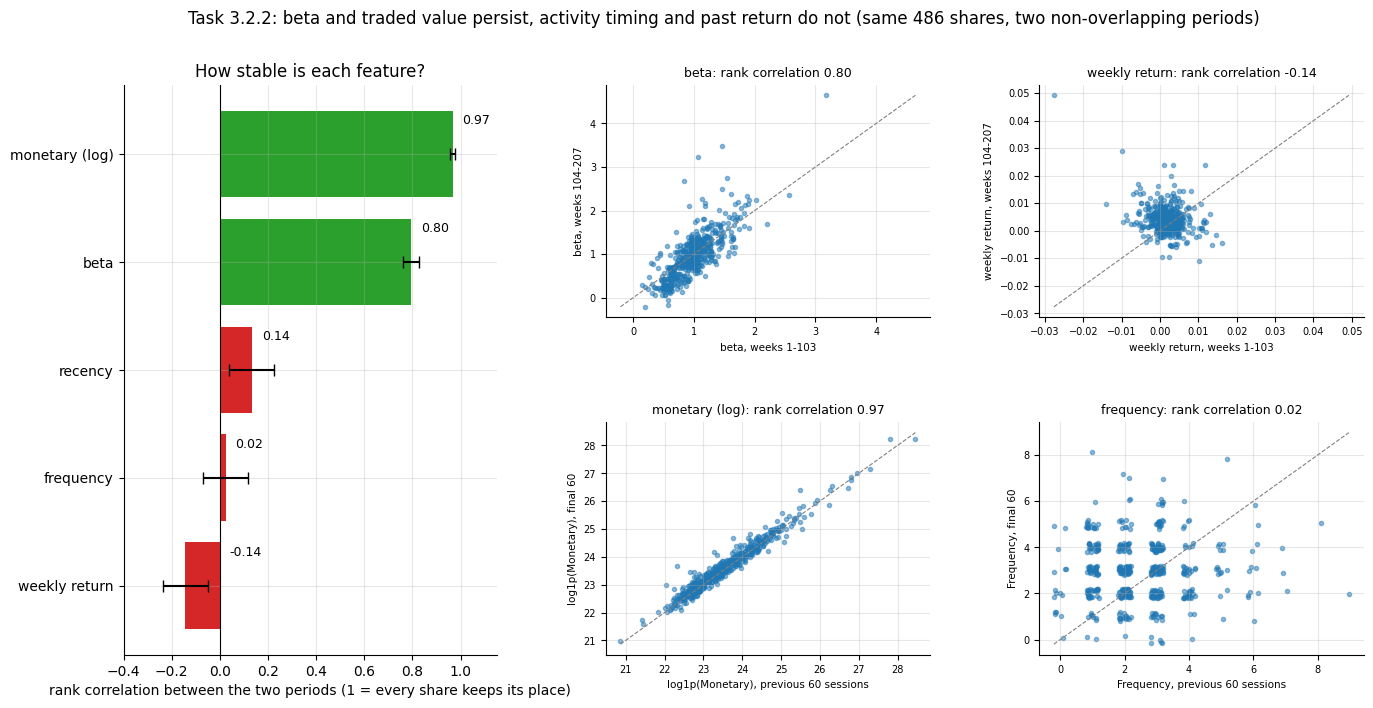

PASSED: the figure shows the five features compared in the table above
PASSED: the bar chart values are the Spearman correlations from the table


True

In [ ]:
# TASK 3.2.2 | Part E: figure of which features stay stable over time
fig = plt.figure(figsize=(16, 7.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1.15, 1, 1], wspace=0.32, hspace=0.45)

ax = fig.add_subplot(gs[:, 0])
order_ = persist["spearman"].sort_values().index
sp = persist.loc[order_]
colors_ = np.where(sp["spearman"] >= 0.5, "tab:green", np.where(sp["spearman"] >= 0.2, "tab:orange", "tab:red"))
ax.barh(sp.index, sp["spearman"], color=colors_, xerr=[sp["spearman"] - sp["spearman_95%_low"], sp["spearman_95%_high"] - sp["spearman"]], capsize=4)
ax.axvline(0, color="black", lw=0.8)
for y_, v_ in enumerate(sp["spearman"]):
    ax.text(max(v_, 0) + 0.04, y_ + 0.28, f"{v_:.2f}", fontsize=9)
ax.set(xlim=(-0.4, 1.15), xlabel="rank correlation between the two periods (1 = every share keeps its place)", title="How stable is each feature?")

panels = [("beta", "beta, weeks 1-103", "beta, weeks 104-207", gs[0, 1]), ("weekly return", "weekly return, weeks 1-103", "weekly return, weeks 104-207", gs[0, 2]),
          ("monetary (log)", "log1p(Monetary), previous 60 sessions", "log1p(Monetary), final 60", gs[1, 1]), ("frequency", "Frequency, previous 60 sessions", "Frequency, final 60", gs[1, 2])]
rng = np.random.default_rng(SEED)
for name, xl, yl, pos in panels:
    ax = fig.add_subplot(pos)
    p1, p2, _ = periods[name]
    x, y = p1.loc[feature_table.index].to_numpy(float), p2.loc[feature_table.index].to_numpy(float)
    if name == "frequency":
        x, y = x + rng.uniform(-0.2, 0.2, len(x)), y + rng.uniform(-0.2, 0.2, len(y))              # jitter: Frequency is a small whole number
    ax.scatter(x, y, s=9, alpha=0.5, color="tab:blue")
    lim = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lim, lim, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{name}: rank correlation {persist.at[name, 'spearman']:.2f}", fontsize=9)
    ax.set_xlabel(xl, fontsize=7.5); ax.set_ylabel(yl, fontsize=7.5); ax.tick_params(labelsize=7)
fig.suptitle("Task 3.2.2: beta and traded value persist, activity timing and past return do not (same 486 shares, two non-overlapping periods)", fontsize=12)
fig.subplots_adjust(top=0.88, bottom=0.12)
save_fig("fig33_task322_feature_stability")
plt.show()

check("the figure shows the five features compared in the table above", list(persist.index.sort_values()) == sorted(["weekly return", "beta", "frequency", "recency", "monetary (log)"]))
check("the bar chart values are the Spearman correlations from the table", np.allclose(sp["spearman"], persist.loc[order_, "spearman"]))

In [ ]:
# TASK 3.2.3 | Part A: return dependencies - shares do not move independently, so clusters of them are not independent bets
R = weekly_ret[included]
Cm = R.corr().to_numpy()                                      # 486 x 486 correlation of weekly returns
n = Cm.shape[0]
iu = np.triu_indices(n, 1)
avg_corr = Cm[iu].mean()
n_eff = n / (1 + (n - 1) * avg_corr)                          # how many independent shares the 486 are worth, if all pairs had the average correlation
eig = np.linalg.eigvalsh(Cm)[::-1]
pc1 = eig[0] / eig.sum()

groupings = {"sector (11)": feature_table["sector"], "Matrix 1 k=2": ward_final[("M1", 2)], "Matrix 1 k=5": ward_final[("M1", 5)],
             "Matrix 2 k=2": ward_final[("M2", 2)], "Matrix 2 k=3": ward_final[("M2", 3)]}
def within_between(codes):
    H = np.eye(codes.max() + 1)[codes]                         # one-hot membership
    pairs_in = ((H.T @ Cm @ H).trace() - n) / 2               # sum of correlations over pairs inside the same group
    n_in = (H.sum(0) * (H.sum(0) - 1) / 2).sum()
    tot, n_tot = (Cm.sum() - n) / 2, n * (n - 1) / 2
    return pairs_in / n_in, (tot - pairs_in) / (n_tot - n_in)

rng = np.random.default_rng(SEED)
rows = []
for name, lab in groupings.items():
    codes = pd.Categorical(lab.loc[R.columns]).codes.astype(int)
    w, b = within_between(codes)
    null = np.array([within_between(rng.permutation(codes))[0] for _ in range(1000)])       # within-group correlation if groups were random
    rows.append({"grouping": name, "within_group_corr": w, "between_group_corr": b, "random_groups_95%_range": f"{np.percentile(null, 2.5):.3f} to {np.percentile(null, 97.5):.3f}",
                 "p_permutation": (1 + (null >= w).sum()) / 1001})
dep = pd.DataFrame(rows).set_index("grouping")

check("the correlation matrix is symmetric with 1 on the diagonal", np.allclose(Cm, Cm.T) and np.allclose(np.diag(Cm), 1))
check("average pairwise correlation equals the mean of all off-diagonal entries", np.isclose(avg_corr, (Cm.sum() - n) / (n * (n - 1))))
check("eigenvalues add up to the number of shares (trace of a correlation matrix)", np.isclose(eig.sum(), n))
members = ward_final[("M1", 5)].loc[R.columns]
small = np.where(members.to_numpy() == 5)[0]                  # the 48-share cluster, checked pair by pair
manual = np.mean([Cm[i, j] for a, i in enumerate(small) for j in small[a + 1:]])
check("hand calculation: within-cluster correlation of the 48-share Matrix 1 cluster, pair by pair", np.isclose(manual, (Cm[np.ix_(small, small)].sum() - len(small)) / (len(small) * (len(small) - 1))))
codes5 = pd.Categorical(members).codes.astype(int)
check("the matrix formula gives the same within-group figure as the pair-by-pair loop for all five Matrix 1 clusters",
      np.isclose(within_between(codes5)[0], np.sum([Cm[np.ix_(np.where(codes5 == c)[0], np.where(codes5 == c)[0])].sum() - (codes5 == c).sum() for c in range(5)]) / sum((codes5 == c).sum() * ((codes5 == c).sum() - 1) for c in range(5))))
check("random groups of the same sizes average the all-share correlation (the null is centred correctly)",
      abs(np.mean([within_between(rng.permutation(codes5))[0] for _ in range(300)]) - avg_corr) < 0.01)

print(f"Average correlation between two shares' weekly returns: {avg_corr:.3f}")
print(f"Effective number of independent shares: {n_eff:.1f} of {n} | the first common factor (the market) explains {100 * pc1:.1f}% of all weekly return variation\n")
print(dep.round(3).to_string())

PASSED: the correlation matrix is symmetric with 1 on the diagonal
PASSED: average pairwise correlation equals the mean of all off-diagonal entries
PASSED: eigenvalues add up to the number of shares (trace of a correlation matrix)
PASSED: hand calculation: within-cluster correlation of the 48-share Matrix 1 cluster, pair by pair
PASSED: the matrix formula gives the same within-group figure as the pair-by-pair loop for all five Matrix 1 clusters
PASSED: random groups of the same sizes average the all-share correlation (the null is centred correctly)
Average correlation between two shares' weekly returns: 0.300
Effective number of independent shares: 3.3 of 486 | the first common factor (the market) explains 31.7% of all weekly return variation

              within_group_corr  between_group_corr random_groups_95%_range  p_permutation
grouping                                                                                  
sector (11)               0.414               0.285          0.2

In [ ]:
# TASK 3.2.3 | Part B: price-adjustment assumption - do the clusters change if Close is used instead of Adj Close (or the other way round)?
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

def weekly_returns_from(px):                                           # same recipe as Task 1.2: last trading day of each Friday-ending week
    return px.resample("W-FRI").last().pct_change().loc[weekly_ret.index]
r_adj = weekly_returns_from(a_inc)
r_close = weekly_returns_from(c_inc)
bench_r = weekly_ret[BENCH]
def beta_from(r):
    return r.apply(lambda s: s.cov(bench_r) / bench_r.var())
def m1_matrix(r):
    return pd.DataFrame({"mean_weekly_return": r.mean(), "weekly_beta": beta_from(r)}).loc[feature_table.index]
unadjusted = (a_inc == c_inc).all()                                    # shares whose Adj Close never differs from Close (no dividend or spin-off adjustment)
check("Adj Close weekly returns rebuilt here equal the Task 1.2 weekly returns", np.allclose(r_adj[included].to_numpy(), weekly_ret[included].to_numpy()))
check("for shares with no price adjustment, Close and Adj Close weekly returns are identical (so any difference comes only from the adjustment)", np.allclose(r_close.loc[:, unadjusted].to_numpy(), r_adj.loc[:, unadjusted].to_numpy()))
check("the Adj Close feature matrix equals the Task 1 feature table", np.allclose(m1_matrix(r_adj).to_numpy(), feature_table[["mean_weekly_return", "weekly_beta"]].to_numpy()))

def ward_labels(X, k):
    return fcluster(linkage(StandardScaler().fit_transform(X), "ward"), k, "maxclust")
def moved(base, new):                                                   # shares outside the best one-to-one match between the two clusterings
    t = pd.crosstab(base, new).to_numpy()
    r_, c_ = linear_sum_assignment(-t)
    return int(t.sum() - t[r_, c_].sum())

rows = []
M1_adj, M1_close = m1_matrix(r_adj), m1_matrix(r_close)
for k in (2, 5):
    base = ward_final[("M1", k)].loc[feature_table.index].to_numpy()
    check(f"Matrix 1 k={k}: re-running Ward on the Adj Close features reproduces the stored clusters (ARI = 1)", adjusted_rand_score(base, ward_labels(M1_adj, k)) == 1)
    new = ward_labels(M1_close, k)
    rows.append({"matrix": "Matrix 1 (return, beta)", "change": "returns from Close instead of Adj Close", "k": k, "ARI_vs_baseline": adjusted_rand_score(base, new), "shares_that_move": moved(base, new)})
mon_adj = np.log1p((a_inc * v_inc).loc[WIN].sum())                      # traded value valued at Adj Close instead of Close
M2_alt = feature_table[["recency_days", "frequency_60d"]].assign(log1p_monetary=mon_adj.loc[feature_table.index])
M2_base = feature_table[["recency_days", "frequency_60d", "log1p_monetary"]]
for k in (2, 3):
    base = ward_final[("M2", k)].loc[feature_table.index].to_numpy()
    check(f"Matrix 2 k={k}: re-running Ward on the Close-based Monetary reproduces the stored clusters (ARI = 1)", adjusted_rand_score(base, ward_labels(M2_base, k)) == 1)
    new = ward_labels(M2_alt, k)
    rows.append({"matrix": "Matrix 2 (R, F, Monetary)", "change": "Monetary valued at Adj Close x Volume", "k": k, "ARI_vs_baseline": adjusted_rand_score(base, new), "shares_that_move": moved(base, new)})
price_basis = pd.DataFrame(rows)

# yardstick: how much do Matrix 1 clusters change just from sampling noise (resampling the 207 weeks, 200 times)?
Rm, bm_ = r_adj[feature_table.index].to_numpy(), bench_r.to_numpy()
def boot_features(idx):
    r, b = Rm[idx], bm_[idx]
    beta = ((r - r.mean(0)) * (b - b.mean())[:, None]).sum(0) / ((b - b.mean()) ** 2).sum()
    return np.column_stack([r.mean(0), beta])
check("the resampling code gives the Task 1 features when every week is used once", np.allclose(boot_features(np.arange(len(bm_))), feature_table[["mean_weekly_return", "weekly_beta"]].to_numpy()))
rng = np.random.default_rng(SEED)
boot = {k: [] for k in (2, 5)}
for _ in range(200):
    X = boot_features(rng.integers(0, len(bm_), len(bm_)))
    for k in boot:
        boot[k].append(adjusted_rand_score(ward_final[("M1", k)].loc[feature_table.index].to_numpy(), ward_labels(X, k)))
for k, v in boot.items():
    rows.append({"matrix": "Matrix 1 (return, beta)", "change": "yardstick: resample the 207 weeks (median of 200)", "k": k, "ARI_vs_baseline": np.median(v), "shares_that_move": np.nan})
price_basis = pd.DataFrame(rows)
price_basis["shares_that_move"] = price_basis["shares_that_move"].astype("Int64")

d_ret = 100 * (r_adj.mean() - r_close.mean())[included]
payers = ~unadjusted
print("Mean weekly return, Adj Close minus Close (percentage points per week):")
print(f"  adjusted shares (n={int(payers.sum())}): median {d_ret[payers].median():.3f}, max {d_ret[payers].max():.3f} | unadjusted shares (n={int(unadjusted.sum())}): max absolute difference {d_ret[unadjusted].abs().max():.6f}")
print(f"Beta, Close versus Adj Close basis: correlation {np.corrcoef(M1_close['weekly_beta'], M1_adj['weekly_beta'])[0, 1]:.4f}\n")
print(price_basis.round(3).to_string(index=False))
print("\nResampling the weeks, 5th to 95th percentile of ARI:", {k: f"{np.percentile(v, 5):.2f} to {np.percentile(v, 95):.2f}" for k, v in boot.items()})

PASSED: Adj Close weekly returns rebuilt here equal the Task 1.2 weekly returns
PASSED: for shares with no price adjustment, Close and Adj Close weekly returns are identical (so any difference comes only from the adjustment)
PASSED: the Adj Close feature matrix equals the Task 1 feature table
PASSED: Matrix 1 k=2: re-running Ward on the Adj Close features reproduces the stored clusters (ARI = 1)
PASSED: Matrix 1 k=5: re-running Ward on the Adj Close features reproduces the stored clusters (ARI = 1)
PASSED: Matrix 2 k=2: re-running Ward on the Close-based Monetary reproduces the stored clusters (ARI = 1)
PASSED: Matrix 2 k=3: re-running Ward on the Close-based Monetary reproduces the stored clusters (ARI = 1)
PASSED: the resampling code gives the Task 1 features when every week is used once
Mean weekly return, Adj Close minus Close (percentage points per week):
  adjusted shares (n=398): median 0.040, max 0.152 | unadjusted shares (n=88): max absolute difference 0.000000
Beta, Close ver

In [ ]:
# TASK 3.2.3 | Part C: survivorship and selection bias - the 486 shares are today's index members, so who joined the index after the study started?
from scipy.stats import mannwhitneyu, rankdata, fisher_exact
joined = pd.to_datetime(dim_share.set_index("ticker")["date_added_to_index"]).loc[feature_table.index]
start, end = pd.Timestamp(info["study_start"]), pd.Timestamp(info["study_end_exclusive"])
when = pd.Series(np.where(joined < start, "joined before 2021", np.where(joined < end, "joined 2021-2024", "joined 2025 or later")), index=feature_table.index)
order = ["joined before 2021", "joined 2021-2024", "joined 2025 or later"]
check("the three groups cover all 486 shares", when.isin(order).all() and len(when) == 486)
check("group sizes reproduce Task 1.1 Part C (414 / 47 / 25)", when.value_counts().reindex(order).tolist() == [414, 47, 25])

ft = feature_table.assign(group=when, return_pct=100 * feature_table["mean_weekly_return"], monetary_bn=feature_table["monetary_usd"] / 1e9)
cols = ["return_pct", "weekly_beta", "monetary_bn", "frequency_60d", "recency_days"]
rng = np.random.default_rng(SEED)
rows = []
for g in order:
    sub = ft[ft["group"] == g]
    row = {"group": g, "shares": len(sub)}
    for c in cols:
        row[f"median {c}"] = sub[c].median()
    rows.append(row)
profile_by_join = pd.DataFrame(rows).set_index("group")

tests = []
base = ft[ft["group"] == order[0]]
for g in order[1:]:
    sub = ft[ft["group"] == g]
    for c in ["return_pct", "weekly_beta", "monetary_bn"]:
        u, p = mannwhitneyu(sub[c], base[c], alternative="two-sided")
        diffs = [np.median(rng.choice(sub[c].to_numpy(), len(sub))) - np.median(rng.choice(base[c].to_numpy(), len(base))) for _ in range(2000)]
        tests.append({"group": g, "feature": c, "median_difference_vs_before_2021": sub[c].median() - base[c].median(),
                      "95%_interval": f"{np.percentile(diffs, 2.5):.3f} to {np.percentile(diffs, 97.5):.3f}", "p_mann_whitney": p})
tests = pd.DataFrame(tests)

sub = ft[ft["group"] == order[2]]
x, y = sub["return_pct"].to_numpy(), base["return_pct"].to_numpy()
r_all = rankdata(np.concatenate([x, y]))
u_hand = r_all[:len(x)].sum() - len(x) * (len(x) + 1) / 2
check("hand calculation: the Mann-Whitney statistic for 'joined 2025 or later' return equals the rank-sum formula", np.isclose(u_hand, mannwhitneyu(x, y).statistic))

hi_beta = ward_final[("M1", 2)].loc[ft.index] == 2                      # the 92-share higher-beta, higher-return cluster
tab = pd.crosstab(when.rename("joined the index"), hi_beta.map({True: "yes", False: "no"}).rename("in higher-beta cluster")).reindex(order)
tab["% in higher-beta cluster"] = 100 * tab["yes"] / (tab["yes"] + tab["no"])
_, p_fisher = fisher_exact([[tab.loc[order[2], "yes"], tab.loc[order[2], "no"]], [tab.loc[order[0], "yes"], tab.loc[order[0], "no"]]])
check("the cross-table covers all 486 shares", int(tab[["no", "yes"]].to_numpy().sum()) == 486)

print("Median feature by when the share joined the S&P 500 (units: return in % per week, Monetary in $bn):"); print(profile_by_join.round(2).to_string())
print("\nDifference from shares that joined before 2021 (two-sided Mann-Whitney test, bootstrap interval for the median difference):"); print(tests.round(3).to_string(index=False))
print("\nShare of each group that sits in the higher-beta, higher-return Matrix 1 cluster (k=2):"); print(tab.round(1).to_string())
print(f"Joined 2025 or later against joined before 2021, Fisher exact p = {p_fisher:.3f}")

PASSED: the three groups cover all 486 shares
PASSED: group sizes reproduce Task 1.1 Part C (414 / 47 / 25)
PASSED: hand calculation: the Mann-Whitney statistic for 'joined 2025 or later' return equals the rank-sum formula
PASSED: the cross-table covers all 486 shares
Median feature by when the share joined the S&P 500 (units: return in % per week, Monetary in $bn):
                      shares  median return_pct  median weekly_beta  median monetary_bn  median frequency_60d  median recency_days
group                                                                                                                             
joined before 2021       414               0.25                0.93               16.80                   3.0                 11.0
joined 2021-2024          47               0.44                1.20               18.89                   3.0                 11.0
joined 2025 or later      25               0.45                1.44               14.44                   4

In [ ]:
# TASK 3.2.3 | Part D: liquidity-proxy limits - how good a stand-in for liquidity is Monetary (Close x Volume), and what distorts it?
win_keys = m_date.loc[m_date["in_final_60_session_window"], "date_key"]
w = m_fact[m_fact["date_key"].isin(win_keys)].copy()
w["ticker"] = w["share_key"].map(tick_of)
w["abs_ret_per_usd"] = w["daily_return"].abs() / w["traded_value_usd"]                  # Amihud-style price impact: price move per dollar traded
amihud = w.groupby("ticker")["abs_ret_per_usd"].mean().loc[feature_table.index] * 1e9
monetary = feature_table["monetary_usd"]

breadth = m_fact.groupby("date_key")["high_volume_flag"].mean()
market_days = breadth[breadth > 0.30].index                                            # days when more than 30% of shares were flagged (Task 1.4)
in_win_market = [d for d in market_days if d in set(win_keys)]
w_ex = w[~w["date_key"].isin(market_days)]
monetary_ex = w_ex.groupby("ticker")["traded_value_usd"].sum().loc[feature_table.index]
share_on_market_days = 1 - monetary_ex / monetary

sp = lambda a, b: pd.Series(a).rank().corr(pd.Series(b).rank())
rx, ry = monetary.rank().to_numpy(), amihud.rank().to_numpy()
lo, hi = boot_ci(rx, ry)
top10 = monetary.nlargest(10).sum() / monetary.sum()
top5pct = monetary.nlargest(int(round(0.05 * len(monetary)))).sum() / monetary.sum()

check("days with more than 30% of shares flagged number 18 across the study (as in Task 1.4)", len(market_days) == 18)
check("Monetary rebuilt from the mart equals the feature table", np.allclose(w.groupby("ticker")["traded_value_usd"].sum().loc[feature_table.index], monetary))
t0 = feature_table.index[0]
manual = np.mean([abs(r) / v for r, v in zip(w.loc[w["ticker"] == t0, "daily_return"], w.loc[w["ticker"] == t0, "traded_value_usd"])]) * 1e9
check("hand calculation: the Amihud measure of the first share equals the day-by-day average", np.isclose(manual, amihud[t0]))
check("excluding the market-wide days can only lower each share's Monetary", ((monetary_ex <= monetary + 1e-6).all()))
check("every share still has traded value left after excluding the market-wide days", (monetary_ex > 0).all())
check("Spearman estimate lies inside its bootstrap interval", lo <= sp(monetary, amihud) <= hi)

print(f"Monetary against the Amihud price-impact measure (higher Amihud = less liquid): Spearman {sp(monetary, amihud):.2f} (95% interval {lo:.2f} to {hi:.2f})")
print(f"Window days with more than 30% of shares flagged: {[str(d_) for d_ in m_date.set_index('date_key').loc[in_win_market, 'date'].dt.date]} of the 60")
print(f"Share of a share's window traded value that falls on those days: median {100 * share_on_market_days.median():.1f}%, largest {100 * share_on_market_days.max():.1f}%")
print(f"Rank correlation of Monetary with Monetary excluding those days: {sp(monetary, monetary_ex):.3f}")
print(f"Concentration: the 10 most traded shares account for {100 * top10:.1f}% of all Monetary, the top 5% of shares for {100 * top5pct:.1f}%")
print("Ten largest by Monetary ($bn):", {t: round(v / 1e9, 0) for t, v in monetary.nlargest(10).items()})

PASSED: days with more than 30% of shares flagged number 18 across the study (as in Task 1.4)
PASSED: Monetary rebuilt from the mart equals the feature table
PASSED: hand calculation: the Amihud measure of the first share equals the day-by-day average
PASSED: excluding the market-wide days can only lower each share's Monetary
PASSED: every share still has traded value left after excluding the market-wide days
PASSED: Spearman estimate lies inside its bootstrap interval
Monetary against the Amihud price-impact measure (higher Amihud = less liquid): Spearman -0.94 (95% interval -0.95 to -0.92)
Window days with more than 30% of shares flagged: ['2024-11-06', '2024-12-20'] of the 60
Share of a share's window traded value that falls on those days: median 6.9%, largest 34.1%
Rank correlation of Monetary with Monetary excluding those days: 0.999
Concentration: the 10 most traded shares account for 36.3% of all Monetary, the top 5% of shares for 46.1%
Ten largest by Monetary ($bn): {'TSLA': 18

In [ ]:
# TASK 3.2.3 | Part E: feature overlap - how much of each feature is already carried by the others, and where the features are linked by construction
five = ["mean_weekly_return", "weekly_beta", "recency_days", "frequency_60d", "log1p_monetary"]
def vif_table(cols):
    C = feature_table[cols].corr().to_numpy()
    return pd.Series(np.diag(np.linalg.inv(C)), index=cols)                               # variance inflation factor = 1 / (1 - R-squared of that feature on the others)
vif_five, vif_m2 = vif_table(five), vif_table(["recency_days", "frequency_60d", "log1p_monetary"])
def effective_dims(cols):
    ev = np.linalg.eigvalsh(feature_table[cols].corr().to_numpy())
    return ev.sum() ** 2 / (ev ** 2).sum()                                                 # 1 = everything is one feature, = number of features if all are independent
dims_five, dims_m2 = effective_dims(five), effective_dims(["recency_days", "frequency_60d", "log1p_monetary"])

# built-in link: Frequency counts high-volume days, and Monetary adds up traded value on every day, including those days
flag_val = w[w["high_volume_flag"]].groupby("ticker")["traded_value_usd"].sum().reindex(feature_table.index).fillna(0)
share_flagged_value = flag_val / feature_table["monetary_usd"]
link = pd.Series(share_flagged_value).rank().corr(feature_table["frequency_60d"].rank())

check("variance inflation factors are at least 1", (vif_five >= 1).all() and (vif_m2 >= 1).all())
y = feature_table["recency_days"].to_numpy(float)
X = np.column_stack([np.ones(486), feature_table[["frequency_60d", "log1p_monetary"]].to_numpy(float)])
resid = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
check("hand calculation: the variance inflation factor of Recency (Matrix 2) equals 1 / (1 - R-squared) from a regression", np.isclose(vif_m2["recency_days"], 1 / (1 - r2)))
check("effective dimensions lie between 1 and the number of features", 1 <= dims_m2 <= 3 and 1 <= dims_five <= 5)
check("share of window traded value on flagged days lies between 0 and 1", ((share_flagged_value >= 0) & (share_flagged_value <= 1)).all())
check("the window flags used here equal Frequency in the feature table", (w.groupby("ticker")["high_volume_flag"].sum().reindex(feature_table.index).fillna(0) == feature_table["frequency_60d"]).all())

print("Variance inflation (1 = no overlap; above 5 would be a concern):")
print(pd.DataFrame({"all five features": vif_five, "Matrix 2 only": vif_m2}).round(2).to_string())
print(f"\nEffective number of independent dimensions: Matrix 2 {dims_m2:.2f} of 3, all five features {dims_five:.2f} of 5")
print(f"Frequency counts high-volume days and Monetary adds up traded value on them: a share's flagged days carry a median {100 * share_flagged_value.median():.1f}% of its window Monetary; "
      f"rank correlation of that share with Frequency = {link:.2f}")

PASSED: variance inflation factors are at least 1
PASSED: hand calculation: the variance inflation factor of Recency (Matrix 2) equals 1 / (1 - R-squared) from a regression
PASSED: effective dimensions lie between 1 and the number of features
PASSED: share of window traded value on flagged days lies between 0 and 1
PASSED: the window flags used here equal Frequency in the feature table
Variance inflation (1 = no overlap; above 5 would be a concern):
                    all five features  Matrix 2 only
frequency_60d                    1.15           1.14
log1p_monetary                   1.14           1.03
mean_weekly_return               1.13            NaN
recency_days                     1.17           1.17
weekly_beta                      1.12            NaN

Effective number of independent dimensions: Matrix 2 2.74 of 3, all five features 4.37 of 5
Frequency counts high-volume days and Monetary adds up traded value on them: a share's flagged days carry a median 12.3% of its window 

In [ ]:
# TASK 3.2.3 | Part F: descriptive or predictive? Build return-and-beta clusters from the first half of the weeks only, then see what the clusters do in the second half
from scipy.stats import kruskal
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
wk = weekly_ret[included]; bm = weekly_ret[BENCH]
h1, h2 = wk.index[:103], wk.index[103:]
def feats(idx):
    r = wk.loc[idx]
    return pd.DataFrame({"mean_weekly_return": r.mean(), "weekly_beta": r.apply(lambda s: s.cov(bm.loc[idx]) / bm.loc[idx].var())})
F1, F2 = feats(h1), feats(h2)
R2, b2 = wk.loc[h2], bm.loc[h2]
ann = np.sqrt(52)
def port_stats(members):                                                # equal-weight portfolio of the given shares over the second half
    p = R2[members].mean(axis=1)
    beta = p.cov(b2) / b2.var()
    alpha = p.mean() - beta * b2.mean()                                   # return left over after the share of the market's move that the portfolio's beta explains
    resid = p - alpha - beta * b2
    se = resid.std(ddof=2) * np.sqrt(1 / len(p) + b2.mean() ** 2 / ((b2 - b2.mean()) ** 2).sum())
    return {"ret_%_per_week": 100 * p.mean(), "vol_%_annual": 100 * p.std() * ann, "beta": beta, "alpha_%_per_week": 100 * alpha, "alpha_t": alpha / se}

check("first half has 103 weeks, second half 104, together all 207, no overlap", len(h1) == 103 and len(h2) == 104 and not set(h1) & set(h2))
check("first-half and second-half features use the same beta recipe as Task 1 (full-period beta reproduced)", np.allclose(feats(wk.index)["weekly_beta"], feature_table["weekly_beta"].loc[included]))

rng = np.random.default_rng(SEED)
Wsel = lambda n_c: np.array([np.isin(np.arange(486), rng.choice(486, n_c, replace=False)) for _ in range(2000)], dtype=float) / n_c      # 2,000 random portfolios of the same size
all_stats = port_stats(list(included))
rows, lab_store, kw = [], {}, {}
for k in (2, 5):
    lab = pd.Series(fcluster(linkage(StandardScaler().fit_transform(F1), "ward"), k, "maxclust"), index=F1.index)
    order = F1["weekly_beta"].groupby(lab).median().sort_values().index                                  # label clusters from lowest to highest first-half beta
    lab_store[k] = lab.map({c: i + 1 for i, c in enumerate(order)})
    kw_ret = kruskal(*[F2.loc[lab_store[k] == c, "mean_weekly_return"] for c in range(1, k + 1)]).pvalue
    kw_beta = kruskal(*[F2.loc[lab_store[k] == c, "weekly_beta"] for c in range(1, k + 1)]).pvalue
    for c in range(1, k + 1):
        m = list(lab_store[k].index[lab_store[k] == c])
        s = port_stats(m)
        sel = Wsel(len(m)); P = sel @ R2.to_numpy().T                                           # random portfolios x second-half weeks
        vol_r, beta_r = P.std(axis=1, ddof=1) * ann * 100, ((P - P.mean(1, keepdims=True)) @ (b2.to_numpy() - b2.mean())) / ((len(b2) - 1) * b2.var())
        rows.append({"k": k, "cluster": c, "shares": len(m), "beta 1st half": F1.loc[m, "weekly_beta"].median(), "beta 2nd half": F2.loc[m, "weekly_beta"].median(),
                     "return %/wk": s["ret_%_per_week"], "volatility %/yr": s["vol_%_annual"], "portfolio beta": s["beta"],
                     "alpha %/wk": s["alpha_%_per_week"], "alpha t-stat": s["alpha_t"], "beta below x% of random": 100 * (beta_r > s["beta"]).mean()})
    kw[k] = (kw_ret, kw_beta)
oos = pd.DataFrame(rows)
check("cluster sizes add up to 486 for both k", all(oos.query("k == @k")["shares"].sum() == 486 for k in (2, 5)))
m0 = list(lab_store[5].index[lab_store[5] == 1])
manual_week = np.mean([R2.iloc[0][t] for t in m0])
check("hand calculation: the equal-weight portfolio return in the first second-half week equals the average of its members", np.isclose(R2[m0].mean(axis=1).iloc[0], manual_week))
chk = Wsel(10)
check("each random portfolio has equal weights adding up to 1", np.allclose(chk.sum(axis=1), 1) and (chk > 0).sum(axis=1).min() == 10)
pp = R2[m0].mean(axis=1)
check("hand calculation: the intercept of a straight-line fit of portfolio return on market return equals the alpha used here", np.isclose(np.polyfit(b2.to_numpy(), pp.to_numpy(), 1)[1], port_stats(m0)["alpha_%_per_week"] / 100))
check("the all-share portfolio is the average of all 486 shares each week", np.allclose(R2.mean(axis=1), R2[list(included)].mean(axis=1)))

print(f"Second half: the market (benchmark) returned {100 * b2.mean():.3f}%/week. All 486 shares, equal weight: return {all_stats['ret_%_per_week']:.3f}%/week, volatility {all_stats['vol_%_annual']:.1f}%/year, beta {all_stats['beta']:.2f}, alpha {all_stats['alpha_%_per_week']:.3f}%/week\n")
print(oos.round(3).to_string(index=False))
print("\nDo the clusters differ in second-half return per share (Kruskal-Wallis p)?  " + " | ".join(f"k={k}: return p={v[0]:.4f}, beta p={v[1]:.4f}" for k, v in kw.items()))

PASSED: first half has 103 weeks, second half 104, together all 207, no overlap
PASSED: first-half and second-half features use the same beta recipe as Task 1 (full-period beta reproduced)
PASSED: cluster sizes add up to 486 for both k
PASSED: hand calculation: the equal-weight portfolio return in the first second-half week equals the average of its members
PASSED: each random portfolio has equal weights adding up to 1
PASSED: hand calculation: the intercept of a straight-line fit of portfolio return on market return equals the alpha used here
PASSED: the all-share portfolio is the average of all 486 shares each week
Second half: the market (benchmark) returned 0.441%/week. All 486 shares, equal weight: return 0.393%/week, volatility 13.9%/year, beta 0.97, alpha -0.034%/week

 k  cluster  shares  beta 1st half  beta 2nd half  return %/wk  volatility %/yr  portfolio beta  alpha %/wk  alpha t-stat  beta below x% of random
 2        1     400          0.900          0.827        0.321    

/tmp/ipykernel_1460/109386019.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


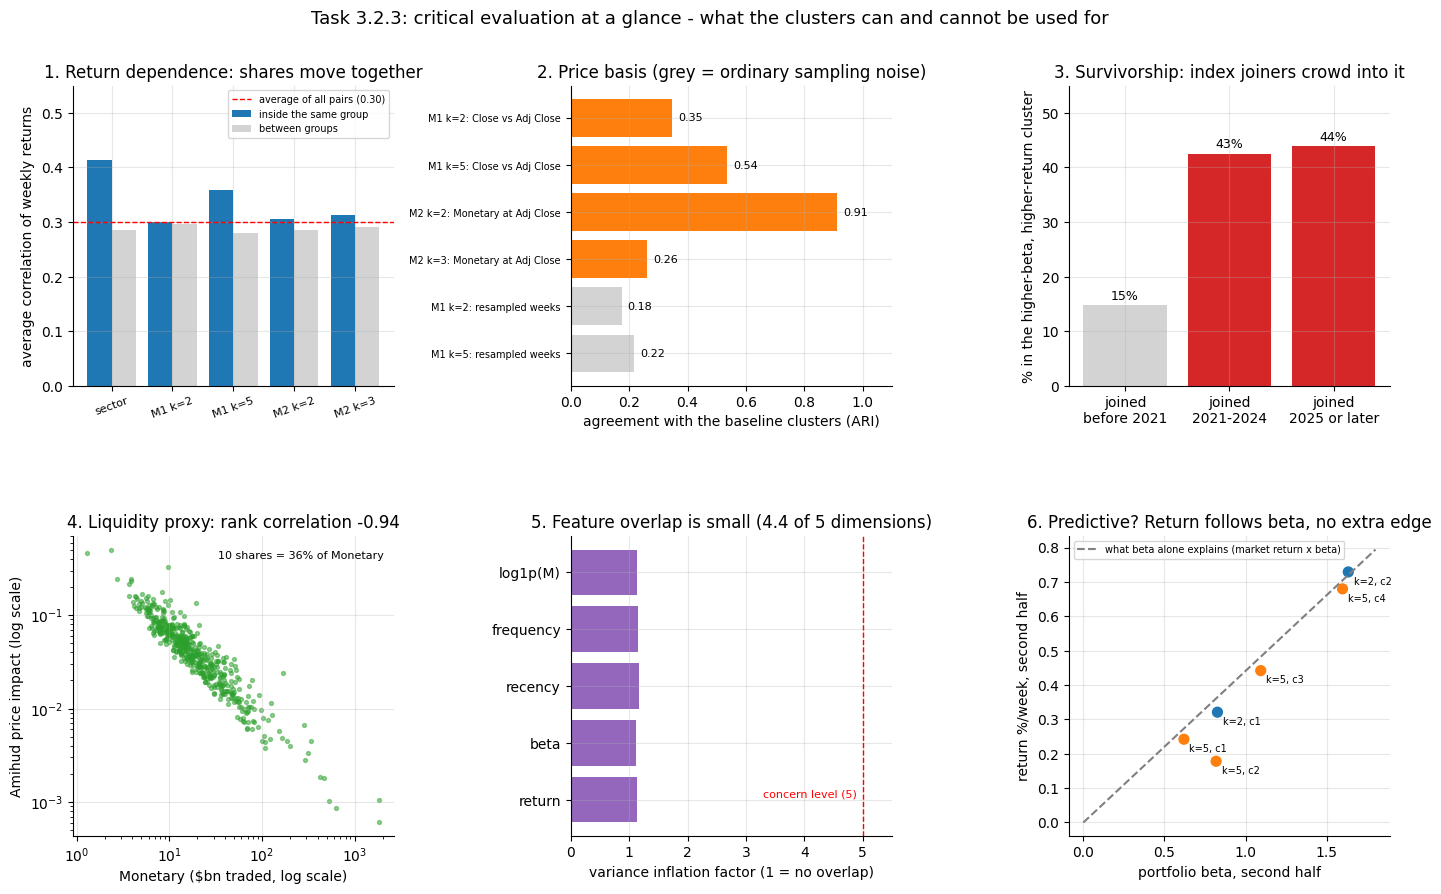

PASSED: panel 1 shows all five groupings, panel 2 all six comparisons, panel 3 all three join groups
PASSED: panel 6 leaves out the one-share cluster and keeps the other six clusters


True

In [ ]:
# TASK 3.2.3 | Part G: critical evaluation at a glance - one panel per limitation the brief names, built from the results above
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), gridspec_kw={"hspace": 0.5, "wspace": 0.55})

ax = axes[0, 0]                                                           # return dependencies
d_ = dep.reset_index()
x_ = np.arange(len(d_))
ax.bar(x_ - 0.2, d_["within_group_corr"], 0.4, label="inside the same group", color="tab:blue")
ax.bar(x_ + 0.2, d_["between_group_corr"], 0.4, label="between groups", color="lightgrey")
ax.axhline(avg_corr, color="red", ls="--", lw=1, label=f"average of all pairs ({avg_corr:.2f})")
ax.set_xticks(x_); ax.set_xticklabels([g.replace(" (11)", "").replace("Matrix ", "M") for g in d_["grouping"]], fontsize=8, rotation=20)
ax.set(ylim=(0, 0.55), ylabel="average correlation of weekly returns", title="1. Return dependence: shares move together")
ax.legend(fontsize=7, loc="upper right", ncol=1)

ax = axes[0, 1]                                                           # price adjustment
pb = price_basis.copy()
pb["label"] = ["M1 k=2: Close vs Adj Close", "M1 k=5: Close vs Adj Close", "M2 k=2: Monetary at Adj Close", "M2 k=3: Monetary at Adj Close", "M1 k=2: resampled weeks", "M1 k=5: resampled weeks"]
colors_pb = ["tab:orange"] * 4 + ["lightgrey"] * 2
ax.barh(pb["label"][::-1], pb["ARI_vs_baseline"][::-1], color=colors_pb[::-1])
for i_, v_ in enumerate(pb["ARI_vs_baseline"][::-1]):
    ax.text(v_ + 0.02, i_, f"{v_:.2f}", va="center", fontsize=8)
ax.set(xlim=(0, 1.1), xlabel="agreement with the baseline clusters (ARI)", title="2. Price basis (grey = ordinary sampling noise)")
ax.tick_params(axis="y", labelsize=7)

ax = axes[0, 2]                                                           # survivorship
ax.bar(["joined\nbefore 2021", "joined\n2021-2024", "joined\n2025 or later"], tab["% in higher-beta cluster"], color=["lightgrey", "tab:red", "tab:red"])
for i_, v_ in enumerate(tab["% in higher-beta cluster"]):
    ax.text(i_, v_ + 1, f"{v_:.0f}%", ha="center", fontsize=9)
ax.set(ylim=(0, 55), ylabel="% in the higher-beta, higher-return cluster", title="3. Survivorship: index joiners crowd into it")

ax = axes[1, 0]                                                           # liquidity proxy
ax.scatter(monetary / 1e9, amihud, s=8, alpha=0.5, color="tab:green")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set(xlabel="Monetary ($bn traded, log scale)", ylabel="Amihud price impact (log scale)", title=f"4. Liquidity proxy: rank correlation {sp(monetary, amihud):.2f}")
ax.text(0.97, 0.95, f"10 shares = {100 * top10:.0f}% of Monetary", transform=ax.transAxes, ha="right", va="top", fontsize=8)

ax = axes[1, 1]                                                           # feature overlap
v_ = vif_five.rename({"mean_weekly_return": "return", "weekly_beta": "beta", "recency_days": "recency", "frequency_60d": "frequency", "log1p_monetary": "log1p(M)"})
ax.barh(v_.index, v_.values, color="tab:purple")
ax.axvline(5, color="red", ls="--", lw=1); ax.text(4.9, 0.05, "concern level (5)", color="red", fontsize=8, ha="right")
ax.set(xlim=(0, 5.5), xlabel="variance inflation factor (1 = no overlap)", title=f"5. Feature overlap is small ({dims_five:.1f} of 5 dimensions)")

ax = axes[1, 2]                                                           # descriptive vs predictive
o_ = oos[oos["shares"] > 5]
mkt = 100 * b2.mean()
xs = np.linspace(0, 1.8, 10)
ax.plot(xs, xs * mkt, color="grey", ls="--", label="what beta alone explains (market return x beta)")
ax.scatter(o_["portfolio beta"], o_["return %/wk"], c=np.where(o_["k"] == 2, "tab:blue", "tab:orange"), s=50)
for _, r_ in o_.iterrows():
    ax.annotate(f"k={int(r_['k'])}, c{int(r_['cluster'])}", (r_["portfolio beta"], r_["return %/wk"]), xytext=(4, -9), textcoords="offset points", fontsize=7)
ax.set(xlabel="portfolio beta, second half", ylabel="return %/week, second half", title="6. Predictive? Return follows beta, no extra edge")
ax.legend(fontsize=7, loc="upper left")
fig.suptitle("Task 3.2.3: critical evaluation at a glance - what the clusters can and cannot be used for", fontsize=13)
fig.subplots_adjust(top=0.9)
save_fig("fig34_task323_critical_evaluation")
plt.show()

check("panel 1 shows all five groupings, panel 2 all six comparisons, panel 3 all three join groups", len(d_) == 5 and len(pb) == 6 and len(tab) == 3)
check("panel 6 leaves out the one-share cluster and keeps the other six clusters", len(o_) == 6 and o_["shares"].min() > 5)

In [ ]:
# FINAL | Back up and download all figures (the figures/ folder lives in the Colab runtime and is lost on reset)
import os, shutil
from google.colab import files

fig_files = sorted(os.listdir("figures"))
print(f"{len(fig_files)} figures found: {fig_files[0]} ... {fig_files[-1]}")
backup = os.path.join(os.path.dirname(DATA_DIR), "figures_backup")             # CWK1_snapshot/figures_backup in your Drive
shutil.copytree("figures", backup, dirs_exist_ok=True)
shutil.make_archive("figures_tasks1_2_3", "zip", "figures")
files.download("figures_tasks1_2_3.zip")

37 figures found: fig01_benchmark_level.png ... fig34_task323_critical_evaluation.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>